# Einstein-Net, paper 1: self-contained notebook for Google Colab

**Einstein-Net: Modelling Black Holes using Error-Bounded Neural Networks** (Hassan Ugail, 2026), version 2.2 with the rigorous Taylor-model certificate (validated elementary functions, no library assumption), the two-thousand-case calibration, the cost model and the differentiability demonstration. This single notebook contains the whole library, the trained weights, the reference tables and every experiment of the paper, including the companion black-hole notebook and the revision analysis, so it runs on a fresh Colab session with no repository access. Run the cells in order. Runtime type can be CPU (two cores suffice; a GPU is not used).

The switches below control what is recomputed. With the defaults everything loads from the embedded assets and the notebook runs in about twenty minutes on Colab's CPU runtime. Retraining takes about forty minutes, recomputing the reference tables about ten, the heavy revision analysis (the 99-point error surface, the held-out gate test and the quadrature study) about forty, the two-thousand-case calibration of Part IV about two and a half hours, and one rigorous Taylor-model certificate of Part V about an hour. The figures are saved at 300 dpi under `figures/` and can be downloaded as a zip at the end.

In [1]:
# ---------------------------------- switches ----------------------------------
RETRAIN = False               # retrain the network (about 40 min on two CPU cores); False loads the embedded weights
RECOMPUTE_REFERENCE = False   # recompute the reference ADM-mass tables with the classical solver (about 10 min)
RUN_HEAVY = False             # 99-point error surface, held-out gate test, quadrature study, timings (about 40 min)
RUN_LARGE_GATE_C = False      # recompute the 2,000 reference masses and proxies of Part IV (about 2.5 h); False uses the embedded tables
RUN_COST = False              # rerun the derivative checks, the inverse problem and the cost model of Part V-b (about 3 min); False shows the stored results
RUN_RIGOROUS = False          # run the rigorous Taylor-model certificate of Part V for RIGOROUS_CASE (about 1 h); False shows the stored results
RIGOROUS_CASE = (0.05, 0.05)  # (P/m, S/m^2) for the rigorous certificate when RUN_RIGOROUS is True
SAVE_FIGURES = True           # write every figure to figures/ at 300 dpi
DOWNLOAD_AT_END = True        # offer figures.zip and results.zip for download when running in Colab
SEED = 2026

## 0. Environment and library

The cells below install the one dependency Colab lacks and write the Einstein-Net library into the session as a package, module by module, exactly as released in the repository.

In [2]:
import subprocess, sys, os
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyamg', 'numba'], check=False)
os.makedirs('einstein_net', exist_ok=True); os.makedirs('results', exist_ok=True); os.makedirs('figures', exist_ok=True)
import torch, numpy, scipy, matplotlib
print('torch', torch.__version__, '| numpy', numpy.__version__, '| scipy', scipy.__version__, '| threads', torch.get_num_threads())

torch 2.14.1+cu130 | numpy 2.5.3 | scipy 1.18.1 | threads 2


In [3]:
%%writefile einstein_net/__init__.py
"""Einstein-Net, module 1: certified puncture initial data on the constraint manifold.

Conventions (geometrised units, G = c = 1, bare puncture mass m = 1 unless stated):
  spatial metric      gamma_ij = psi^4 delta_ij           (conformally flat)
  extrinsic curvature K_ij     = psi^-2 A~_ij,  K = 0     (maximal slicing)
  momentum constraint D~_j A~^ij = 0   solved exactly by the Bowen-York tensor
  Hamiltonian constraint  Delta psi + (1/8) A~_ij A~^ij psi^-7 = 0
The network supplies the regular part of psi; everything else is fixed by construction.
"""
from .geometry import bowen_york_A, bowen_york_Asq, bowen_york_Asq_torch, perturbative_adm_mass
from .model import EinsteinNet, hamiltonian_residual, sample_collocation, train
from .classical import solve_puncture_fd, richardson
from .invariants import adm_mass_surface, adm_mass_volume, residual_l2
from .certify import gate_a_linearised_bound, gate_b_perturbative, gate_c_calibrate, gate_c_apply
from .export import export_initial_data

__all__ = [n for n in dir() if not n.startswith("_")]


Writing einstein_net/__init__.py


In [4]:
%%writefile einstein_net/geometry.py
"""Bowen-York extrinsic curvature and closed-form reference quantities.

The Bowen-York tensor solves the momentum constraint exactly on a conformally
flat, maximally sliced background, for arbitrary linear momentum P and spin S:

  A~^ij = 3/(2 r^2) [ P^i n^j + P^j n^i - (delta^ij - n^i n^j) P.n ]
        + 3/r^3     [ eps^ikl S_k n_l n^j + eps^jkl S_k n_l n^i ]

Because the background is flat, index position is immaterial and A~_ij A~^ij
is the plain Frobenius norm.  The leading-order ADM masses used for Gate B are
derived in the notebook (angular and radial integrals in closed form):

  M_ADM = m + 5 P^2 / (8 m) + 2 S^2 / (5 m^3) + O(P^4, S^4, P^2 S^2)

for P and S parallel (the cross term vanishes identically in that case).
"""
import numpy as np
import torch


def _bowen_york_components(x, P, S):
    """Return A~_ij as (..., 3, 3) for coordinates x (..., 3). Numpy only."""
    x = np.asarray(x, dtype=float)
    P = np.asarray(P, dtype=float)
    S = np.asarray(S, dtype=float)
    r = np.linalg.norm(x, axis=-1, keepdims=True)
    n = x / r
    Pn = np.sum(P * n, axis=-1)[..., None, None]
    eye = np.eye(3)
    term_P = (P[..., :, None] * n[..., None, :] + P[..., None, :] * n[..., :, None]
              - (eye - n[..., :, None] * n[..., None, :]) * Pn)
    term_P *= 1.5 / r[..., None] ** 2
    v = np.cross(S, n)                                   # eps^ikl S_k n_l
    term_S = v[..., :, None] * n[..., None, :] + v[..., None, :] * n[..., :, None]
    term_S *= 3.0 / r[..., None] ** 3
    return term_P + term_S


def bowen_york_A(x, P, S):
    """A~_ij on points x (N,3). P and S are 3-vectors."""
    return _bowen_york_components(x, np.broadcast_to(P, np.shape(x)), np.broadcast_to(S, np.shape(x)))


def bowen_york_Asq(x, P, S):
    """A~_ij A~^ij on points x (N,3) for 3-vectors P, S (numpy)."""
    A = bowen_york_A(x, P, S)
    return np.sum(A * A, axis=(-1, -2))


def bowen_york_Asq_torch(x, P, S):
    """A~_ij A~^ij for torch tensors x (N,3), P (N,3), S (N,3); differentiable."""
    r = torch.linalg.norm(x, dim=-1, keepdim=True)
    n = x / r
    Pn = (P * n).sum(-1, keepdim=True).unsqueeze(-1)
    eye = torch.eye(3, dtype=x.dtype, device=x.device)
    nn_ = n.unsqueeze(-1) * n.unsqueeze(-2)
    term_P = (P.unsqueeze(-1) * n.unsqueeze(-2) + P.unsqueeze(-2) * n.unsqueeze(-1) - (eye - nn_) * Pn)
    term_P = term_P * (1.5 / r.unsqueeze(-1) ** 2)
    v = torch.cross(S, n, dim=-1)
    term_S = v.unsqueeze(-1) * n.unsqueeze(-2) + v.unsqueeze(-2) * n.unsqueeze(-1)
    term_S = term_S * (3.0 / r.unsqueeze(-1) ** 3)
    A = term_P + term_S
    return (A * A).sum(dim=(-1, -2))


def bowen_york_Asq_axisymmetric(r, costheta, P, S):
    """Closed form for P and S both along z (used for cross-checking the tensor code)."""
    return 4.5 * P ** 2 / r ** 4 * (1.0 + 2.0 * costheta ** 2) + 18.0 * S ** 2 * (1.0 - costheta ** 2) / r ** 6


def perturbative_adm_mass(m, P, S):
    """Leading-order ADM mass for parallel P and S (scalars, magnitudes)."""
    return m + 5.0 * P ** 2 / (8.0 * m) + 2.0 * S ** 2 / (5.0 * m ** 3)


Writing einstein_net/geometry.py


In [5]:
%%writefile einstein_net/model.py
"""The Einstein-Net architecture for single-puncture initial data.

The network never outputs the metric directly.  It outputs two bounded scalars,
a mass head f0(P, S) and a shape field g(x; P, S) on the compactified slice, and
the conformal factor is assembled as

    psi(x) = m/(2r) + exp( u~ ),
    u~     = a(P,S) * [ f0(P,S) * m erf(r/m)/r  +  rho^2 g(xi, rho; P,S) ],
    rho    = 1/(1 + r/m),   xi = x/(m + r),   a = |P|^2/m^2 + |S|^2/m^4.

Every term fixes a property by construction, independent of the trained weights:

  * m/(2r)         the puncture singularity with the correct bare mass
  * exp(...)       psi > m/(2r) > 0 everywhere (positivity of the metric)
  * erf(r/m)/r     the only 1/r term at infinity, isotropic and exactly harmonic beyond a
                   few m, so the ADM mass is an explicit output, M = m + 2 a m f0(P,S),
                   that the shape field cannot alter; near the puncture it is a smooth bump
  * rho^2 * g      every other correction, anisotropic ones included, decays as 1/r^2
  * a(P,S)         Schwarzschild, psi = 1 + m/2r, is reproduced exactly at P = S = 0
                   whatever the weights, and u scales quadratically in P, S as it should
  * xi, rho inputs the network sees the closed unit ball, never an unbounded domain

The momentum constraint is solved exactly by the Bowen-York tensor (geometry.py),
so the only equation left for training is the Hamiltonian constraint, whose
residual is the sole loss term.  There is no boundary loss, no positivity loss,
no gauge loss and no data loss.
"""
import math
import time
import numpy as np
import torch
import torch.nn as nn

from .geometry import bowen_york_Asq_torch


def _mlp(d_in, width, depth, d_out, activation):
    layers = []
    for _ in range(depth):
        layers += [nn.Linear(d_in, width), activation()]
        d_in = width
    layers += [nn.Linear(d_in, d_out)]
    net = nn.Sequential(*layers)
    with torch.no_grad():                           # start near psi = 1 + m/2r
        net[-1].weight.mul_(0.1); net[-1].bias.zero_()
    return net


class EinsteinNet(nn.Module):
    def __init__(self, m=1.0, width=64, depth=4, activation=nn.Tanh, axisymmetric=False):
        """axisymmetric=True feeds the shape field (xi_z, |xi_perp|, rho) instead of (xi, rho), so the
        output is exactly axisymmetric about z for every value of the weights (ablation of Section 6)."""
        super().__init__()
        self.m = float(m)
        self.axisymmetric = bool(axisymmetric)
        d_in = (2 if self.axisymmetric else 3) + 1 + 3 + 3
        self.shape = _mlp(d_in, width, depth, 1, activation)              # g(xi, rho; P, S)
        # mass head: (M - m)/m = sum_{1 <= i+j <= 3} c_ij p2^i s2^j, p2 = |P|^2/m^2, s2 = |S|^2/m^4,
        # initialised at the closed-form leading order 5/8 p2 + 2/5 s2 and refitted to Gauss's law
        self.mass_coeff = nn.Parameter(torch.zeros(9, dtype=torch.float64), requires_grad=False)
        with torch.no_grad():
            self.mass_coeff[0] = 5.0 / 8.0; self.mass_coeff[1] = 2.0 / 5.0
        self.detach_mass = False   # kept for API compatibility; the head never sees the residual

    # ---- building blocks -------------------------------------------------
    def _rho_xi(self, x):
        r = torch.linalg.norm(x, dim=-1, keepdim=True)
        return 1.0 / (1.0 + r / self.m), x / (self.m + r)

    def amplitude(self, P, S):
        return (P * P).sum(-1) / self.m ** 2 + (S * S).sum(-1) / self.m ** 4

    @staticmethod
    def mass_features(p2, s2):
        return torch.stack([p2, s2, p2 ** 2, p2 * s2, s2 ** 2, p2 ** 3, p2 ** 2 * s2, p2 * s2 ** 2, s2 ** 3], dim=-1)

    def mass_excess(self, P, S):
        """(M_ADM - m) from the mass head."""
        p2 = (P * P).sum(-1) / self.m ** 2; s2 = (S * S).sum(-1) / self.m ** 4
        return self.m * self.mass_features(p2, s2) @ self.mass_coeff

    def f0(self, P, S):
        """Kept so that u~ = a [f0 m erf(r/m)/r + rho^2 g] reads as in the docstring."""
        return self.mass_excess(P, S) / (2.0 * self.m * self.amplitude(P, S).clamp_min(1e-300))

    def g(self, x, P, S):
        rho, xi = self._rho_xi(x)
        if self.axisymmetric:
            xi = torch.stack([xi[:, 2], torch.sqrt(xi[:, 0] ** 2 + xi[:, 1] ** 2 + 1e-30)], dim=-1)
        return self.shape(torch.cat([xi, rho, P / self.m, S / self.m ** 2], dim=-1)).squeeze(-1)

    def mass_profile(self, x):
        """erf(r/m)/r: regular at the puncture, exactly 1/r (harmonic) beyond a few m."""
        r = torch.linalg.norm(x, dim=-1)
        return self.m * torch.erf(r / self.m) / r

    def regular_log_part(self, x, P, S):
        """u~ such that psi = m/(2r) + exp(u~)."""
        rho, _ = self._rho_xi(x)
        rho = rho.squeeze(-1)
        return 0.5 * self.mass_excess(P, S) * self.mass_profile(x) / self.m \
            + self.amplitude(P, S) * rho ** 2 * self.g(x, P, S)

    def forward(self, x, P, S):
        r = torch.linalg.norm(x, dim=-1)
        return self.m / (2.0 * r) + torch.exp(self.regular_log_part(x, P, S))

    @torch.no_grad()
    def adm_mass(self, P, S):
        """The ADM mass read directly from the mass head: M = m + 2 a f0."""
        Pt = torch.as_tensor(np.asarray(P, float)).reshape(1, 3)
        St = torch.as_tensor(np.asarray(S, float)).reshape(1, 3)
        return self.m + float(self.mass_excess(Pt, St)[0])

    # ---- convenience -----------------------------------------------------
    @torch.no_grad()
    def psi_numpy(self, x, P, S):
        x = torch.as_tensor(np.asarray(x, dtype=np.float64))
        Pt = torch.as_tensor(np.broadcast_to(np.asarray(P, dtype=np.float64), x.shape).copy())
        St = torch.as_tensor(np.broadcast_to(np.asarray(S, dtype=np.float64), x.shape).copy())
        return self.forward(x, Pt, St).numpy()

    def u_numpy(self, x, P, S):
        """Regular part u = psi - 1 - m/(2r)."""
        r = np.linalg.norm(np.asarray(x, dtype=float), axis=-1)
        return self.psi_numpy(x, P, S) - 1.0 - self.m / (2.0 * r)


def laplacian(psi, x):
    """Laplacian of a scalar field psi(x) by automatic differentiation (points independent)."""
    g = torch.autograd.grad(psi.sum(), x, create_graph=True)[0]
    lap = 0.0
    for i in range(3):
        lap = lap + torch.autograd.grad(g[:, i].sum(), x, create_graph=True)[0][:, i]
    return lap


def hamiltonian_residual(model, x, P, S):
    """R = Delta psi + (1/8) A~_ij A~^ij psi^-7 at points x (requires grad on x)."""
    psi = model(x, P, S)
    lap = laplacian(psi, x)
    Asq = bowen_york_Asq_torch(x, P, S)
    return lap + 0.125 * Asq * psi ** (-7), psi


def source_scale(x, P, S, m=1.0):
    """Typical size of the source term, used to normalise the residual in the loss."""
    r = torch.linalg.norm(x, dim=-1)
    Psq = (P * P).sum(-1); Ssq = (S * S).sum(-1)
    psi0 = 1.0 + m / (2.0 * r)
    return 0.125 * (4.5 * Psq / r ** 4 + 18.0 * Ssq / r ** 6) * psi0 ** (-7)


def sample_collocation(n, r_min=2e-2, r_max=2e2, P_max=1.0, S_max=0.8, m=1.0,
                       generator=None, dtype=torch.float64):
    """Log-uniform radii, uniform directions, P and S along z sampled uniformly."""
    u = torch.rand(n, 5, generator=generator, dtype=dtype)
    r = r_min * (r_max / r_min) ** u[:, 0]
    cos_t = 2.0 * u[:, 1] - 1.0
    sin_t = torch.sqrt(1.0 - cos_t ** 2)
    phi = 2.0 * math.pi * u[:, 2]
    x = torch.stack([r * sin_t * torch.cos(phi), r * sin_t * torch.sin(phi), r * cos_t], dim=-1)
    P = torch.zeros(n, 3, dtype=dtype); P[:, 2] = P_max * m * u[:, 3]
    S = torch.zeros(n, 3, dtype=dtype); S[:, 2] = S_max * m ** 2 * u[:, 4]
    return x, P, S


def gauss_quadrature(n_r=192, n_theta=16, n_phi=8, r_min=1e-3, r_max=1e4, m=1.0, dtype=torch.float64):
    """Coarse spherical product quadrature for the Gauss-law term (points, weights)."""
    edges = np.geomspace(r_min, r_max, n_r + 1)
    r = np.sqrt(edges[:-1] * edges[1:]); dr = np.diff(edges)
    ct, wt = np.polynomial.legendre.leggauss(n_theta)
    ph = (np.arange(n_phi) + 0.5) * 2.0 * np.pi / n_phi
    st = np.sqrt(1.0 - ct ** 2)
    dirs = np.stack([np.outer(st, np.cos(ph)).ravel(), np.outer(st, np.sin(ph)).ravel(),
                     np.repeat(ct, n_phi)], axis=-1)
    wdir = np.repeat(wt, n_phi) * (2.0 * np.pi / n_phi)
    pts = (r[:, None, None] * dirs[None, :, :]).reshape(-1, 3)
    w = ((r ** 2 * dr)[:, None] * wdir[None, :]).ravel()
    return torch.as_tensor(pts, dtype=dtype), torch.as_tensor(w, dtype=dtype)


@torch.no_grad()
def gauss_volume_mass(model, P_sets, S_sets, quad):
    """M_volume = m + (1/16 pi) int A~^2 psi^-7 dV for each parameter set (no gradient)."""
    pts, w = quad
    out = []
    for P, S in zip(P_sets, S_sets):
        Pt = P.expand(len(pts), 3); St = S.expand(len(pts), 3)
        psi = model(pts, Pt, St)
        Asq = bowen_york_Asq_torch(pts, Pt, St)
        out.append(model.m + (w * Asq * psi ** (-7)).sum() / (16.0 * math.pi))
    return torch.stack(out)


@torch.no_grad()
def refit_mass_head(model, P_sets, S_sets, quad):
    """Fit the mass-head coefficients by linear least squares to Gauss's law.

    Gauss's law says the 1/r coefficient at infinity equals the volume integral of
    the source whenever the constraint holds; it is a coordinate-invariant identity,
    so this is the invariant part of the objective.  The head is linear in its
    coefficients, so the fit is exact and needs no gradient descent.  Returns the
    rms mismatch before the refit."""
    M_vol = gauss_volume_mass(model, P_sets, S_sets, quad)
    before = (model.m + model.mass_excess(P_sets, S_sets) - M_vol).pow(2).mean().sqrt()
    p2 = (P_sets * P_sets).sum(-1) / model.m ** 2; s2 = (S_sets * S_sets).sum(-1) / model.m ** 4
    X = model.mass_features(p2, s2); y = (M_vol - model.m) / model.m
    coeff = torch.linalg.lstsq(X, y.unsqueeze(-1), driver="gelsd").solution.squeeze(-1)
    model.mass_coeff.copy_(coeff)
    return float(before)


def train(model, steps=4000, batch=2048, lr=2e-3, seed=0, lbfgs_steps=0, log_every=200,
          weight_power=3.0, far_power=0.0, refit_every=50, n_param_sets=64, joint=False, **sample_kw):
    """Alternating training.

    The shape field minimises  mean(r^weight_power (1 + r/m)^far_power R^2), the Monte-Carlo
    estimate (log-uniform radii, weight_power = 3) of ||R||^2_{L^2(dV)}, the norm the
    certificate is built on.  Every refit_every steps the mass head is refitted exactly to
    Gauss's law on n_param_sets random parameter sets.  history columns: residual loss and
    the Gauss-law rms mismatch measured at the last refit.
    """
    gen = torch.Generator().manual_seed(seed)
    if joint:                                   # ablation: head trained by gradient on the residual, no refit
        model.mass_coeff.requires_grad_(True)
        params = list(model.shape.parameters()) + [model.mass_coeff]
        refit_every = steps + 1
    else:
        params = list(model.shape.parameters())
    opt = torch.optim.Adam(params, lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps, eta_min=lr * 1e-2)
    history, t0 = [], time.time()
    quad = gauss_quadrature(m=model.m)
    P_max = sample_kw.get("P_max", 1.0); S_max = sample_kw.get("S_max", 0.8)

    def loss_on(x, P, S):
        R, _ = hamiltonian_residual(model, x, P, S)
        r = torch.linalg.norm(x, dim=-1)
        w = r ** weight_power * (1.0 + r / model.m) ** far_power
        return torch.mean(w * R ** 2)

    def param_sets():
        u = torch.rand(n_param_sets, 2, generator=gen, dtype=torch.float64)
        Pk = torch.zeros(n_param_sets, 3, dtype=torch.float64); Pk[:, 2] = P_max * model.m * u[:, 0]
        Sk = torch.zeros(n_param_sets, 3, dtype=torch.float64); Sk[:, 2] = S_max * model.m ** 2 * u[:, 1]
        return Pk, Sk

    gauss_rms = float("nan")
    for step in range(1, steps + 1):
        x, P, S = sample_collocation(batch, generator=gen, m=model.m, **sample_kw)
        x.requires_grad_(True)
        loss = loss_on(x, P, S)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step(); sched.step()
        if (step % refit_every == 0 or step == steps) and not joint:
            gauss_rms = refit_mass_head(model, *param_sets(), quad)
        elif joint and (step % 50 == 0 or step == steps):
            with torch.no_grad():
                Pk, Sk = param_sets()
                gauss_rms = float((model.m + model.mass_excess(Pk, Sk) - gauss_volume_mass(model, Pk, Sk, quad)).pow(2).mean().sqrt())
        history.append([loss.item(), gauss_rms])
        if log_every and step % log_every == 0:
            print(f"step {step:5d}  residual loss {loss.item():.3e}  Gauss mismatch (rms, before refit) {gauss_rms:.2e}  elapsed {time.time() - t0:6.1f} s")
    if lbfgs_steps:
        x, P, S = sample_collocation(4 * batch, generator=gen, m=model.m, **sample_kw)
        x.requires_grad_(True)
        lb = torch.optim.LBFGS(params, max_iter=lbfgs_steps, history_size=50,
                               line_search_fn="strong_wolfe", tolerance_grad=1e-12, tolerance_change=1e-14)
        def closure():
            lb.zero_grad(set_to_none=True)
            loss = loss_on(x, P, S)
            loss.backward()
            history.append([loss.item(), gauss_rms])
            return loss
        lb.step(closure)
        if not joint:
            gauss_rms = refit_mass_head(model, *param_sets(), quad)
        history[-1][1] = gauss_rms
        print(f"L-BFGS polish  residual loss {history[-1][0]:.3e}  Gauss mismatch {gauss_rms:.2e}  elapsed {time.time() - t0:6.1f} s")
    return np.array(history)


Writing einstein_net/model.py


In [6]:
%%writefile einstein_net/invariants.py
"""Coordinate-invariant quantities and residual norms for a trained Einstein-Net.

All volume integrals over R^3 use a product quadrature in spherical coordinates:
Gauss-Legendre in cos(theta), uniform in phi and log-spaced midpoints in r.
"""
import numpy as np
import torch

from .model import hamiltonian_residual
from .geometry import bowen_york_Asq_torch


def spherical_quadrature(n_r=400, n_theta=24, n_phi=24, r_min=1e-4, r_max=1e6, dtype=torch.float64):
    """Points (N,3) and weights (N,) for int f dV over the shell r_min < r < r_max."""
    edges = np.geomspace(r_min, r_max, n_r + 1)
    r = np.sqrt(edges[:-1] * edges[1:]); dr = np.diff(edges)
    ct, wt = np.polynomial.legendre.leggauss(n_theta)
    ph = (np.arange(n_phi) + 0.5) * 2.0 * np.pi / n_phi
    st = np.sqrt(1.0 - ct ** 2)
    dirs = np.stack([np.outer(st, np.cos(ph)).ravel(), np.outer(st, np.sin(ph)).ravel(),
                     np.repeat(ct, n_phi)], axis=-1)
    wdir = np.repeat(wt, n_phi) * (2.0 * np.pi / n_phi)
    pts = (r[:, None, None] * dirs[None, :, :]).reshape(-1, 3)
    w = (r ** 2 * dr)[:, None] * wdir[None, :]
    return torch.as_tensor(pts, dtype=dtype), torch.as_tensor(w.ravel(), dtype=dtype)


def _broadcast(P, S, n, dtype=torch.float64):
    Pt = torch.as_tensor(np.asarray(P, float), dtype=dtype).expand(n, 3).clone()
    St = torch.as_tensor(np.asarray(S, float), dtype=dtype).expand(n, 3).clone()
    return Pt, St


def residual_on(model, pts, P, S, chunk=65536):
    """Hamiltonian residual R and psi at the given points (numpy arrays)."""
    R_all, psi_all = [], []
    for i in range(0, len(pts), chunk):
        x = pts[i:i + chunk].clone().requires_grad_(True)
        Pt, St = _broadcast(P, S, len(x))
        R, psi = hamiltonian_residual(model, x, Pt, St)
        R_all.append(R.detach()); psi_all.append(psi.detach())
    return torch.cat(R_all).numpy(), torch.cat(psi_all).numpy()


def adm_mass_surface(model, P, S):
    """M_ADM from the 1/r coefficient of psi at infinity, i.e. the mass head."""
    return model.adm_mass(P, S)


def adm_mass_volume(model, P, S, quad=None):
    """M_ADM = m + (1/16 pi) int A~^2 psi^-7 dV, exact when the constraint holds."""
    pts, w = quad if quad is not None else spherical_quadrature()
    with torch.no_grad():
        Pt, St = _broadcast(P, S, len(pts))
        psi = model(pts, Pt, St)
        Asq = bowen_york_Asq_torch(pts, Pt, St)
        return model.m + float((w * Asq * psi ** (-7)).sum()) / (16.0 * np.pi)


def residual_l2(model, P, S, quad=None):
    """||R||_{L^2(dV)}, int |R| dV, and the Newton potential of |R| at the origin."""
    pts, w = quad if quad is not None else spherical_quadrature()
    R, _ = residual_on(model, pts, P, S)
    w = w.numpy()
    r = np.linalg.norm(pts.numpy(), axis=-1)
    return dict(l2=float(np.sqrt(np.sum(w * R ** 2))), l1=float(np.sum(w * np.abs(R))),
                newton_origin=float(np.sum(w * np.abs(R) / r) / (4.0 * np.pi)),
                signed=float(np.sum(w * R)))


Writing einstein_net/invariants.py


In [7]:
%%writefile einstein_net/certify.py
"""The certification layer: three gates that say when an Einstein-Net output can be believed.

Gate A  (certified bound, exact).  Write psi_N for the network output, psi for the true
        solution, e = psi_N - psi and R = Delta psi_N + (1/8) A~^2 psi_N^-7 for the residual.
        Subtracting the constraint satisfied by psi and applying the mean value theorem to
        x -> x^-7 gives, with no remainder,
            Delta e + Vbar e = R,     Vbar = -(7/8) A~^2 psibar^-8 <= 0,
        for some psibar between psi and psi_N.  Since Vbar <= 0 the comparison principle
        for Delta + Vbar gives the pointwise bound
            |e(x)| <= N(x) := (1/4 pi) int |R(y)| / |x - y| dy,
        with N the Newton potential of |R|.  Integrating the error equation and using the
        1/r coefficient of e gives the ADM-mass error
            |M_N - M| <= (1/2 pi) ( |int R dV| + int |Vbar| |e| dV ),
        and because psibar >= psi_N - N the unknown potential is bounded by
            |Vbar| <= (7/8) A~^2 (psi_N - N)^-8   wherever psi_N > N.
        Everything on the right is computed from the network alone by quadrature; no
        reference solution is needed.  The only non-rigorous element is the quadrature.

Gate B  (predictive theory).  M_ADM = m + 5P^2/8m + 2S^2/5m^3 + O(P^4, S^4), the
        leading-order expansion derived in closed form, with the quartic coefficients
        fitted once from the classical solver.  It tells you what mass to expect before
        any computation, and the gate asks the network to agree with it within the band.

Gate C  (validated quantile gate).  A proxy computed from the network alone (the
        Gate A mass bound) is thresholded so that, on a held-out calibration set
        with classical reference masses, the fraction of passes whose true mass error
        exceeds a tolerance tau is controlled at level delta with a Clopper-Pearson
        upper confidence bound (the RCPS construction).  The coverage statement is a
        finite-sample statement about the calibration family, nothing more.
"""
import numpy as np
import torch
from scipy.stats import beta as beta_dist

from .invariants import spherical_quadrature, residual_on, adm_mass_surface, adm_mass_volume
from .geometry import bowen_york_Asq_torch, perturbative_adm_mass


def newton_potential(X, w, f, chunk=1024):
    """N(x_i) = (1/4 pi) sum_j w_j f_j / |x_i - x_j| on the quadrature nodes themselves.

    The self term j = i is the integral of 1/|x - x_i| over the cell of node i, which for
    a cell of volume w_i is bounded above by the value for a ball of that volume, 2 pi a^2
    with a = (3 w_i / 4 pi)^(1/3).  Using the ball keeps the quadrature on the safe side.
    """
    Xt = torch.as_tensor(X); wf = torch.as_tensor(w * f)
    a2 = (3.0 * w / (4.0 * np.pi)) ** (2.0 / 3.0)
    N = np.empty(len(X))
    for i in range(0, len(X), chunk):
        d = torch.cdist(Xt[i:i + chunk], Xt)                       # (chunk, n)
        idx = torch.arange(i, min(i + chunk, len(X)))
        d[torch.arange(len(idx)), idx] = float("inf")            # drop the self term
        N[i:i + chunk] = (wf / d).sum(-1).numpy()
    N += f * 2.0 * np.pi * a2                                       # add the ball self term
    return N / (4.0 * np.pi)


def gate_a_certified_bound(model, P, S, quad=None):
    """Exact comparison-principle certificate from the residual alone (see module docstring)."""
    pts, w = quad if quad is not None else spherical_quadrature()
    R, psi = residual_on(model, pts, P, S)
    w_np = w.numpy(); X = pts.numpy()
    N = newton_potential(X, w_np, np.abs(R))
    margin = psi - N
    ok = bool(margin.min() > 0)
    Pt = torch.as_tensor(np.asarray(P, float)).expand(len(pts), 3)
    St = torch.as_tensor(np.asarray(S, float)).expand(len(pts), 3)
    with torch.no_grad():
        Asq = bowen_york_Asq_torch(pts, Pt, St).numpy()
    int_R = float(np.sum(w_np * R))
    if ok:
        Vb = 0.875 * Asq * margin ** (-8)                            # bound on |Vbar|
        int_VN = float(np.sum(w_np * Vb * N))
        mass_bound = (abs(int_R) + int_VN) / (2.0 * np.pi)
    else:                                                            # hypothesis psi_N > N fails: no bound
        int_VN, mass_bound = float("inf"), float("inf")
    return dict(sup_e=float(N.max()), newton_origin=float(N[np.argmin(np.linalg.norm(X, axis=-1))]),
                int_R=int_R, int_VN=int_VN, mass_bound=float(mass_bound), positivity_ok=ok,
                l2=float(np.sqrt(np.sum(w_np * R ** 2))),
                M_surface=adm_mass_surface(model, P, S), M_volume=adm_mass_volume(model, P, S, (pts, w)))


gate_a_linearised_bound = gate_a_certified_bound     # backward-compatible name


def gate_b_perturbative(m, P, S, M_measured, c4P=0.0, c4S=0.0, band_factor=2.0, floor=1e-3):
    """Leading-order prediction with an explicit quartic band; passes if measured lies inside it."""
    pred = perturbative_adm_mass(m, P, S)
    quartic = abs(c4P) * P ** 4 / m ** 3 + abs(c4S) * S ** 4 / m ** 7
    band = band_factor * quartic + floor
    return dict(prediction=pred, quartic_term=quartic, band=band,
                deviation=M_measured - pred, passed=bool(abs(M_measured - pred) <= band))


def clopper_pearson_upper(k, n, conf=0.95):
    """One-sided upper confidence bound on a binomial proportion."""
    if k >= n:
        return 1.0
    return float(beta_dist.ppf(conf, k + 1, n - k))


def gate_c_calibrate(proxy, error, tau, delta=0.15, conf=0.95):
    """Largest proxy threshold lambda such that the Clopper-Pearson upper bound on
    P(error > tau | proxy <= lambda) is at most delta on the calibration set.

    Returns the threshold and the diagnostic table used to choose it.
    """
    proxy, error = np.asarray(proxy, float), np.asarray(error, float)
    order = np.argsort(proxy)
    table = []
    best = None
    for lam in proxy[order]:
        sel = proxy <= lam
        n = int(sel.sum()); k = int((error[sel] > tau).sum())
        ucb = clopper_pearson_upper(k, n, conf)
        table.append((lam, n, k, ucb))
        if ucb <= delta:
            best = lam
    return dict(threshold=best, tau=tau, delta=delta, conf=conf,
                table=np.array(table), n=len(proxy))


def gate_c_apply(proxy_value, calibration):
    thr = calibration["threshold"]
    return dict(proxy=float(proxy_value), threshold=thr,
                passed=bool(thr is not None and proxy_value <= thr))


Writing einstein_net/certify.py


In [8]:
%%writefile einstein_net/axisym.py
"""Axisymmetric pseudo-spectral reference solver for the single-puncture constraint.

For P and S along z the regular part u of the conformal factor is axisymmetric
and even under z -> -z, so u(r, mu) = sum_{l even} u_l(r) P_l(mu).  With the
compactified radius r = r_c s/(1 - s), s in (0, 1), the Hamiltonian constraint
for the Legendre coefficients becomes

    (s^2 u_l')' - l(l+1) u_l /(1-s)^2 = - r^2/(8 (1-s)^2) [ A~^2 psi^-7 ]_l ,

solved by Newton iteration on a uniform cell-centred grid in s (second order)
with Gauss-Legendre projection in mu.  Richardson extrapolation in the s grid
spacing gives reference ADM masses to about 1e-8, far below the network error,
so this is the oracle for calibrating Gate C.  The 3D Cartesian solver in
classical.py is kept as a second, independent check and for timing.
"""
import time
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from numpy.polynomial.legendre import leggauss, legval

from .geometry import bowen_york_Asq_axisymmetric


def solve_puncture_axisym(P, S, n_s=2000, n_l=10, n_mu=40, r_c=1.0, m=1.0, tol=1e-12, max_newton=20):
    """P, S are the z-components (scalars). Returns dict with u_l(s), r, M_adm, etc."""
    t0 = time.time()
    h = 1.0 / n_s
    s = (np.arange(n_s) + 0.5) * h
    r = r_c * s / (1.0 - s)
    ells = 2 * np.arange(n_l)
    mu, w = leggauss(n_mu)
    # P_l(mu_j) matrix, shape (n_l, n_mu)
    Pl = np.array([legval(mu, np.eye(2 * n_l)[l]) for l in ells])
    synth = Pl.T                                   # (n_mu, n_l): u(mu_j) = sum_l u_l P_l(mu_j)
    anal = ((2 * ells + 1) / 2.0)[:, None] * Pl * w[None, :]    # (n_l, n_mu)
    Asq = bowen_york_Asq_axisymmetric(r[:, None], mu[None, :], P, S)   # (n_s, n_mu)
    pref = r ** 2 / (8.0 * (1.0 - s) ** 2)                            # (n_s,)
    psi0 = 1.0 + m / (2.0 * r)
    # radial operators per l (cell-centred, zero flux at s=0, Dirichlet u=0 at s=1)
    sf = (np.arange(n_s + 1)) * h                   # faces
    lo = sf[:-1] ** 2 / h ** 2; hi = sf[1:] ** 2 / h ** 2
    Lblocks = []
    for l in ells:
        diag = -(lo + hi) - l * (l + 1) / (1.0 - s) ** 2
        diag[-1] -= hi[-1]                          # ghost u_n = -u_{n-1}
        Lblocks.append(sp.diags([lo[1:], diag, hi[:-1]], [-1, 0, 1], format="csr"))
    Lfull = sp.block_diag(Lblocks, format="csr")   # unknown ordering: (l, k)
    u = np.zeros((n_l, n_s))
    for it in range(max_newton):
        u_mu = u.T @ Pl                              # (n_s, n_mu)
        psi = psi0[:, None] + u_mu
        src = Asq * psi ** (-7)                      # (n_s, n_mu)
        F = (Lfull @ u.ravel()) + (pref[:, None] * (src @ anal.T)).T.ravel()
        res = np.abs(F).max()
        if res < tol:
            break
        dsrc = -7.0 * Asq * psi ** (-8)              # d src / d u at each (s, mu)
        # coupling block C[k][l, l'] = pref_k * sum_j anal[l, j] dsrc[k, j] synth[j, l']
        C = np.einsum("lj,kj,jm->klm", anal, dsrc, synth) * pref[:, None, None]
        # build COO: entry (l*n_s + k, l'*n_s + k)
        ii = (ells[:, None, None] // 2 * n_s + np.arange(n_s)[None, None, :]).repeat(n_l, axis=1)  # (n_l, n_l, n_s)
        jj = (ells[None, :, None] // 2 * n_s + np.arange(n_s)[None, None, :]).repeat(n_l, axis=0)
        vals = np.transpose(C, (1, 2, 0))            # (l, l', k)
        Jc = sp.coo_matrix((vals.ravel(), (ii.ravel(), jj.ravel())), shape=(n_l * n_s, n_l * n_s)).tocsr()
        J = Lfull + Jc
        delta = spla.spsolve(J.tocsc(), -F)
        u = u + delta.reshape(n_l, n_s)
    u_mu = u.T @ Pl
    psi = psi0[:, None] + u_mu
    # ADM mass, two ways: 1/r coefficient of u_0 and the volume identity
    c_inf = (u[0] * r)[-1] + ((u[0] * r)[-1] - (u[0] * r)[-2]) * 0.5   # extrapolate to s = 1
    M_surface = m + 2.0 * c_inf
    dV = (2.0 * np.pi) * (r ** 2 * r_c / (1.0 - s) ** 2 * h)             # r^2 dr with dr/ds
    M_volume = m + np.sum(dV[:, None] * w[None, :] * Asq * psi ** (-7)) / (16.0 * np.pi)
    return dict(s=s, r=r, h=h, u_l=u, ells=ells, mu=mu, psi=psi, M_surface=M_surface,
                M_volume=M_volume, M_adm=M_volume, newton_iters=it, residual=res,
                time=time.time() - t0, n_s=n_s)


def u_axisym_at(sol, x, r_c=1.0):
    """Evaluate the axisymmetric reference u at Cartesian points x (N,3) by interpolation."""
    x = np.asarray(x, float)
    r = np.linalg.norm(x, axis=-1); mu = x[:, 2] / r
    s = r / (r_c + r)
    out = np.zeros(len(x))
    for li, l in enumerate(sol["ells"]):
        ul = np.interp(s, sol["s"], sol["u_l"][li], left=sol["u_l"][li][0], right=0.0)
        out += ul * legval(mu, np.eye(2 * len(sol["ells"]))[l])
    return out


def reference_mass(P, S, n_s_list=(1000, 2000, 4000), **kw):
    """Richardson-extrapolated reference ADM mass with an error estimate."""
    vals, hs = [], []
    for n in n_s_list:
        sol = solve_puncture_axisym(P, S, n_s=n, **kw)
        vals.append(sol["M_adm"]); hs.append(sol["h"])
    v, h = np.array(vals), np.array(hs)
    o = np.argsort(h); v, h = v[o], h[o]
    ext = (v[0] * h[1] ** 2 - v[1] * h[0] ** 2) / (h[1] ** 2 - h[0] ** 2)
    order = np.log(abs((v[2] - v[1]) / (v[1] - v[0]))) / np.log(h[2] / h[1]) if len(v) > 2 else np.nan
    return dict(M=ext, order=order, values=v, hs=h, err_est=abs(ext - v[0]))


Writing einstein_net/axisym.py


In [9]:
%%writefile einstein_net/classical.py
"""Classical finite-difference reference solver for the puncture Hamiltonian constraint.

Solves  Delta u = -(1/8) A~^2 (1 + m/2r + u)^-7  on a cell-centred Cartesian grid
covering [-L, L]^3 with a Robin condition  d_n u = -(n . r^) u / r  on the faces
(so that u ~ c/r at the boundary), by Newton iteration with an algebraic multigrid
preconditioned conjugate-gradient linear solve.  This is the independent,
network-free baseline against which Einstein-Net is judged and timed.
"""
import time
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import pyamg

from .geometry import bowen_york_Asq


def _grid(N, L):
    h = 2.0 * L / N
    c = -L + h * (np.arange(N) + 0.5)
    X, Y, Z = np.meshgrid(c, c, c, indexing="ij")
    return h, np.stack([X.ravel(), Y.ravel(), Z.ravel()], axis=-1)


def _laplacian_robin(N, L):
    """7-point Laplacian with the Robin ghost-cell closure; returns a symmetric CSR matrix."""
    h = 2.0 * L / N
    e = np.ones(N)
    D1 = sp.diags([e[1:], -2 * e, e[1:]], [-1, 0, 1], format="csr")
    I = sp.identity(N, format="csr")
    Lap = (sp.kron(sp.kron(D1, I), I) + sp.kron(sp.kron(I, D1), I) + sp.kron(sp.kron(I, I), D1)).tolil()
    c = -L + h * (np.arange(N) + 0.5)
    idx = np.arange(N ** 3).reshape(N, N, N)
    # boundary correction: ghost u_g = alpha u_b with alpha = (1/h - beta/2)/(1/h + beta/2),
    # beta = (n . r^)/r at the face centre
    corr = np.zeros(N ** 3)
    for axis in range(3):
        for side, sgn in ((0, -1.0), (N - 1, 1.0)):
            sl = [slice(None)] * 3
            sl[axis] = side
            cells = idx[tuple(sl)].ravel()
            coords = np.stack(np.meshgrid(c, c, c, indexing="ij"), axis=-1)[tuple(sl)].reshape(-1, 3).copy()
            coords[:, axis] = sgn * L                       # move to the face centre
            r = np.linalg.norm(coords, axis=-1)
            beta = (sgn * coords[:, axis] / r) / r
            alpha = (1.0 / h - beta / 2.0) / (1.0 / h + beta / 2.0)
            corr[cells] += alpha
    Lap = Lap.tocsr() + sp.diags(corr, 0, format="csr")
    return Lap / h ** 2


def solve_puncture_fd(P, S, N=64, L=10.0, m=1.0, tol=1e-10, max_newton=12, verbose=False):
    """Return a dict with the grid, u, psi, ADM mass (with analytic tail) and timing."""
    t0 = time.time()
    h, x = _grid(N, L)
    r = np.linalg.norm(x, axis=-1)
    Asq = bowen_york_Asq(x, np.asarray(P, float), np.asarray(S, float))
    Lap = _laplacian_robin(N, L)
    u = np.zeros(N ** 3)
    for it in range(max_newton):
        psi = 1.0 + m / (2.0 * r) + u
        F = Lap @ u + 0.125 * Asq * psi ** (-7)
        V = -0.875 * Asq * psi ** (-8)
        J = Lap + sp.diags(V, 0, format="csr")
        A = (-J).tocsr()                                  # symmetric positive definite
        ml = pyamg.smoothed_aggregation_solver(A, max_coarse=500)
        delta, info = spla.cg(A, F, M=ml.aspreconditioner(), rtol=1e-12, maxiter=400)
        u = u + delta
        res = np.abs(F).max()
        if verbose:
            print(f"  Newton {it}: max|F| = {res:.3e}, cg info {info}, {time.time() - t0:.1f} s")
        if res < tol:
            break
    psi = 1.0 + m / (2.0 * r) + u
    # ADM mass by the volume identity M = m + (1/16 pi) int A~^2 psi^-7 dV, inside the box on the
    # grid and outside the box by spherical-coordinate quadrature with psi ~ 1 + M/2r (iterated)
    inside = np.sum(Asq * psi ** (-7)) * h ** 3 / (16.0 * np.pi)
    M = m + inside
    for _ in range(3):
        M = m + inside + _tail_outside_box(P, S, L, M, m)
    return dict(N=N, L=L, h=h, x=x, u=u, psi=psi, Asq=Asq, M_adm=M, time=time.time() - t0,
                M_inside=m + inside)


def _tail_outside_box(P, S, L, M, m, n_r=400, n_ang=64):
    """(1/16 pi) int_{outside cube} A~^2 (1 + M/2r)^-7 dV by product quadrature."""
    # r from L to L*sqrt(3) needs the cube indicator; beyond that the whole shell is outside
    rr = np.concatenate([np.linspace(L, L * np.sqrt(3.0), n_r, endpoint=False),
                         L * np.sqrt(3.0) / (1.0 - np.linspace(0.0, 1.0, n_r, endpoint=False)) ** 1.0])
    rr = rr[np.isfinite(rr)]
    ct, wt = np.polynomial.legendre.leggauss(n_ang)
    ph = (np.arange(n_ang) + 0.5) * 2.0 * np.pi / n_ang
    st = np.sqrt(1.0 - ct ** 2)
    dirs = np.stack([np.outer(st, np.cos(ph)).ravel(), np.outer(st, np.sin(ph)).ravel(),
                     np.repeat(ct, n_ang)], axis=-1)
    wdir = np.repeat(wt, n_ang) * (2.0 * np.pi / n_ang)
    Asq_unit = bowen_york_Asq(dirs, np.asarray(P, float), np.asarray(S, float))   # at r = 1
    # A~^2 = a4/r^4 + a6/r^6 with direction-dependent coefficients (no cross term for P || S)
    Pn = np.asarray(P, float) @ dirs.T
    a4 = 4.5 * (np.dot(P, P) + 2.0 * Pn ** 2)
    a6 = Asq_unit - a4
    total = 0.0
    r_prev = rr[0]
    for r_cur in rr[1:]:
        rm = 0.5 * (r_prev + r_cur); dr = r_cur - r_prev
        outside = (np.abs(rm * dirs).max(axis=-1) > L).astype(float)
        val = (a4 / rm ** 4 + a6 / rm ** 6) * (1.0 + M / (2.0 * rm)) ** (-7) * rm ** 2 * dr
        total += np.sum(val * outside * wdir)
        r_prev = r_cur
    # analytic remainder beyond the last shell (psi -> 1 there, first correction kept)
    R = rr[-1]
    total += np.sum(wdir * (a4 * (1.0 / R - 7.0 * M / (4.0 * R ** 2)) + a6 / (3.0 * R ** 3)))
    return total / (16.0 * np.pi)


def richardson(values, hs, order=2):
    """Richardson extrapolation of a sequence of (value, h) pairs assuming error ~ C h^order.

    Returns the extrapolated value from the two finest grids and, if three grids are
    given, the observed convergence order.
    """
    v, h = np.asarray(values, float), np.asarray(hs, float)
    o = np.argsort(h)
    v, h = v[o], h[o]
    ext = (v[0] * h[1] ** order - v[1] * h[0] ** order) / (h[1] ** order - h[0] ** order)
    obs = None
    if len(v) >= 3:
        obs = np.log(abs((v[2] - v[1]) / (v[1] - v[0]))) / np.log(h[2] / h[1]) if (v[1] - v[0]) != 0 else np.nan
    return ext, obs


Writing einstein_net/classical.py


In [10]:
%%writefile einstein_net/horizon.py
"""Axisymmetric apparent-horizon finder and horizon invariants.

A marginally outer trapped surface is a closed surface on which the outgoing null
expansion vanishes.  With gamma_ij = psi^4 delta_ij, K = 0 and K_ij = psi^-2 A~_ij,
and with s^i = psi^-2 s^^i the unit normal (s^^ the flat unit normal), the expansion is

    Theta = D_i s^i + K_ij s^i s^j - K
          = psi^-2 ( d_i s^^i + 4 s^^i d_i ln psi ) + psi^-6 A~_ij s^^i s^^j .

The surface is written r = h(theta) = sum_l a_l P_l(cos theta) (odd l are needed for a
moving hole, whose horizon is displaced along the momentum), the level-set
function F(x) = |x| - h(theta(x)) is extended smoothly off the surface, and d_i s^^i
is obtained by automatic differentiation of s^^ = grad F / |grad F|.  The coefficients
a_l are found by least squares on Theta at Gauss-Legendre nodes.  The horizon area is
A = (integral over the surface of) psi^4 dA_flat, the irreducible mass is
M_irr = sqrt(A / 16 pi) and, with the horizon angular momentum J_H = S (exact for
axisymmetric vacuum data), the Christodoulou mass is M_H^2 = M_irr^2 + S^2/(4 M_irr^2).
"""
import numpy as np
import torch
from numpy.polynomial.legendre import leggauss, legval
from scipy.optimize import least_squares

from .geometry import bowen_york_A


def _legendre_torch(mu, n_l):
    """P_l(mu) for l = 0, ..., n_l - 1, by the three-term recurrence."""
    P = [torch.ones_like(mu), mu]
    for l in range(1, n_l):
        P.append(((2 * l + 1) * mu * P[-1] - l * P[-2]) / (l + 1))
    return torch.stack(P[:n_l], dim=-1)


def _flat_divergence_of_normal(x, a):
    """d_i s^^i and s^^ at points x for the level set F = |x| - sum a_l P_l(z/|x|)."""
    x = x.clone().requires_grad_(True)
    r = torch.linalg.norm(x, dim=-1)
    mu = x[:, 2] / r
    F = r - (_legendre_torch(mu, len(a)) * a).sum(-1)
    g = torch.autograd.grad(F.sum(), x, create_graph=True)[0]
    s = g / torch.linalg.norm(g, dim=-1, keepdim=True)
    div = 0.0
    for i in range(3):
        div = div + torch.autograd.grad(s[:, i].sum(), x, create_graph=True)[0][:, i]
    return div.detach(), s.detach()


def expansion(psi_and_grad, x, a, P, S):
    """Theta at points x on (or near) the surface with Legendre coefficients a.

    psi_and_grad(x_numpy) -> (psi, grad psi) as numpy arrays of shape (N,) and (N,3)."""
    div, s = _flat_divergence_of_normal(torch.as_tensor(x, dtype=torch.float64), torch.as_tensor(a, dtype=torch.float64))
    div, s = div.numpy(), s.numpy()
    psi, dpsi = psi_and_grad(x)
    A = bowen_york_A(x, np.asarray(P, float), np.asarray(S, float))
    Ass = np.einsum("nij,ni,nj->n", A, s, s)
    return psi ** (-2) * (div + 4.0 * np.sum(s * dpsi, axis=-1) / psi) + psi ** (-6) * Ass


def find_horizon(psi_and_grad, P, S, m=1.0, n_l=12, n_theta=40, a0=None):
    """Return the Legendre coefficients a_l of the apparent horizon r = h(theta), plus diagnostics."""
    mu, w = leggauss(n_theta)
    st = np.sqrt(1.0 - mu ** 2)
    dirs = np.stack([st, np.zeros_like(st), mu], axis=-1)        # phi = 0 plane suffices (axisymmetry)
    a_init = np.zeros(n_l); a_init[0] = m / 2.0
    if a0 is not None:
        a_init[:len(a0)] = a0
    def resid(a):
        h = legval(mu, _coeffs_full(a))
        x = h[:, None] * dirs
        return expansion(psi_and_grad, x, a, P, S)
    sol = least_squares(resid, a_init, xtol=1e-12, ftol=1e-12, gtol=1e-12, max_nfev=200)
    a = sol.x
    h = legval(mu, _coeffs_full(a))
    # area and derived masses
    dh = np.array([_dh_dtheta(a, t) for t in np.arccos(mu)])
    x = h[:, None] * dirs
    psi, _ = psi_and_grad(x)
    dA_flat = h * np.sqrt(h ** 2 + dh ** 2)                      # per d(cos theta) d(phi), sin theta absorbed by leggauss in mu
    area = 2.0 * np.pi * np.sum(w * psi ** 4 * dA_flat)
    M_irr = np.sqrt(area / (16.0 * np.pi))
    Sz = float(np.asarray(S, float)[2]) if np.ndim(S) else float(S)
    M_H = np.sqrt(M_irr ** 2 + Sz ** 2 / (4.0 * M_irr ** 2))
    chi = Sz / M_H ** 2
    return dict(a=a, mu=mu, h=h, area=area, M_irr=M_irr, M_H=M_H, chi=chi,
                max_abs_theta=float(np.abs(sol.fun).max()), success=sol.success, nfev=sol.nfev)


def _coeffs_full(a):
    return np.asarray(a, float)


def _dh_dtheta(a, theta, eps=1e-6):
    c = _coeffs_full(a)
    return (legval(np.cos(theta + eps), c) - legval(np.cos(theta - eps), c)) / (2 * eps)


def horizon_curve(a, n=400):
    """(x, z) points of the horizon in the phi = 0 half plane, for plotting."""
    th = np.linspace(0, np.pi, n)
    h = legval(np.cos(th), _coeffs_full(a))
    return h * np.sin(th), h * np.cos(th)


# ---- psi and gradient callables -------------------------------------------------
def psi_grad_from_network(net, P, S):
    def f(x):
        xt = torch.as_tensor(np.asarray(x, float)).clone().requires_grad_(True)
        Pt = torch.as_tensor(np.asarray(P, float)).expand(len(xt), 3)
        St = torch.as_tensor(np.asarray(S, float)).expand(len(xt), 3)
        psi = net(xt, Pt, St)
        g = torch.autograd.grad(psi.sum(), xt)[0]
        return psi.detach().numpy(), g.numpy()
    return f


def psi_grad_from_reference(sol, m=1.0, eps=1e-5):
    """Reference psi from the axisymmetric solver, gradient of the regular part by central differences."""
    from .axisym import u_axisym_at
    def f(x):
        x = np.asarray(x, float)
        r = np.linalg.norm(x, axis=-1)
        psi = 1.0 + m / (2.0 * r) + u_axisym_at(sol, x)
        g = -m / (2.0 * r ** 3)[:, None] * x
        for i in range(3):
            e = np.zeros(3); e[i] = eps
            g[:, i] += (u_axisym_at(sol, x + e) - u_axisym_at(sol, x - e)) / (2 * eps)
        return psi, g
    return f


Writing einstein_net/horizon.py


In [11]:
%%writefile einstein_net/export.py
"""Export Einstein-Net initial data on a Cartesian grid for use by an evolution code.

Writes gamma_ij = psi^4 delta_ij and K_ij = psi^-2 A~_ij (lower indices, flat
background so A~_ij = A~^ij numerically) together with the grid, the free data,
the assessment (the numerically evaluated bounds and the outcome of the three
acceptance checks; not a computer-verified certificate unless the rigorous
enclosure of einstein_net.rigorous was run) and the conventions, as a compressed
.npz file.  The layout is
the one a Cartesian evolution code (BSSN or Z4c) reads as initial data; a reader
for the Einstein Toolkit style of arrays is a few lines on top of this.
"""
import json
import time
import numpy as np
import torch

from .geometry import bowen_york_A


def export_initial_data(model, P, S, path, N=64, L=8.0, assessment=None, chunk=200000, certificate=None):
    if assessment is None:
        assessment = certificate                      # old keyword, kept for compatibility
    t0 = time.time()
    c = np.linspace(-L, L, N + 1)[:-1] + L / N         # cell centres, puncture off-grid
    X, Y, Z = np.meshgrid(c, c, c, indexing="ij")
    pts = np.stack([X.ravel(), Y.ravel(), Z.ravel()], axis=-1)
    psi = np.empty(len(pts))
    for i in range(0, len(pts), chunk):
        psi[i:i + chunk] = model.psi_numpy(pts[i:i + chunk], P, S)
    A = bowen_york_A(pts, np.asarray(P, float), np.asarray(S, float))
    gamma = (psi ** 4)[:, None, None] * np.eye(3)[None]
    K = (psi ** (-2))[:, None, None] * A
    meta = dict(bare_mass=model.m, P=list(map(float, P)), S=list(map(float, S)), N=N, L=L,
                conventions="gamma_ij = psi^4 delta_ij, K_ij = psi^-2 A~_ij, K = 0, G = c = 1",
                assessment=assessment if assessment is not None else {},
                assessment_note="numerically evaluated bounds and acceptance checks; see 'rigorous' for a computer-verified enclosure",
                generator="Einstein-Net module 1", generated_s=time.time() - t0)
    np.savez_compressed(path, x=c, psi=psi.reshape(N, N, N),
                        gamma=gamma.reshape(N, N, N, 3, 3), K=K.reshape(N, N, N, 3, 3),
                        meta=json.dumps(meta, default=float))
    return meta


Writing einstein_net/export.py


In [12]:
%%writefile einstein_net/plotting.py
"""Figure helpers (clean style, 300 dpi, British English labels)."""
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

STYLE = {
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.titlesize": 10.5,
    "axes.labelsize": 10, "legend.fontsize": 8.5, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.6,
    "font.family": "DejaVu Sans", "mathtext.fontset": "dejavusans",
}
C = dict(net="#1f5fa8", ref="#444444", pert="#c0392b", fd="#2a9d8f", shade="#dfe8f3", bound="#8e44ad")


def apply_style():
    plt.rcParams.update(STYLE)


def architecture_figure(path):
    """Schematic of Einstein-Net module 1: what is learnt and what is fixed by construction."""
    apply_style()
    fig, ax = plt.subplots(figsize=(11.5, 5.0))
    ax.set_xlim(0, 11.5); ax.set_ylim(0, 5.0); ax.axis("off")

    def box(x, y, w, h, text, fc="#f4f6fa", ec="#2c3e50", fs=8.4, lw=1.1):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                    fc=fc, ec=ec, lw=lw))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color="#1c2833")

    def arrow(pts, color="#2c3e50"):
        for (x0, y0), (x1, y1) in zip(pts[:-1], pts[1:]):
            last = (x1, y1) == pts[-1]
            ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>" if last else "-",
                                         mutation_scale=11, lw=1.0, color=color, shrinkA=0, shrinkB=0))

    # column 1: inputs
    box(0.2, 3.55, 2.15, 0.85, "Coordinates $x$\n$\\xi = x/(m+r)$,  $\\rho = 1/(1+r/m)$")
    box(0.2, 2.20, 2.15, 0.85, "Free data $(P, S)$\n$p_2 = |P|^2/m^2$,  $s_2 = |S|^2/m^4$")
    box(0.2, 0.85, 2.15, 0.85, "Bare mass $m$")
    # column 2: blocks
    box(3.0, 3.35, 2.55, 1.2, "Shape field (learnt)\nMLP $g(\\xi,\\rho;P,S)$\n4 layers $\\times$ 64, tanh", fc="#e8f0fb", ec=C["net"], lw=1.4)
    box(3.0, 1.90, 2.55, 1.05, "Mass head (fitted)\n$(M-m)/m = \\sum c_{ij}\\, p_2^{\\,i} s_2^{\\,j}$\nleast squares to Gauss's law", fc="#e8f0fb", ec=C["net"], lw=1.4)
    box(3.0, 0.50, 2.55, 1.0, "Bowen$-$York tensor (closed form)\n$\\tilde A_{ij}(x;P,S)$\nmomentum constraint exact", fc="#eef7f2", ec="#1e8449", lw=1.4)
    # column 3: assembly
    box(6.2, 1.90, 2.6, 2.65,
        "Assembly (fixed)\n\n$\\psi = \\dfrac{m}{2r} + \\exp(\\tilde u)$\n\n"
        "$\\tilde u = \\dfrac{M-m}{2}\\,\\dfrac{\\mathrm{erf}(r/m)}{r} + a\\,\\rho^2 g$\n\n"
        "$a = p_2 + s_2$", fc="#fdf6e3", ec="#b7950b", lw=1.4, fs=8.8)
    # column 4: outputs
    box(9.45, 3.45, 1.85, 0.95, "Initial data\n$\\gamma_{ij}=\\psi^4\\delta_{ij}$,  $K_{ij}=\\psi^{-2}\\tilde A_{ij}$", fc="#f9ebea", ec="#922b21", lw=1.3)
    box(9.45, 2.20, 1.85, 0.85, "ADM mass $M$\nread off the head", fc="#f9ebea", ec="#922b21", lw=1.3)
    box(9.45, 0.95, 1.85, 0.85, "Certificate\nGates A, B, C", fc="#f3e9f7", ec=C["bound"], lw=1.3)
    # arrows
    arrow([(2.35, 3.97), (3.0, 3.97)])
    arrow([(2.35, 2.62), (2.65, 2.62), (2.65, 3.75), (3.0, 3.75)])
    arrow([(2.35, 2.62), (3.0, 2.42)])
    arrow([(2.35, 2.62), (2.65, 2.62), (2.65, 1.10), (3.0, 1.10)])
    arrow([(2.35, 1.27), (3.0, 0.85)])
    arrow([(5.55, 3.95), (6.2, 3.55)])
    arrow([(5.55, 2.42), (6.2, 2.80)])
    arrow([(5.55, 1.00), (9.0, 1.00), (9.0, 3.92), (9.45, 3.92)], color="#1e8449")
    arrow([(8.8, 3.60), (9.45, 3.75)])
    arrow([(8.8, 2.62), (9.45, 2.62)])
    arrow([(8.8, 2.30), (9.45, 1.55)])
    ax.text(5.75, 0.17, "By construction, for any weights: positivity of $\\psi$, puncture of bare mass $m$, asymptotic flatness with an isotropic $1/r$ term, "
            "Schwarzschild reproduced\nexactly at $P=S=0$, momentum constraint satisfied exactly. The Hamiltonian constraint is the only equation that is learnt.",
            ha="center", va="center", fontsize=8.2, color="#2c3e50")
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)


Writing einstein_net/plotting.py


In [13]:
%%writefile einstein_net/valid.py
"""Validated interval arithmetic and elementary functions in IEEE 754 binary64.

Every quantity is an interval [lo, hi] of doubles.  The four operations and the square root are
correctly rounded in IEEE 754 round-to-nearest, so the exact result of an operation lies within
one unit in the last place of the computed one; stepping each endpoint one ulp outwards
(np.nextafter) therefore encloses it.  Gradual underflow makes the absolute error of an
operation at most 2^-1075, which the one-ulp step also covers (the step below the smallest
subnormal is zero, and we add one subnormal where a lower endpoint could be exactly zero).

The elementary functions are not taken from any library.  They are computed by argument
reduction with bracketing constants and Taylor series with explicit remainder bounds, entirely
in this interval arithmetic, so that the enclosures depend on the IEEE 754 standard alone:

  exp(x)  = 2^k exp(r),  r = x - k ln 2 in [-0.35, 0.35] (interval ln 2), series to degree 24
  ln(x)   = k ln 2 + 2 atanh(s),  x = m 2^k by frexp, s = (m - 1)/(m + 1) in (-1/3, 0], series
  pow     = exp(p ln x)
  sin, cos: x = k pi/2 + r, |r| <= pi/4 (interval pi/2), series to degree 25 with the quadrant
  tanh(x) = 1 - 2/(exp(2x) + 1)
  erf(x)  = alternating Taylor series for |x| < 3.5 (remainder: first omitted term once the terms
            decrease), and 1 - erfc(x) for x >= 3.5
  erfc(x) for x >= 3.5 from the enveloping asymptotic series with eight terms (the error is bounded
            by the first omitted term for every x > 0).

The bracketing constants are the two consecutive doubles around pi, ln 2, sqrt(pi), 2/sqrt(pi)
and pi/2, checked against their known decimal expansions.  All functions are vectorised over
numpy arrays.  The point versions (same lo and hi input) give rigorous enclosures of the
function values at double arguments, which is what the Taylor-model arithmetic needs.
"""
import math
import numpy as np

INF = np.inf
SUBNORMAL = 5e-324
PI = (3.141592653589793, 3.1415926535897936)
PI_HALF = (1.5707963267948966, 1.5707963267948968)
LN2 = (0.6931471805599453, 0.6931471805599454)
SQRTPI = (1.7724538509055159, 1.772453850905516)
TWO_OVER_SQRTPI = (1.1283791670955126, 1.1283791670955128)


def _down(x):
    return np.nextafter(x, -INF)


def _up(x):
    return np.nextafter(x, INF)


class IV:
    """Interval [lo, hi] of double arrays with outward rounding."""
    __slots__ = ("lo", "hi")

    def __init__(self, lo, hi=None):
        lo = np.asarray(lo, dtype=float); hi = lo if hi is None else np.asarray(hi, dtype=float)
        self.lo = lo; self.hi = hi

    @staticmethod
    def const(pair, shape=()):
        return IV(np.full(shape, pair[0]), np.full(shape, pair[1]))

    @property
    def shape(self):
        return np.broadcast(self.lo, self.hi).shape

    def __getitem__(self, i):
        return IV(self.lo[i], self.hi[i])

    def __neg__(self):
        return IV(-self.hi, -self.lo)

    def __add__(self, o):
        o = o if isinstance(o, IV) else IV(o)
        return IV(_down(self.lo + o.lo), _up(self.hi + o.hi))

    __radd__ = __add__

    def __sub__(self, o):
        o = o if isinstance(o, IV) else IV(o)
        return IV(_down(self.lo - o.hi), _up(self.hi - o.lo))

    def __rsub__(self, o):
        return IV(o) - self

    def __mul__(self, o):
        o = o if isinstance(o, IV) else IV(o)
        p = np.stack([self.lo * o.lo, self.lo * o.hi, self.hi * o.lo, self.hi * o.hi])
        return IV(_down(p.min(0)), _up(p.max(0)))

    __rmul__ = __mul__

    def recip(self):
        assert np.all((self.lo > 0) | (self.hi < 0)), "interval reciprocal through zero"
        return IV(_down(1.0 / self.hi), _up(1.0 / self.lo))

    def __truediv__(self, o):
        o = o if isinstance(o, IV) else IV(o)
        return self * o.recip()

    def __rtruediv__(self, o):
        return IV(o) * self.recip()

    def sqrt(self):
        assert np.all(self.lo >= 0)
        return IV(_down(np.sqrt(self.lo)), _up(np.sqrt(self.hi)))

    def square(self):
        a = np.abs(self.lo); b = np.abs(self.hi)
        lo = np.where((self.lo <= 0) & (self.hi >= 0), 0.0, np.minimum(a, b) ** 2)
        return IV(np.where(lo > 0, _down(lo), 0.0), _up(np.maximum(a, b) ** 2))

    def abs(self):
        a = np.abs(self.lo); b = np.abs(self.hi)
        lo = np.where((self.lo <= 0) & (self.hi >= 0), 0.0, np.minimum(a, b))
        return IV(lo, np.maximum(a, b))

    def mag(self):
        """Upper bound on |x| over the interval."""
        return np.maximum(np.abs(self.lo), np.abs(self.hi))

    def width(self):
        return _up(self.hi - self.lo)

    def ldexp(self, k):
        """Exact scaling by 2^k (k integer array)."""
        return IV(np.ldexp(self.lo, k), np.ldexp(self.hi, k))

    def hull(self, o):
        return IV(np.minimum(self.lo, o.lo), np.maximum(self.hi, o.hi))


def _series_exp(r, J=24):
    """exp(r) for an interval r with |r| <= 0.36: sum_{j<=J} r^j/j! plus remainder."""
    out = IV.const((1.0, 1.0), r.shape); term = IV.const((1.0, 1.0), r.shape)
    for j in range(1, J + 1):
        term = term * r / float(j)
        out = out + term
    m = r.mag()
    rem = _up(_up(m ** (J + 1) / math.factorial(J + 1)) * 1.5)            # e^{|r|} <= 1.5 for |r| <= 0.36
    return out + IV(-rem - SUBNORMAL, rem + SUBNORMAL)


def exp(x):
    x = x if isinstance(x, IV) else IV(x)
    xl = IV(np.clip(x.lo, -700.0, 700.0), np.clip(x.hi, -700.0, 700.0))
    # monotone: evaluate the two endpoints as points (ldexp is exact for the clipped range)
    lo = _exp_point(xl.lo, lower=True); hi = _exp_point(xl.hi, lower=False)
    lo = np.where(x.lo < -700.0, 0.0, lo); hi = np.where(x.hi > 700.0, INF, hi)
    return IV(lo, hi)


def _exp_point(x, lower):
    k = np.rint(x / LN2[0]).astype(int)
    r = IV(x) - IV.const(LN2, x.shape) * IV(k.astype(float))             # exact k, interval ln 2
    e = _series_exp(r).ldexp(k)
    return e.lo if lower else e.hi


def log(x):
    x = x if isinstance(x, IV) else IV(x)
    assert np.all(x.lo > 0)
    return IV(_log_point(x.lo, lower=True), _log_point(x.hi, lower=False))


def _log_point(x, lower, J=40):
    m, k = np.frexp(x)                                                     # x = m 2^k, m in [0.5, 1)
    big = m < 0.70710678
    m = np.where(big, 2.0 * m, m); k = np.where(big, k - 1, k)             # m in [0.707, 1.414)
    mi = IV(m)
    s = (mi - 1.0) / (mi + 1.0)                                            # |s| <= 0.1716
    s2 = s.square(); term = s; out = s
    for j in range(1, J + 1):
        term = term * s2
        out = out + term / float(2 * j + 1)
    smag = s.mag()
    rem = _up(smag ** (2 * J + 3) / (2 * J + 3) / (1.0 - 0.03))
    at = (out + IV(-rem - SUBNORMAL, rem + SUBNORMAL)) * 2.0
    val = IV.const(LN2, x.shape) * IV(k.astype(float)) + at
    return val.lo if lower else val.hi


def pow(x, p):
    """x^p for x > 0 and a real scalar p."""
    return exp(log(x) * float(p))


def _series_sincos(r, J=25):
    """(sin r, cos r) for |r| <= 0.79 by Taylor series with remainders."""
    r2 = r.square(); s = r; c = IV.const((1.0, 1.0), r.shape)
    ts = r; tc = IV.const((1.0, 1.0), r.shape)
    for j in range(1, J + 1):
        ts = ts * r2 / float((2 * j) * (2 * j + 1)) * (-1.0); s = s + ts
        tc = tc * r2 / float((2 * j - 1) * (2 * j)) * (-1.0); c = c + tc
    m = r.mag()
    rs = _up(m ** (2 * J + 3) / math.factorial(2 * J + 3)); rc = _up(m ** (2 * J + 2) / math.factorial(2 * J + 2))
    return s + IV(-rs - SUBNORMAL, rs + SUBNORMAL), c + IV(-rc - SUBNORMAL, rc + SUBNORMAL)


def _sincos_point(x):
    k = np.rint(x / PI_HALF[0]).astype(int)
    r = IV(x) - IV.const(PI_HALF, x.shape) * IV(k.astype(float))
    s, c = _series_sincos(r)
    q = np.mod(k, 4)
    sin_ = IV(np.select([q == 0, q == 1, q == 2, q == 3], [s.lo, c.lo, -s.hi, -c.hi]),
              np.select([q == 0, q == 1, q == 2, q == 3], [s.hi, c.hi, -s.lo, -c.lo]))
    cos_ = IV(np.select([q == 0, q == 1, q == 2, q == 3], [c.lo, -s.hi, -c.hi, s.lo]),
              np.select([q == 0, q == 1, q == 2, q == 3], [c.hi, -s.lo, -c.lo, s.hi]))
    return sin_, cos_


def sincos(x):
    """Enclosures of sin and cos over an interval: the hull of the endpoint values, widened to
    [-1, 1] where an extremum may lie inside (interval wider than 0.1 or containing a multiple of pi/2)."""
    x = x if isinstance(x, IV) else IV(x)
    s0, c0 = _sincos_point(x.lo); s1, c1 = _sincos_point(x.hi)
    s = s0.hull(s1); c = c0.hull(c1)
    # an extremum of sin lies in (lo, hi) if floor((lo - pi/2)/pi) != floor((hi - pi/2)/pi); be safe with a margin
    ks_lo = np.floor((x.lo - PI_HALF[1]) / PI[0] - 1e-9); ks_hi = np.floor((x.hi - PI_HALF[0]) / PI[1] + 1e-9)
    kc_lo = np.floor(x.lo / PI[0] - 1e-9); kc_hi = np.floor(x.hi / PI[1] + 1e-9)
    s = IV(np.where(ks_lo != ks_hi, -1.0, s.lo), np.where(ks_lo != ks_hi, 1.0, s.hi))
    c = IV(np.where(kc_lo != kc_hi, -1.0, c.lo), np.where(kc_lo != kc_hi, 1.0, c.hi))
    return s, c


def sin(x):
    return sincos(x)[0]


def cos(x):
    return sincos(x)[1]


def tanh(x):
    x = x if isinstance(x, IV) else IV(x)
    # monotone; 1 - 2/(e^{2x} + 1) evaluated at the endpoints
    def pt(v):
        e = exp(IV(v) * 2.0)
        return IV(1.0) - IV(2.0) / (e + 1.0)
    a = pt(x.lo); b = pt(x.hi)
    return IV(np.minimum(a.lo, b.lo), np.maximum(a.hi, b.hi))


def _erf_series_point(x, J=70):
    """erf(x) for 0 <= x < 2.5 by the alternating series (2/sqrt pi) sum (-1)^j x^{2j+1} / (j! (2j+1))."""
    xi = IV(x); x2 = xi.square(); term = xi; out = xi
    for j in range(1, J + 1):
        term = term * x2 / float(j)
        out = out + term / float(2 * j + 1) * (-1.0 if j % 2 else 1.0)
    # the terms x^{2j+1}/(j!(2j+1)) decrease once j >= x^2 <= 12.25 < J, so the omitted tail is bounded by the first omitted term
    m = xi.mag(); t = _up(m ** (2 * J + 3) / math.factorial(J + 1) / (2 * J + 3))
    out = out + IV(-t - SUBNORMAL, t + SUBNORMAL)
    return out * IV.const(TWO_OVER_SQRTPI, x.shape)


def erfc_point(x, N=8):
    """erfc(x) for x >= 3.5 from the enveloping asymptotic series
    erfc(x) = e^{-x^2}/(x sqrt pi) [ sum_{n<=N} (-1)^n (2n-1)!!/(2x^2)^n + R ],  |R| <= (2N+1)!!/(2x^2)^{N+1},
    whose partial sums alternately over- and underestimate for every x > 0."""
    xi = IV(x); pref = exp(-xi.square()) / (xi * IV.const(SQRTPI, x.shape))
    y = IV(1.0) / (xi.square() * 2.0)                        # 1/(2x^2)
    term = IV.const((1.0, 1.0), x.shape); total = IV.const((1.0, 1.0), x.shape)
    for n in range(1, N + 1):
        term = term * y * float(2 * n - 1) * (-1.0)
        total = total + term
    nxt = (term * y * float(2 * N + 1)).mag()
    total = total + IV(-nxt - SUBNORMAL, nxt + SUBNORMAL)
    out = pref * total
    return IV(np.maximum(out.lo, 0.0), out.hi)


def erf(x):
    """erf over an interval (monotone increasing)."""
    x = x if isinstance(x, IV) else IV(x)
    def pt(v):
        a = np.abs(v); small = a < 3.5
        s = _erf_series_point(np.where(small, a, 0.0))
        big = IV(1.0) - erfc_point(np.where(small, 3.5, a))
        val = IV(np.where(small, s.lo, big.lo), np.where(small, s.hi, big.hi))
        return IV(np.where(v < 0, -val.hi, val.lo), np.where(v < 0, -val.lo, val.hi))
    a = pt(x.lo); b = pt(x.hi)
    return IV(a.lo, b.hi)


# ---- (value, error) conveniences used by the enclosure code -------------------------------------------
def val_err(iv):
    """(lower endpoint, width): the true value lies in [v, v + e], hence within e of v."""
    return iv.lo, iv.width()


def exp_ve(x):
    return val_err(exp(IV(np.asarray(x, float))))


def expm1_ve(x):
    """exp(x) - 1 as (value, error) for small |x| (interval subtraction; no cancellation issue beyond 1 ulp)."""
    return val_err(exp(IV(np.asarray(x, float))) - 1.0)


def sincos_ve(x):
    s, c = sincos(IV(np.asarray(x, float)))
    return s.lo, s.width(), c.lo, c.width()


def ipow_ve(x, n):
    x = IV(np.asarray(x, float)); v = IV.const((1.0, 1.0), x.shape)
    for _ in range(abs(int(n))):
        v = v * x
    if n < 0:
        v = v.recip()
    return val_err(v)


def pow_hi(x, p):
    """Upper bound on x^p."""
    return pow(IV(np.asarray(x, float)), p).hi


Writing einstein_net/valid.py


In [14]:
%%writefile einstein_net/taylor.py
"""Multivariate Taylor models with interval remainder, vectorised over many cells.

A Taylor model (TM) of order N in d variables on the box u in [-1, 1]^d is a polynomial
P(u) = sum_{|alpha| <= N} c_alpha u^alpha with floating-point coefficients together with a
remainder radius delta >= 0 such that the represented function f satisfies

    |f(u) - P(u)| <= delta   for every u in [-1, 1]^d.

Sums, products and compositions with elementary functions (exp, tanh, erf, sin, cos, x^p)
are implemented so that this inclusion is preserved: the polynomial part is propagated by
truncated polynomial arithmetic, the truncated terms and the Taylor remainder of each
elementary function are bounded rigorously and added to delta, and every floating-point
operation is accounted for in the standard model of IEEE 754 binary64 arithmetic with
round-to-nearest, fl(x op y) = (x op y)(1 + e), |e| <= U = 2^-53, for +, -, *, / and sqrt.
A sum of m products contributes at most (m + 1) U times the sum of the absolute products.
The values of exp, tanh, erf, sin, cos and real powers at the expansion points are not taken
from any library: they are rigorous interval enclosures from einstein_net.valid, computed by
argument reduction and Taylor series in outward-rounded IEEE arithmetic, and the width of the
enclosure enters the remainder.  Gradual underflow adds an absolute error of at most 2^-1075
per operation, covered by the absolute term TINY added at every step.  Fused multiply-add
contraction by the compiler can only reduce the number of roundings, so the bounds hold with
or without it, and the compiled kernels are built with fastmath disabled so that IEEE
semantics are preserved.

Coefficient arrays have shape (*batch, n_mono) and remainders (*batch,), so one TM object
holds the same function on many cells (or many neurons) at once.
"""
import math
from itertools import product

import numpy as np
from numba import njit, prange

from . import valid as V

U = 2.0 ** -53                  # unit roundoff of binary64 round-to-nearest arithmetic
TINY = 1e-300                   # absolute floor added where a true value may underflow


@njit(parallel=True, cache=True, fastmath=False)
def _tm_mul_kernel(a, b, ra, rb, pk, pi, pj, deg, order, out, rout):
    """Truncated product of polynomials a, b (rows) with rigorous remainder.

    out[e, pk[q]] += a[e, pi[q]] b[e, pj[q]] over the kept pairs; the dropped pairs (total degree
    above `order`) are bounded by the products of the degree-wise absolute sums, and the
    remainders of the operands enter through the absolute sums of the polynomial parts."""
    B, n = a.shape
    npairs = pk.shape[0]
    for e in prange(B):
        asum = np.zeros(order + 1); bsum = np.zeros(order + 1)
        for i in range(n):
            asum[deg[i]] += abs(a[e, i]); bsum[deg[i]] += abs(b[e, i])
        for q in range(npairs):
            out[e, pk[q]] += a[e, pi[q]] * b[e, pj[q]]
        dropped = 0.0; A = 0.0; Bs = 0.0
        for d1 in range(order + 1):
            A += asum[d1]; Bs += bsum[d1]
            for d2 in range(order + 1 - d1, order + 1):
                dropped += asum[d1] * bsum[d2]
        r = dropped + A * rb[e] + Bs * ra[e] + ra[e] * rb[e]
        # rounding: every kept coefficient is a sum of at most n products, each product and each
        # addition with relative error <= U, so the total error is <= (n + 1) U sum |a_i b_j| <= (n + 1) U A Bs;
        # the bound r itself is computed in at most 4 n operations on non-negative terms
        rout[e] = r * (1.0 + 4.0 * n * U) + (n + 1.0) * U * A * Bs + TINY


class TMSpace:
    """Monomial basis and multiplication tables for order `order` in `nvar` variables."""

    def __init__(self, nvar=3, order=3):
        monos = [e for e in product(range(order + 1), repeat=nvar) if sum(e) <= order]
        monos.sort(key=lambda e: (sum(e), tuple(-x for x in e)))
        self.nvar, self.order = nvar, order
        self.monos = np.array(monos, dtype=int)
        self.n = len(monos)
        self.deg = self.monos.sum(1)
        index = {tuple(e): i for i, e in enumerate(monos)}
        keep = []
        for i, a in enumerate(monos):
            for j, b in enumerate(monos):
                c = tuple(int(x) for x in np.add(a, b))
                if sum(c) <= order:
                    keep.append((index[c], i, j))
        self.pk = np.array([k[0] for k in keep], dtype=np.int64)
        self.pi = np.array([k[1] for k in keep], dtype=np.int64)
        self.pj = np.array([k[2] for k in keep], dtype=np.int64)
        self.deg = self.deg.astype(np.int64)
        # degree masks for bounding the dropped products
        self.deg_masks = [(self.deg == d) for d in range(order + 1)]

    # ---- constructors ---------------------------------------------------------------------
    def const(self, c, rem=0.0, shape=()):
        c = np.asarray(c, float); shape = np.broadcast_shapes(np.shape(c), shape)
        coef = np.zeros(shape + (self.n,)); coef[..., 0] = c
        return TM(self, coef, np.broadcast_to(np.asarray(rem, float), shape).copy())

    def variable(self, k, center, halfwidth, shape=()):
        """The affine function center + halfwidth * u_k on the cells (center, halfwidth arrays)."""
        center = np.asarray(center, float); halfwidth = np.asarray(halfwidth, float)
        shape = np.broadcast_shapes(center.shape, halfwidth.shape, shape)
        coef = np.zeros(shape + (self.n,)); coef[..., 0] = center
        e = np.zeros(self.nvar, int); e[k] = 1
        idx = int(np.where((self.monos == e).all(1))[0][0])
        coef[..., idx] = halfwidth
        return TM(self, coef, np.zeros(shape))


class TM:
    __slots__ = ("sp", "coef", "rem", "_last_err", "_last_t")

    def __init__(self, sp, coef, rem):
        self.sp = sp; self.coef = coef; self.rem = rem

    # ---- helpers ------------------------------------------------------------------------------
    @property
    def shape(self):
        return self.coef.shape[:-1]

    def abs_sum(self):
        """Bound on |P(u)| over the box: sum of |coefficients| (with its own rounding covered)."""
        n = self.sp.n
        return np.abs(self.coef).sum(-1) * (1.0 + n * U)

    def bound(self):
        """Rigorous bound on |f| over the box."""
        return (self.abs_sum() + self.rem) * (1.0 + U)

    def range(self):
        """Interval [lo, hi] enclosing f over the box (constant exact, rest by |coef| sums)."""
        n = self.sp.n
        c0 = self.coef[..., 0]; w = (np.abs(self.coef[..., 1:]).sum(-1) * (1.0 + n * U) + self.rem) * (1.0 + U)
        return (c0 - w) * (1.0 + U) - TINY, (c0 + w) * (1.0 + U) + TINY

    def copy(self):
        return TM(self.sp, self.coef.copy(), self.rem.copy())

    def __getitem__(self, item):
        return TM(self.sp, self.coef[item], self.rem[item])

    # ---- linear operations --------------------------------------------------------------------
    def __neg__(self):
        return TM(self.sp, -self.coef, self.rem.copy())

    def __add__(self, other):
        if isinstance(other, TM):
            # each coefficient sum has error <= U (|a_i| + |b_i|); the remainder sum is rounded once
            rem = (self.rem + other.rem) * (1.0 + U) + U * (np.abs(self.coef).sum(-1) + np.abs(other.coef).sum(-1)) + TINY
            return TM(self.sp, self.coef + other.coef, rem)
        other = np.asarray(other, float)
        coef = self.coef.copy(); coef[..., 0] = coef[..., 0] + other
        rem = np.broadcast_to(self.rem, coef.shape[:-1]) + U * (np.abs(self.coef[..., 0]) + np.abs(other)) + TINY
        return TM(self.sp, coef, np.ascontiguousarray(rem))

    __radd__ = __add__

    def __sub__(self, other):
        return self + (-other)

    def __rsub__(self, other):
        return (-self) + other

    def scale(self, s):
        """Multiplication by a real array s (broadcast over the batch), no truncation.  The scalar is
        allowed a relative error of 8 U of its own, which covers any constant obtained from exact inputs
        in at most eight IEEE operations (products of the parameters P, S and small integers)."""
        s = np.asarray(s, float)
        rem = (self.rem * np.abs(s)) * (1.0 + 9.0 * U) + 9.0 * U * np.abs(s) * np.abs(self.coef).sum(-1) + TINY
        return TM(self.sp, self.coef * s[..., None], rem)

    def scale_iv(self, lo, hi):
        """Multiplication by a real constant known to lie in [lo, hi]."""
        out = self.scale(lo)
        out.rem = out.rem + (hi - lo) * np.abs(self.coef).sum(-1) * (1.0 + 2.0 * U) + (hi - lo) * self.rem
        return out

    def __mul__(self, other):
        if not isinstance(other, TM):
            return self.scale(other)
        sp = self.sp
        a, b = self.coef, other.coef
        shape = np.broadcast_shapes(a.shape[:-1], b.shape[:-1])
        a = np.broadcast_to(a, shape + (sp.n,)); b = np.broadcast_to(b, shape + (sp.n,))
        ra = np.ascontiguousarray(np.broadcast_to(self.rem, shape), dtype=float).reshape(-1)
        rb = np.ascontiguousarray(np.broadcast_to(other.rem, shape), dtype=float).reshape(-1)
        a2 = np.ascontiguousarray(a).reshape(-1, sp.n); b2 = np.ascontiguousarray(b).reshape(-1, sp.n)
        coef = np.zeros_like(a2); rem = np.zeros(len(a2))
        _tm_mul_kernel(a2, b2, ra, rb, sp.pk, sp.pi, sp.pj, sp.deg, sp.order, coef, rem)
        return TM(sp, coef.reshape(shape + (sp.n,)), rem.reshape(shape))

    __rmul__ = __mul__

    def __truediv__(self, other):
        if isinstance(other, TM):
            return self * other.recip()
        return self.scale(1.0 / np.asarray(other, float))

    def __rtruediv__(self, other):
        return self.recip().scale(other)

    def __pow__(self, p):
        if isinstance(p, int) and p >= 0:
            out = self.sp.const(1.0, shape=self.shape)
            for _ in range(p):
                out = out * self
            return out
        return self.powr(float(p))

    # ---- composition with an elementary function ----------------------------------------------
    def compose(self, derivs, sup_next):
        """f(self) for f given by derivs(c) -> (values, errs): lists over k = 0..N of f^{(k)}(c) and of
        absolute bounds on their errors, and sup_next(lo, hi) -> a rigorous upper bound on |f^{(N+1)}|
        over [lo, hi]."""
        sp = self.sp; N = sp.order
        c = self.coef[..., 0]
        da = self.copy(); da.coef[..., 0] = 0.0                      # a - c, |a - c| <= w
        w = da.bound()
        f, errs = derivs(c)
        out = sp.const(f[N] / math.factorial(N), shape=self.shape)
        for k in range(N - 1, -1, -1):
            out = out * da + f[k] / math.factorial(k)
        lo, hi = (c - w) * (1.0 + U) - w * U - TINY, (c + w) * (1.0 + U) + w * U + TINY
        # Lagrange remainder, plus the error of each Taylor coefficient (interval width of the function
        # value and the rounding of its evaluation, divided by k! with its own rounding) times w^k
        coef_err = sum(errs[k] * (1.0 + 2.0 * U) / math.factorial(k) * (w * (1.0 + 2.0 * U)) ** k for k in range(N + 1))
        out.rem = out.rem + sup_next(lo, hi) / math.factorial(N + 1) * (w * (1.0 + 2.0 * U)) ** (N + 1) * (1.0 + 4.0 * U) + coef_err + TINY
        return out

    def exp(self):
        N = self.sp.order
        def derivs(c):
            e = V.exp(V.IV(c)); wd = e.width()
            return [e.lo] * (N + 1), [wd] * (N + 1)
        return self.compose(derivs, lambda lo, hi: V.exp(V.IV(hi)).hi + TINY)

    def recip(self):
        N = self.sp.order
        lo, hi = self.range()
        assert np.all(lo > 0) or np.all(hi < 0), "reciprocal of an interval containing zero"
        mn = np.minimum(np.abs(lo), np.abs(hi))
        def derivs(c):
            vals = [(-1.0) ** k * math.factorial(k) / c ** (k + 1) for k in range(N + 1)]
            errs = [(k + 3.0) * U * np.abs(v) for k, v in enumerate(vals)]      # k+1 multiplications and a division
            return vals, errs
        return self.compose(derivs, lambda lo_, hi_: math.factorial(N + 1) / mn ** (N + 2) * (1.0 + (N + 4) * U))

    def powr(self, p):
        """x^p for real p (x > 0 on the box)."""
        N = self.sp.order
        lo, hi = self.range()
        assert np.all(lo > 0), "power of a non-positive interval"
        def derivs(c):
            vals, errs, coef = [], [], 1.0
            for k in range(N + 1):
                pw = V.pow(V.IV(c), p - k)
                vals.append(coef * pw.lo); errs.append(abs(coef) * pw.width() + 2.0 * U * np.abs(coef * pw.lo)); coef *= (p - k)
            return vals, errs
        cN = abs(np.prod([p - k for k in range(N + 1)]))
        def sup_next(lo_, hi_):
            e = p - N - 1
            return cN * (V.pow(V.IV(lo), e).hi if e < 0 else V.pow(V.IV(hi), e).hi) * (1.0 + 2.0 * U)
        return self.compose(derivs, sup_next)

    def tanh(self):
        N = self.sp.order
        polys = _tanh_derivative_polys(N + 1)
        def derivs(c):
            t = V.tanh(V.IV(c)); wd = t.width()
            vals, errs = [], []
            for k in range(N + 1):
                P = polys[k]; dP = np.polynomial.polynomial.polyder(P) if len(P) > 1 else np.array([0.0])
                vals.append(np.polyval(P[::-1], t.lo))
                # Horner with integer coefficients at |t| <= 1: rounding <= 2 len(P) U sum|P|; the interval width of t enters through sum|P'|
                errs.append(2.0 * len(P) * U * np.abs(P).sum() + wd * np.abs(dP).sum())
            return vals, errs
        supN1 = poly_sup_on_unit_interval(polys[N + 1])
        return self.compose(derivs, lambda lo, hi: supN1)

    def erf(self):
        N = self.sp.order
        def derivs(c):
            er = V.erf(V.IV(c))
            e = V.exp(-V.IV(c).square()) * V.IV.const(V.TWO_OVER_SQRTPI, np.shape(c))
            m = np.maximum(1.0, np.abs(c))
            vals = [er.lo]; errs = [er.width()]
            for k in range(1, N + 1):
                n = k - 1
                h = _hermite(n, c); hbar = _hermite_abs_sum(n) * m ** n
                vals.append((-1.0) ** n * h * e.lo)
                # Hermite recurrence rounding <= 4n U Hbar, times e; plus the interval width of e times |H|
                errs.append(e.hi * (4.0 * n + 2.0) * U * hbar + e.width() * np.abs(h))
            return vals, errs
        def sup_next(lo, hi):
            # |erf^{(N+1)}(z)| = (2/sqrt pi) |H_N(z)| e^{-z^2} <= (2/sqrt pi) 1.0865 2^{N/2} sqrt(N!) e^{-z^2/2}
            # (Cramer's inequality); e^{-z^2/2} is largest at the point of [lo, hi] nearest zero.
            z0 = np.where(lo > 0, lo, np.where(hi < 0, -hi, 0.0))
            return 1.1283791670955128 * 1.0865 * 2.0 ** (N / 2) * math.sqrt(math.factorial(N)) * V.exp(-V.IV(z0).square() * 0.5).hi * (1.0 + 4.0 * U)
        return self.compose(derivs, sup_next)

    def sin(self):
        N = self.sp.order
        def derivs(c):
            sn, cs = V.sincos(V.IV(c))
            cyc = [sn.lo, cs.lo, -sn.hi, -cs.hi]; wds = [sn.width(), cs.width(), sn.width(), cs.width()]
            return [cyc[k % 4] for k in range(N + 1)], [wds[k % 4] for k in range(N + 1)]
        return self.compose(derivs, lambda lo, hi: 1.0)

    def cos(self):
        N = self.sp.order
        def derivs(c):
            sn, cs = V.sincos(V.IV(c))
            cyc = [cs.lo, -sn.hi, -cs.hi, sn.lo]; wds = [cs.width(), sn.width(), cs.width(), sn.width()]
            return [cyc[k % 4] for k in range(N + 1)], [wds[k % 4] for k in range(N + 1)]
        return self.compose(derivs, lambda lo, hi: 1.0)

    # ---- evaluation (floating point, for testing only) ----------------------------------------
    def poly_at(self, u):
        """P(u) for u of shape (*batch, nvar) or (nvar,)."""
        u = np.asarray(u, float)
        mon = np.prod(u[..., None, :] ** self.sp.monos, axis=-1)   # (*batch, n)
        return (self.coef * mon).sum(-1)


_SUP_CACHE = {}


def poly_sup_on_unit_interval(coefs, nsub=64):
    """Rigorous upper bound on max_{t in [-1,1]} |P(t)| for a polynomial with integer coefficients
    (ascending), by the Bernstein coefficient bound on nsub equal subintervals, in exact rational
    arithmetic (the Bernstein bound of a polynomial is the maximum absolute Bernstein coefficient,
    and it converges to the true maximum under subdivision)."""
    from fractions import Fraction
    from math import comb
    key = (tuple(int(round(c)) for c in coefs), nsub)
    if key in _SUP_CACHE:
        return _SUP_CACHE[key]
    a = [Fraction(c) for c in key[0]]; d = len(a) - 1
    best = Fraction(0)
    for q in range(nsub):
        lo = Fraction(-1) + Fraction(2 * q, nsub); hi = lo + Fraction(2, nsub)
        # t = lo + (hi - lo) x, x in [0, 1]
        px = [Fraction(0)] * (d + 1)
        for j, aj in enumerate(a):
            for i in range(j + 1):
                px[i] += aj * comb(j, i) * (hi - lo) ** i * lo ** (j - i)
        for i in range(d + 1):
            bi = sum(Fraction(comb(i, j), comb(d, j)) * px[j] for j in range(i + 1))
            best = max(best, abs(bi))
    val = float(best) * (1.0 + 1e-12)
    _SUP_CACHE[key] = val
    return val


def _tanh_derivative_polys(kmax):
    """Coefficients (ascending) of polynomials P_k(t) with d^k/dz^k tanh z = P_k(tanh z)."""
    polys = [np.array([0.0, 1.0])]                      # P_0 = t
    for _ in range(kmax):
        P = polys[-1]
        dP = np.polynomial.polynomial.polyder(P) if len(P) > 1 else np.array([0.0])
        nxt = np.polynomial.polynomial.polymul(dP, np.array([1.0, 0.0, -1.0]))   # P'(t) (1 - t^2)
        polys.append(nxt)
    return polys


def _hermite_abs_sum(n):
    """Sum of the absolute coefficients of the physicists' Hermite polynomial H_n."""
    from numpy.polynomial import hermite as H
    return float(np.abs(H.herm2poly(np.eye(n + 1)[n])).sum())


def _hermite(n, x):
    """Physicists' Hermite polynomial H_n(x) by recurrence."""
    h0 = np.ones_like(x); h1 = 2.0 * x
    if n == 0:
        return h0
    for k in range(1, n):
        h0, h1 = h1, 2.0 * x * h1 - 2.0 * k * h0
    return h1


def weight_integrals(a_max, gamma):
    """J_a(gamma) = int_{-1}^{1} u^a e^{gamma u} du for a = 0..a_max, gamma real or complex array.

    Computed by the Taylor series of the exponential, which converges for every gamma, truncated
    when a term falls below 1e-30 relative.  Returns (values, abs_error) with shape
    (a_max+1, *gamma.shape), where abs_error covers the truncation (the omitted tail is a geometric
    series dominated by the first omitted term, with ratio |gamma|/(K+2) <= 1/2 for the arguments
    used) and the rounding of the K terms (each term is obtained by at most 2k operations from the
    previous one, so its relative error is at most 2 (k + 1) U)."""
    gamma = np.asarray(gamma)
    out = np.zeros((a_max + 1,) + gamma.shape, dtype=complex); err = np.zeros((a_max + 1,) + gamma.shape)
    for a in range(a_max + 1):
        term = np.ones_like(gamma, dtype=complex); total = np.zeros_like(term); abs_contrib = np.zeros(gamma.shape); round_err = np.zeros(gamma.shape)
        k = 0
        for k in range(0, 200):
            if k > 0:
                term = term * gamma / k
            if (a + k) % 2 == 0:
                contrib = term * (2.0 / (a + k + 1))
                total = total + contrib
                abs_contrib += np.abs(contrib); round_err += 2.0 * (k + 2) * U * np.abs(contrib)
            if k > 5 and np.all(np.abs(term) < 1e-30 * (np.abs(total) + 1e-300)):
                break
        tail = 2.0 * np.abs(term * gamma / (k + 1)) * 2.0 / (a + k + 2)          # first omitted term, times 2 for the geometric tail
        out[a] = total
        err[a] = round_err + (k + 2) * U * abs_contrib + tail + 1e-300
    assert np.all(np.abs(gamma) <= 0.5 * (k + 2)), "weight_integrals: argument too large for the tail bound"
    return out, err


Writing einstein_net/taylor.py


In [15]:
%%writefile einstein_net/rigorous.py
"""Rigorous (computer-verified) evaluation of the Gate A bound with Taylor models.

The comparison-principle bound of the paper,

    |psi_N - psi| <= N(x) = (1/4 pi) int |R(y)| / |x - y| dy,
    |M_N - M|     <= (1/2 pi) ( |int R dV| + int (7/8) A~^2 (psi_N - N)^-8 N dV ),

is a statement about the continuum residual R of the network.  This module evaluates every
integral on the right as a rigorous upper bound.  Space is covered completely by cells (an
inner ball around the puncture, log-radial shells with angular cells, and a tail cell family
in the compactified radius reaching r = infinity).  On every cell the quantity

    Q = r R      (and Q/rho^3 on the tail, rho = m/(m + r))

is enclosed by a Taylor model whose polynomial part is integrated exactly against the cell
weights and whose interval remainder is added as an error, so that the enclosure of int R dV
is rigorous.  The Newton potential is bounded by the potential of the spherically symmetric
majorant D(r) >= sup_angles |R|, which is radially non-increasing and therefore maximal at
the puncture, and the positivity hypothesis psi_N > N is verified on every cell from the
Taylor model of psi_N.  The puncture singularity, the axis and infinity need no special
treatment because r R and Q/rho^3 are written in forms where every singular factor cancels
symbolically (see the derivation in the function docstrings).

The network derivatives entering R are obtained by forward-mode automatic differentiation
to second order carried out in Taylor-model arithmetic, layer by layer, so that the enclosure
covers the network, its Laplacian and the source term simultaneously.
"""
import json
import math
import time

import numpy as np
import torch
from numba import njit, prange

from . import valid as V

from .taylor import TMSpace, TM, weight_integrals, TINY, U


def _vexp(x):
    """Validated exp as (lower, upper) bounds (einstein_net.valid, IEEE operations only)."""
    e = V.exp(V.IV(np.asarray(x, float))); return e.lo, e.hi


def _vsincos(x):
    """Validated sin and cos as values with error bounds."""
    return V.sincos_ve(x)


PAIRS = [(0, 0), (0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3), (2, 2), (2, 3), (3, 3)]
PAIR_INDEX = {p: i for i, p in enumerate(PAIRS)}
SQPI2 = V.TWO_OVER_SQRTPI[0]        # lower bracketing double of 2/sqrt(pi); its width is accounted for wherever it is used
SQPI2_ERR = V.TWO_OVER_SQRTPI[1] - V.TWO_OVER_SQRTPI[0]


def _pair(i, j):
    return PAIR_INDEX[(min(i, j), max(i, j))]


def _tm_stack(tms, axis):
    coef = np.stack([t.coef for t in tms], axis=axis)
    rem = np.stack([t.rem for t in tms], axis=axis)
    return TM(tms[0].sp, coef, rem)


# ------------------------------------------------------------------------------------------
#  Forward-mode second-order AD through the shape network in Taylor-model arithmetic
# ------------------------------------------------------------------------------------------
def shape_network_taylor(model, inputs):
    """inputs: TM with coef shape (n_cells, d_in, n_mono) holding the network inputs on the cells.

    Returns a TM with shape (n_cells, 15): component 0 is g, 1..4 are dg/d(input_k) for the
    four differentiated inputs (xi_x, xi_y, xi_z, rho), 5..14 the second derivatives in the
    order of PAIRS."""
    sp = inputs.sp
    n_cells, d_in = inputs.shape
    # seed: value, first derivatives (identity on the first four inputs), second derivatives (zero)
    first = np.zeros((n_cells, 4, d_in, sp.n));
    for k in range(4):
        first[:, k, k, 0] = 1.0
    coef = np.concatenate([inputs.coef[:, None], first, np.zeros((n_cells, 10, d_in, sp.n))], axis=1)
    rem = np.concatenate([inputs.rem[:, None], np.zeros((n_cells, 14, d_in))], axis=1)
    act = TM(sp, coef, rem)                                               # (n_cells, 15, d_in)
    layers = list(model.shape)
    for layer in layers:
        if isinstance(layer, torch.nn.Linear):
            W = layer.weight.detach().numpy().astype(float); b = layer.bias.detach().numpy().astype(float)
            coef = np.einsum('oi,ckim->ckom', W, act.coef, optimize=True)
            # remainder: |W| rem, plus the rounding of each coefficient, a sum of d_in products with error
            # <= (d_in + 1) U sum_j |W_oj| |coef_jm|, summed over the monomials, plus the bias addition
            d_in = W.shape[1]
            rem = np.einsum('oi,cki->cko', np.abs(W), act.rem) * (1.0 + (d_in + 1) * U) \
                + (d_in + 1) * U * np.einsum('oi,ckim->cko', np.abs(W), np.abs(act.coef), optimize=True)
            coef[:, 0, :, 0] += b
            rem[:, 0, :] += U * (np.abs(coef[:, 0, :, 0]) + np.abs(b)[None, :])
            act = TM(sp, coef, rem)
        elif isinstance(layer, torch.nn.Tanh):
            z0 = act[:, 0]; zk = act[:, 1:5]; zkl = act[:, 5:15]
            t = z0.tanh()                                                 # (n_cells, n_neur)
            s = 1.0 - t * t
            tk = s[:, None] * zk                                          # (n_cells, 4, n_neur)
            ts = t * s                                                    # d^2 tanh = s z_kl - 2 t s z_k z_l
            tsz = ts[:, None] * zk                                        # (n_cells, 4, n_neur)
            I = [i for (i, j) in PAIRS]; J = [j for (i, j) in PAIRS]
            tkl = s[:, None] * zkl - 2.0 * (tsz[:, I] * zk[:, J])          # (n_cells, 10, n_neur)
            act = TM(sp, np.concatenate([t.coef[:, None], tk.coef, tkl.coef], 1),
                     np.concatenate([t.rem[:, None], tk.rem, tkl.rem], 1))
        else:
            raise NotImplementedError(type(layer))
    return act[:, :, 0]                                                   # (n_cells, 15)


# ------------------------------------------------------------------------------------------
#  Cell families
# ------------------------------------------------------------------------------------------
class Cells:
    """A batch of cells of one kind with centres and half-widths in (radial, theta, phi)."""

    def __init__(self, kind, c, h):
        self.kind = kind; self.c = np.asarray(c, float); self.h = np.asarray(h, float)

    def __len__(self):
        return len(self.c)

    def subset(self, idx):
        return Cells(self.kind, self.c[idx], self.h[idx])


def angular_grid(n_theta, n_phi):
    th_c = (np.arange(n_theta) + 0.5) * math.pi / n_theta; h_th = 0.5 * math.pi / n_theta
    ph_c = (np.arange(n_phi) + 0.5) * 2 * math.pi / n_phi; h_ph = math.pi / n_phi
    TH, PH = np.meshgrid(th_c, ph_c, indexing='ij')
    return TH.ravel(), PH.ravel(), h_th, h_ph


def make_cells(r_min=1e-2, r_max=1e4, h_t=0.1, n_theta=16, n_phi=32, n_inner=1, n_tail=1):
    th, ph, h_th, h_ph = angular_grid(n_theta, n_phi)
    nA = len(th)
    cells = []
    # inner ball: radial cells in r on [0, r_min]
    edges = np.linspace(0.0, r_min, n_inner + 1)
    for a, b in zip(edges[:-1], edges[1:]):
        c = np.stack([np.full(nA, 0.5 * (a + b)), th, ph], 1); h = np.tile([0.5 * (b - a), h_th, h_ph], (nA, 1))
        cells.append(Cells('inner', c, h))
    # log-radial shells, with t = 0 (r = m) as an edge
    t_lo, t_hi = math.log(r_min), math.log(r_max)
    n_neg = int(math.ceil(-t_lo / (2 * h_t))); n_pos = int(math.ceil(t_hi / (2 * h_t)))
    t_edges = np.concatenate([np.linspace(t_lo, 0.0, n_neg + 1), np.linspace(0.0, t_hi, n_pos + 1)[1:]])
    for side in (t_edges[t_edges <= 0.0], t_edges[t_edges >= 0.0]):       # two families: r <= m and r >= m
        cs, hs = [], []
        for a, b in zip(side[:-1], side[1:]):
            cs.append(np.stack([np.full(nA, 0.5 * (a + b)), th, ph], 1)); hs.append(np.tile([0.5 * (b - a), h_th, h_ph], (nA, 1)))
        cells.append(Cells('regular', np.concatenate(cs), np.concatenate(hs)))
    # tail: rho in [0, rho_max]
    rho_max = 1.0 / (1.0 + r_max)
    edges = np.linspace(0.0, rho_max, n_tail + 1)
    for a, b in zip(edges[:-1], edges[1:]):
        c = np.stack([np.full(nA, 0.5 * (a + b)), th, ph], 1); h = np.tile([0.5 * (b - a), h_th, h_ph], (nA, 1))
        cells.append(Cells('tail', c, h))
    return cells, dict(r_min=r_min, r_max=r_max, h_t=h_t, n_theta=n_theta, n_phi=n_phi)


# ------------------------------------------------------------------------------------------
#  Enclosure of Q = r R on a batch of cells
# ------------------------------------------------------------------------------------------
def _erf_series_terms(K):
    """Coefficients of E(r) = erf(r)/r = sum_k e_k (r^2)^k and E'(r)/r = sum_k d_k (r^2)^k, with the
    absolute errors of their floating-point values (the bracketing width of 2/sqrt(pi) and two roundings)."""
    e = np.array([SQPI2 * (-1) ** k / (math.factorial(k) * (2 * k + 1)) for k in range(K + 1)])
    d = np.array([SQPI2 * (-1) ** k * 2 * k / (math.factorial(k) * (2 * k + 1)) for k in range(1, K + 2)])  # coefficient of (r^2)^(k-1)
    e_err = np.abs(e) * (SQPI2_ERR / SQPI2 + 3.0 * U); d_err = np.abs(d) * (SQPI2_ERR / SQPI2 + 3.0 * U)
    return (e, e_err), (d, d_err)


def _poly_tm(x, coefs, tail_bound):
    """sum_k coefs[k] x^k as a TM (Horner), plus a remainder tail_bound (array) for truncation.
    coefs is (values, absolute errors); the coefficient errors enter as err_k times bound(x)^k."""
    sp = x.sp
    vals, errs = coefs
    out = sp.const(vals[-1], shape=x.shape)
    for ck in vals[-2::-1]:
        out = out * x + ck
    bx = x.bound()
    out.rem = out.rem + tail_bound + sum(errs[k] * bx ** k for k in range(len(vals))) * (1.0 + 4.0 * U) + TINY
    return out


def enclose_Q(model, cells, P, S, sp):
    """Taylor models on the cells for Q = r R (regular, inner) or Q/rho^3 (tail), psi and u~.

    Derivation (m = 1, rho = 1/(1+r), kappa = 1 - rho = r rho, xi = kappa n, so that along a ray
    the network input is a function of rho alone):
      u~ = (M-m)/2 E(r) + a rho^2 G(xi, rho),   E = erf(r)/r,  a = p^2 + s^2.
      r Delta(rho^2 G) = a^{-1} [ r H_rr + 2 H_r + Delta_S2 H / r ]
                       = rho^3 [ -2 H' + kappa H'' - 2 n.grad G + kappa tr_perp grad^2 G ],
          H' = 2 rho G + rho^2 G_1,  H'' = 2 G + 4 rho G_1 + rho^2 G_2,
          G_1 = -n.grad G + G_rho,   G_2 = nn:grad^2 G - 2 n.grad G_rho + G_rhorho.
      r Delta E = -(2/sqrt pi) r e^{-r^2}.
      grad u~ = rho^2 A^ n + a rho^3 grad G,
          A^ = (M-m)/2 E'/rho^2 - 2 a rho G - a rho kappa n.grad G - a rho^2 G_rho,
      r |grad u~|^2 = kappa rho^3 A^2 + 2 a kappa rho^4 A^ n.grad G + a^2 kappa rho^5 |grad G|^2.
      r (1/8) A~^2 psi^-7 = 16 [ 4.5 p^2 (1+2mu^2) kappa^4 rho^3 + 18 s^2 (1-mu^2) kappa^2 rho^5 ] / (rho + 2 kappa e^u~)^7.
      Q = e^u~ ( r Delta u~ + r |grad u~|^2 ) + r (1/8) A~^2 psi^-7.
    Every term carries an explicit factor rho^3, which is divided out on the tail cells."""
    m = model.m; assert m == 1.0, "the rigorous evaluation is written in units m = 1"
    p = float(np.asarray(P)[2]); s = float(np.asarray(S)[2])
    a = p * p + s * s
    Mm = float(model.mass_excess(torch.tensor([[0.0, 0.0, p]], dtype=torch.float64),
                                  torch.tensor([[0.0, 0.0, s]], dtype=torch.float64))[0])
    n = len(cells)
    kind = cells.kind
    v0 = sp.variable(0, cells.c[:, 0], cells.h[:, 0]); th = sp.variable(1, cells.c[:, 1], cells.h[:, 1]); ph = sp.variable(2, cells.c[:, 2], cells.h[:, 2])
    sth, cth, sph, cph = th.sin(), th.cos(), ph.sin(), ph.cos()
    nvec = [sth * cph, sth * sph, cth]; mu = cth
    E_e, E_d = _erf_series_terms(16)
    if kind == 'regular':
        t = v0; r = t.exp(); one_plus_r = r + 1.0; inv_r = (-t).exp()
        rho = (one_plus_r).recip(); kappa = (inv_r + 1.0).recip()
        r2 = (2.0 * t).exp()
        t_hi = cells.c[:, 0] + cells.h[:, 0]
        if np.all(t_hi <= 0.0):            # r <= 1: alternating series in r^2 with rigorous tail
            r_hi2 = _vexp(2 * t_hi)[1]
            E = _poly_tm(r2, E_e, (SQPI2 + SQPI2_ERR) * r_hi2 ** 17 / (math.factorial(17) * 35) * (1.0 + 40.0 * U))
            Ep_over_r = _poly_tm(r2, E_d, (SQPI2 + SQPI2_ERR) * 2 * 18 * r_hi2 ** 17 / (math.factorial(18) * 37) * (1.0 + 40.0 * U))
            Ehat = (Ep_over_r * r) * one_plus_r * one_plus_r
        elif np.all(t_hi - 2 * cells.h[:, 0] >= 0.0):   # r >= 1: closed forms
            erf_r = r.erf(); em = (-r2).exp()
            E = erf_r * inv_r
            Ehat = ((em * inv_r).scale_iv(SQPI2, SQPI2 + SQPI2_ERR) - erf_r * inv_r * inv_r) * one_plus_r * one_plus_r
        else:
            raise ValueError("a regular cell straddles r = m; choose shells with t = 0 as an edge")
        rexp = r * (-r2).exp()
        psi_sing = inv_r * 0.5
    elif kind == 'inner':
        r = v0; one_plus_r = r + 1.0; rho = one_plus_r.recip(); kappa = r * rho
        r2 = r * r
        r_hi2 = (cells.c[:, 0] + cells.h[:, 0]) ** 2
        E = _poly_tm(r2, E_e, (SQPI2 + SQPI2_ERR) * r_hi2 ** 17 / (math.factorial(17) * 35) * (1.0 + 40.0 * U))
        Ep_over_r = _poly_tm(r2, E_d, (SQPI2 + SQPI2_ERR) * 2 * 18 * r_hi2 ** 17 / (math.factorial(18) * 37) * (1.0 + 40.0 * U))
        Ehat = (Ep_over_r * r) * one_plus_r * one_plus_r
        rexp = r * (-r2).exp()
        psi_sing = None                      # 1/(2r) is unbounded; psi_lo handled separately
    elif kind == 'tail':
        rho = v0; kappa = 1.0 - rho
        r_max = 1.0 / (cells.c[:, 0] + cells.h[:, 0]).max() - 1.0
        # erfc(x) <= e^{-x^2} for x >= 1 and r e^{-r^2}/rho^3 <= (1 + r)^4 e^{-r^2}, both bounded with validated exp
        erf_r = sp.const(1.0, rem=float(_vexp(-r_max * r_max)[1]) + TINY, shape=(n,))
        tiny = sp.const(0.0, rem=float(sum(V.ipow_ve(np.array(1.0 + r_max), 4)) * _vexp(-r_max * r_max)[1]) + TINY, shape=(n,))
        inv_kappa = kappa.recip()
        E = erf_r * rho * inv_kappa
        Ehat = tiny - erf_r * inv_kappa * inv_kappa
        rexp = tiny                           # stands for r e^{-r^2} / rho^3 on the tail
        psi_sing = rho * inv_kappa * 0.5
    else:
        raise ValueError(kind)
    xi = [kappa * nv for nv in nvec]
    zero = sp.const(0.0, shape=(n,))
    inputs = _tm_stack([xi[0], xi[1], xi[2], rho, zero, zero, sp.const(p, shape=(n,)), zero, zero, sp.const(s, shape=(n,))], 1)
    out = shape_network_taylor(model, inputs)
    G = out[:, 0]; Gk = [out[:, 1 + k] for k in range(4)]; Gkl = lambda i, j: out[:, 5 + _pair(i, j)]
    Gn = nvec[0] * Gk[0] + nvec[1] * Gk[1] + nvec[2] * Gk[2]
    nnG = sum(nvec[i] * nvec[j] * Gkl(i, j) for i in range(3) for j in range(3))
    nGr = sum(nvec[i] * Gkl(i, 3) for i in range(3))
    trG = Gkl(0, 0) + Gkl(1, 1) + Gkl(2, 2)
    G1 = Gk[3] - Gn
    G2 = nnG - 2.0 * nGr + Gkl(3, 3)
    Hp = 2.0 * rho * G + rho * rho * G1
    Hpp = 2.0 * G + 4.0 * rho * G1 + rho * rho * G2
    trperp = trG - nnG
    Mm_lo, Mm_hi = min(Mm * (1 - 40 * U), Mm * (1 + 40 * U)), max(Mm * (1 - 40 * U), Mm * (1 + 40 * U))   # the mass head is 30 IEEE operations
    Ahat = Ehat.scale_iv(0.5 * Mm_lo, 0.5 * Mm_hi) - 2.0 * a * rho * G - a * rho * kappa * Gn - a * rho * rho * Gk[3]
    gradG2 = Gk[0] * Gk[0] + Gk[1] * Gk[1] + Gk[2] * Gk[2]
    utilde = E.scale_iv(0.5 * Mm_lo, 0.5 * Mm_hi) + a * rho * rho * G
    eu = utilde.exp()
    lap_core = a * (-2.0 * Hp + kappa * Hpp - 2.0 * Gn + kappa * trperp)
    grad_core = kappa * Ahat * Ahat + 2.0 * a * kappa * rho * Ahat * Gn + a * a * kappa * rho * rho * gradG2
    denom = (rho + 2.0 * kappa * eu).powr(-7.0)
    rho3 = rho * rho * rho
    if kind == 'tail':
        Q = eu * (-rexp.scale_iv(Mm_lo, Mm_hi).scale_iv(SQPI2, SQPI2 + SQPI2_ERR) + lap_core + grad_core) \
            + 16.0 * (4.5 * p * p * (1.0 + 2.0 * mu * mu) * kappa ** 4 + 18.0 * s * s * (1.0 - mu * mu) * kappa * kappa * rho * rho) * denom
    else:
        Q = eu * (-rexp.scale_iv(Mm_lo, Mm_hi).scale_iv(SQPI2, SQPI2 + SQPI2_ERR) + rho3 * (lap_core + grad_core)) \
            + 16.0 * (4.5 * p * p * (1.0 + 2.0 * mu * mu) * kappa ** 4 * rho3 + 18.0 * s * s * (1.0 - mu * mu) * kappa * kappa * rho3 * rho * rho) * denom
    psi = None if psi_sing is None else psi_sing + eu
    return dict(Q=Q, utilde=utilde, eu=eu, psi=psi, mu=mu, Mm=Mm, a=a, p=p, s=s)


# ------------------------------------------------------------------------------------------
#  Cell integrals of a Taylor model against the geometric weights
# ------------------------------------------------------------------------------------------
def _angular_weights(sp, cells):
    """Per cell: arrays (n_cells, n_mono) of the monomial integrals of sin(theta) d theta d phi and
    of the two Bowen-York angular factors, each with an error array.  The trigonometric values of the
    cell centres come from the validated implementations."""
    N = sp.order
    th_c, h_th, h_ph = cells.c[:, 1], cells.h[:, 1], cells.h[:, 2]
    J1, J1e = weight_integrals(N, 1j * h_th); J3, J3e = weight_integrals(N, 3j * h_th)
    s1, es1, c1, ec1 = _vsincos(th_c); s3, es3, c3, ec3 = _vsincos(3.0 * th_c)
    # Im(e^{i k theta} J) = cos(k theta) Im J + sin(k theta) Re J
    S1 = c1[None] * J1.imag + s1[None] * J1.real; S3 = c3[None] * J3.imag + s3[None] * J3.real
    S1e = ec1[None] * np.abs(J1.imag) + es1[None] * np.abs(J1.real) + (np.abs(c1[None]) + np.abs(s1[None])) * J1e + 4.0 * U * (np.abs(J1.imag) + np.abs(J1.real))
    S3e = ec3[None] * np.abs(J3.imag) + es3[None] * np.abs(J3.real) + (np.abs(c3[None]) + np.abs(s3[None])) * J3e + 4.0 * U * (np.abs(J3.imag) + np.abs(J3.real))
    Wphi = np.array([2.0 / (c + 1) if c % 2 == 0 else 0.0 for c in range(N + 1)])
    a2 = sp.monos[:, 1]; a3 = sp.monos[:, 2]
    jac = (h_th * h_ph)[:, None]
    sin_w = S1[a2].T * Wphi[a3][None] * jac
    sin_e = S1e[a2].T * Wphi[a3][None] * jac + 4.0 * U * np.abs(sin_w)
    P_w = (1.5 * S1 + 0.5 * S3)[a2].T * Wphi[a3][None] * jac       # (1 + 2 cos^2) sin
    P_e = (1.5 * S1e + 0.5 * S3e)[a2].T * Wphi[a3][None] * jac + 6.0 * U * (1.5 * np.abs(S1) + 0.5 * np.abs(S3))[a2].T * Wphi[a3][None] * jac
    S_w = (0.75 * S1 - 0.25 * S3)[a2].T * Wphi[a3][None] * jac     # sin^3
    S_e = (0.75 * S1e + 0.25 * S3e)[a2].T * Wphi[a3][None] * jac + 6.0 * U * (0.75 * np.abs(S1) + 0.25 * np.abs(S3))[a2].T * Wphi[a3][None] * jac
    return (sin_w, sin_e), (P_w, P_e), (S_w, S_e)


def _radial_weights(sp, cells, kind_weight):
    """Monomial integrals of the radial weight (times the Jacobian of the parametrisation).
    kind_weight: 'R' for the measure of int R dV, 'A1'/'A3' for the e^{-t}, e^{-3t} Bowen-York
    factors (regular cells only)."""
    N = sp.order; a1 = sp.monos[:, 0]
    c0, h0 = cells.c[:, 0], cells.h[:, 0]
    if cells.kind == 'regular':
        beta = {'R': 2.0, 'A1': -1.0, 'A3': -3.0}[kind_weight]
        J, Je = weight_integrals(N, beta * h0)
        ev, ee = V.exp_ve(beta * c0)
        w = ev[None] * J.real * h0[None]; we = (ev[None] * (Je + 20.0 * U * np.abs(J.real)) + ee[None] * np.abs(J.real)) * h0[None]
    elif cells.kind == 'inner':
        assert kind_weight == 'R'
        w = np.array([(c0 * 2.0 / (a + 1) if a % 2 == 0 else h0 * 2.0 / (a + 2)) for a in range(N + 1)]) * h0[None]
        we = 4.0 * U * np.abs(w)
    elif cells.kind == 'tail':
        assert kind_weight == 'R'
        w = np.array([((1.0 - c0) * 2.0 / (a + 1) if a % 2 == 0 else -h0 * 2.0 / (a + 2)) for a in range(N + 1)]) * h0[None]
        we = 4.0 * U * (np.abs(w) + 2.0 * U * h0[None])
    return w[a1].T, we[a1].T                                        # (n_cells, n_mono)


def cauchy_schwarz_mass(tm, cells, sp):
    """Upper bound on int_c |R| dV from the Taylor model of Q by the Cauchy-Schwarz inequality,
    int |P| w <= sqrt( int P^2 w  *  int w ) + rem int w, with the measure w of int R dV on the cell
    (e^{2t} sin(theta) for the log-radial cells, r sin(theta) for the inner ball, kappa sin(theta) on the tail).
    The quadratic form is evaluated with its rounding error (at most (n^2 + n) U times the form of the
    absolute values) and the errors of the weight integrals added."""
    N = sp.order; D = 2 * N; n = sp.n
    c0, h0 = cells.c[:, 0], cells.h[:, 0]; th_c, h_th, h_ph = cells.c[:, 1], cells.h[:, 1], cells.h[:, 2]
    if cells.kind == 'regular':
        J, Je = weight_integrals(D, 2.0 * h0); ev, ee = V.exp_ve(2.0 * c0); Wr = ev[None] * J.real; Wre = ev[None] * (Je + 20.0 * U * np.abs(J.real)) + ee[None] * np.abs(J.real)
    elif cells.kind == 'inner':
        Wr = np.array([(c0 * 2.0 / (a + 1) if a % 2 == 0 else h0 * 2.0 / (a + 2)) for a in range(D + 1)]); Wre = 4.0 * U * np.abs(Wr)
    else:
        Wr = np.array([((1.0 - c0) * 2.0 / (a + 1) if a % 2 == 0 else -h0 * 2.0 / (a + 2)) for a in range(D + 1)]); Wre = 4.0 * U * (np.abs(Wr) + 2.0 * U)
    J1, J1e = weight_integrals(D, 1j * h_th); s1, es1, c1, ec1 = _vsincos(th_c)
    Wth = c1[None] * J1.imag + s1[None] * J1.real
    Wthe = ec1[None] * np.abs(J1.imag) + es1[None] * np.abs(J1.real) + (np.abs(c1[None]) + np.abs(s1[None])) * J1e + 24.0 * U * (np.abs(J1.imag) + np.abs(J1.real))
    Wph = np.array([2.0 / (a + 1) if a % 2 == 0 else 0.0 for a in range(D + 1)]); Wphe = U * Wph
    g = sp.monos[:, None, :] + sp.monos[None, :, :]                        # (n, n, 3) exponents of u^alpha u^beta
    jac = (h0 * h_th * h_ph)[:, None, None]
    M = np.moveaxis(Wr[g[..., 0]] * Wth[g[..., 1]] * Wph[g[..., 2]][..., None], -1, 0) * jac
    Mabs = np.abs(M)
    Merr = np.moveaxis(Wre[g[..., 0]] * np.abs(Wth[g[..., 1]]) * Wph[g[..., 2]][..., None]
                       + np.abs(Wr[g[..., 0]]) * Wthe[g[..., 1]] * Wph[g[..., 2]][..., None]
                       + np.abs(Wr[g[..., 0]]) * np.abs(Wth[g[..., 1]]) * Wphe[g[..., 2]][..., None], -1, 0) * jac * (1.0 + 8.0 * U) + 8.0 * U * Mabs
    ca = np.abs(tm.coef)
    P2 = np.einsum('ca,cab,cb->c', tm.coef, M, tm.coef)
    P2 = P2 + np.einsum('ca,cab,cb->c', ca, Merr, ca) + (n * n + n) * U * np.einsum('ca,cab,cb->c', ca, Mabs, ca)
    W0 = M[:, 0, 0] + Merr[:, 0, 0]
    return (np.sqrt(np.maximum(P2, 0.0) * W0) * (1.0 + 3.0 * U) + tm.rem * W0 * (1.0 + U)) * (1.0 + 2.0 * U) + TINY


def integrate(tm, rad, ang):
    """Enclosure [lo, hi] of int P(u) w(u) du + remainder for weight w = rad * ang (both >= 0).
    The dot product of n terms has rounding error at most (n + 2) U sum |coef| |w|."""
    n = tm.sp.n
    w = rad[0] * ang[0]; we = (rad[1] * ang[0] + rad[0] * ang[1] + rad[1] * ang[1]) * (1.0 + 4.0 * U) + 2.0 * U * np.abs(w)
    main = (tm.coef * w).sum(-1)
    err = (np.abs(tm.coef) * (we + (n + 2) * U * np.abs(w))).sum(-1) + tm.rem * (w[:, 0] + we[:, 0]) * (1.0 + U)
    err = err * (1.0 + 4.0 * U) + TINY
    return main - err, main + err


# ------------------------------------------------------------------------------------------
#  The rigorous certificate
# ------------------------------------------------------------------------------------------
KIND = {'inner': 0, 'regular': 1, 'tail': 2}


def _enclose_family(model, fam, P, S, sp, chunk, data, verbose, t0, n_total, done):
    """Enclose the cells of one family in chunks and append the per-cell records to data."""
    for i0 in range(0, len(fam), chunk):
            sub = fam.subset(slice(i0, i0 + chunk))
            enc = enclose_Q(model, sub, P, S, sp)
            Q = enc['Q']; ang = _angular_weights(sp, sub)
            lo, hi = integrate(Q, _radial_weights(sp, sub, 'R'), ang[0])
            n = len(sub)
            if fam.kind == 'regular':
                r0 = _vexp(sub.c[:, 0] - sub.h[:, 0])[0]; r1 = _vexp(sub.c[:, 0] + sub.h[:, 0])[1]          # lower and upper bounds
                psi8 = enc['psi'].powr(-8.0)
                _, hiP = integrate(psi8, _radial_weights(sp, sub, 'A1'), ang[1])
                _, hiS = integrate(psi8, _radial_weights(sp, sub, 'A3'), ang[2])
                intA = 4.5 * enc['p'] ** 2 * hiP + 18.0 * enc['s'] ** 2 * hiS
                psi_lo, _ = enc['psi'].range()
            elif fam.kind == 'inner':
                r0 = sub.c[:, 0] - sub.h[:, 0]; r1 = sub.c[:, 0] + sub.h[:, 0]
                u_lo, _ = enc['utilde'].range(); psi_lo = (1.0 / (2.0 * r1) + _vexp(u_lo)[0]) * (1.0 - 4.0 * U); intA = np.full(n, np.nan)
            else:
                r0 = 1.0 / (sub.c[:, 0] + sub.h[:, 0]) - 1.0
                r1 = np.where(sub.c[:, 0] - sub.h[:, 0] > 0, 1.0 / np.maximum(sub.c[:, 0] - sub.h[:, 0], 1e-300) - 1.0, np.inf)
                psi_lo, _ = enc['psi'].range(); intA = np.full(n, np.nan)
            Qlo, Qhi = Q.range(); cs_mass = cauchy_schwarz_mass(Q, sub, sp)
            for k, v in (('kind', np.full(n, KIND[fam.kind])), ('c', sub.c), ('h', sub.h), ('B', Q.bound()), ('Qlo', Qlo), ('Qhi', Qhi), ('absR_cs', cs_mass), ('intR_lo', lo), ('intR_hi', hi),
                         ('psi_lo', psi_lo), ('intA_hi', intA), ('r0', r0), ('r1', r1), ('rem_rel', Q.rem / np.maximum(np.abs(Q.coef[:, 0]), 1e-300))):
                data[k].append(np.asarray(v, float))
            done += n
            if verbose:
                print(f"  {fam.kind:8s} cells {done:6d}/{n_total}  median rem(Q)/|Q| = {np.median(data['rem_rel'][-1]):.2e}  {time.time() - t0:6.1f} s", flush=True)
    return done


def enclose_all(model, P, S, cells_spec=None, order=5, chunk=400, verbose=True, save_path=None, refine_passes=1, refine_frac=0.5):
    """Run the Taylor-model enclosure on every cell and return the per-cell data needed for the
    certificate (optionally saved to an .npz so that the assembly can be repeated).

    After the uniform pass, `refine_passes` rounds of adaptive refinement bisect (in all three
    directions) the cells whose remainder contributes most to the width of the enclosure of
    int R dV, until the selected cells account for `refine_frac` of that width."""
    sp = TMSpace(3, order)
    cells, spec = make_cells(**(cells_spec or {}))
    t0 = time.time()
    data = {k: [] for k in ('kind', 'c', 'h', 'B', 'Qlo', 'Qhi', 'absR_cs', 'intR_lo', 'intR_hi', 'psi_lo', 'intA_hi', 'r0', 'r1', 'rem_rel')}
    n_total = sum(len(c) for c in cells); done = 0
    for fam in cells:
        done = _enclose_family(model, fam, P, S, sp, chunk, data, verbose, t0, n_total, done)
    out = {k: np.concatenate(v) for k, v in data.items()}
    for ps in range(refine_passes):
        width = 0.5 * (out['intR_hi'] - out['intR_lo'])
        order_idx = np.argsort(-width); cum = np.cumsum(width[order_idx])
        n_sel = int(np.searchsorted(cum, refine_frac * cum[-1])) + 1
        sel = order_idx[:n_sel]
        if verbose:
            print(f"  refinement pass {ps + 1}: total half-width of int R = {cum[-1]:.3e}; bisecting {n_sel} cells", flush=True)
        keep = np.ones(len(width), bool); keep[sel] = False
        data = {k: [v[keep]] for k, v in out.items() if k in data}
        kind_names = {v: k for k, v in KIND.items()}
        for kcode in np.unique(out['kind'][sel]):
            idx = sel[out['kind'][sel] == kcode]
            c, h = out['c'][idx], out['h'][idx]
            offs = np.array([[sx, sy, sz] for sx in (-0.5, 0.5) for sy in (-0.5, 0.5) for sz in (-0.5, 0.5)])
            cc = (c[:, None, :] + offs[None, :, :] * h[:, None, :]).reshape(-1, 3); hh = np.repeat(h * 0.5, 8, axis=0)
            fam = Cells(kind_names[int(kcode)], cc, hh)
            n_total = int(keep.sum()) + 8 * n_sel; done = int(keep.sum())
            done = _enclose_family(model, fam, P, S, sp, chunk, data, verbose, t0, n_total, done)
        out = {k: np.concatenate(v) for k, v in data.items()}
        if verbose:
            print(f"  after pass {ps + 1}: half-width of int R = {0.5 * (out['intR_hi'] - out['intR_lo']).sum():.3e}, {len(out['kind'])} cells", flush=True)
    out['p'] = float(np.asarray(P)[2]); out['s'] = float(np.asarray(S)[2]); out['order'] = order; out['time_s'] = time.time() - t0
    out['spec'] = json.dumps(spec)
    if save_path:
        np.savez_compressed(save_path, **out)
    return out


@njit(parallel=True, cache=True, fastmath=False)
def _newton_pairwise_taylor(xt, radt, cen, radc, mass_sup, mass_exact, ball, out):
    """Upper bound on 4 pi N(x) for every x in the ball (xt[k], radt[k]), from the cell majorants.

    Source cell c: centroid cen[c], enclosing radius radc[c] about the centroid, sup-based majorant mass
    mass_sup[c] = (B_c / r0_c) vol_c (the density is bounded pointwise by B_c / r0_c), exact mass
    mass_exact[c] <= mass_sup[c] (equal to |int_c R dV| where R has one sign on the cell), and the
    rearrangement constant ball[c] = 2 pi a_c^2 / vol_c.  With d = |xt - cen_c| and the nearest target
    point at distance dt = d - radt, the contribution of cell c is bounded by the smaller of
        mass_exact / (dt - radc)                                  (nearest points of the enclosing balls, valid for any density)
        mass_sup * ball[c]                                        (rearrangement bound, needs the pointwise majorant)
        mass_sup [ 1/dt + radc^2 / (dt - radc)^3 ]                (second-order Taylor expansion of the kernel
                                                                   about the centroid; the linear term
                                                                   integrates to zero against a constant
                                                                   majorant), when dt > 3 radc,
    and by mass_sup * ball[c] when the balls overlap.  All kernels are compiled with fastmath disabled;
    the caller inflates the result for the rounding of the sum."""
    n = cen.shape[0]
    for k in prange(xt.shape[0]):
        acc = 0.0
        for c in range(n):
            dx = xt[k, 0] - cen[c, 0]; dy = xt[k, 1] - cen[c, 1]; dz = xt[k, 2] - cen[c, 2]
            dt = math.sqrt(dx * dx + dy * dy + dz * dz) - radt[k]
            dm = dt - radc[c]
            if dm <= 0.0:
                acc += mass_sup[c] * ball[c]                      # rearrangement bound needs the pointwise majorant
            else:
                near = mass_exact[c] / dm                         # nearest points of the enclosing balls, any density
                rear = mass_sup[c] * ball[c]                      # rearrangement bound, pointwise majorant
                crude = near if near < rear else rear
                if dt > 3.0 * radc[c]:
                    tay = mass_sup[c] * (1.0 / dt + radc[c] * radc[c] / (dm * dm * dm))
                    acc += tay if tay < crude else crude
                else:
                    acc += crude
        out[k] = acc


def assemble_certificate(data, r_pair_max=30.0, verbose=True, near_factor=4.0, nsub=3):
    """Rigorous bounds from the per-cell data of enclose_all.

    Newton potential: two majorants are combined.  (i) The spherical majorant D(r) >= sup_angles |R|
    gives N <= N_sph(r), radially non-increasing, used far from the hole.  (ii) For cells with
    r < r_pair_max a direct pairwise bound is used: with |R| <= B_c / r on cell c (regular cells),
    int_c |R(y)| / |x - y| dy <= (B_c / r0_c) min( vol_c / d_min(x, c), 2 pi a_c^2 ), where d_min is the
    distance between the enclosing balls of the two cells and a_c the radius of the ball of volume
    vol_c (rearrangement inequality).  The inner ball contributes at most B_inner * r_min (its
    density B/r has a radially non-increasing potential, maximal at the origin) and the tail at most
    twice its spherical term for |x| <= r_max / 2."""
    kind = data['kind'].astype(int); c = data['c']; h = data['h']; B = data['B']; r0 = data['r0']; r1 = data['r1']
    p, s = float(data['p']), float(data['s'])
    reg = kind == 1; inn = kind == 0; tail = kind == 2
    # ---- spherical majorant per shell ----------------------------------------------------------
    shells = {}
    for i in np.where(reg)[0]:
        key = round(float(c[i, 0]), 12)
        rec = shells.setdefault(key, [r0[i], r1[i], 0.0, 2.0 * h[i, 0]]); rec[2] = max(rec[2], B[i])
    recs = sorted(shells.values(), key=lambda d: d[0])
    seg_r = np.array([b * dt for b0, b1, b, dt in recs]); seg_r2 = np.array([b * (b1 ** 2 - b0 ** 2) / 2 for b0, b1, b, dt in recs])   # int D r dr = B int dt = B (2 h_t)
    r0s = np.array([d[0] for d in recs]); r1s = np.array([d[1] for d in recs])
    B_inner = float(B[inn].max()); r_min = float(r1[inn].max())
    rho1 = c[tail, 0] + h[tail, 0]; rho0 = c[tail, 0] - h[tail, 0]
    tail_r = float(np.sum([(B[tail][rho1 == v].max()) * (v ** 2 - rho0[rho1 == v][0] ** 2) / 2 for v in np.unique(rho1)]))
    N_sph0 = B_inner * r_min + float(seg_r.sum()) + tail_r
    def N_sph(r):
        inner_mass = B_inner * r_min ** 2 / 2 + np.sum(seg_r2[r1s <= r * (1 + 1e-12)])
        return inner_mass / r + np.sum(seg_r[r0s >= r * (1 - 1e-12)]) + tail_r
    N_hi = np.array([N_sph(max(v, 1e-300)) if k == 1 else (N_sph0 if k == 0 else N_sph(v)) for k, v in zip(kind, r0)]) * (1.0 + 1e-9) + 1e-12
    # ---- pairwise majorant for the cells near the hole --------------------------------------------
    t0 = time.time()
    # Geometry of the regular cells from validated exp, sin and cos, in cancellation-free forms
    # (every quantity below is obtained in fewer than one hundred operations, so its relative error
    # is below 100 U < 1.2e-14; the factors 1 + 1e-12 applied to the radii, masses and ball constants
    # cover these errors).
    tc, ht = c[reg, 0], h[reg, 0]; th = c[reg, 1]; hth = h[reg, 1]; ph = c[reg, 2]; hph = h[reg, 2]
    rc = _vexp(tc)[1]
    sth, _, cth, _ = _vsincos(th); sph, _, cph, _ = _vsincos(ph)
    xc = np.stack([rc * sth * cph, rc * sth * sph, rc * cth], 1)
    sin_hth = _vsincos(hth)[0]; sin_hph = _vsincos(hph)[0]
    sin_max = np.minimum(1.0, sth + hth)
    ang_half_diag = np.sqrt(hth ** 2 + (hph * sin_max) ** 2) * (1.0 + 4.0 * U)
    em1 = V.expm1_ve(ht); r1_minus_rc = rc * (em1[0] + em1[1])                       # r1 - rc = rc (e^h - 1), upper bound
    rad = (r1_minus_rc + r1[reg] * ang_half_diag) * (1.0 + 1e-12)
    # volume: (r1^3 - r0^3)/3 (cos th0 - cos th1) 2 hph = rc^3 (e^{3h} - e^{-3h})/3 * 2 sin(th) sin(hth) * 2 hph
    e3 = (V.exp(V.IV(3.0 * ht)) - V.exp(V.IV(-3.0 * ht))).hi            # e^{3h} - e^{-3h}, upper bound
    vol = rc ** 3 * e3 / 3.0 * 2.0 * sth * sin_hth * 2.0 * hph
    mass = B[reg] / r0[reg] * vol                                   # int_c |R| dV <= int_c B/r dV <= B/r0 vol
    if 'Qlo' in data:                                                 # where R has one sign on the cell, int_c |R| dV = |int_c R dV|, enclosed exactly
        definite = (data['Qlo'][reg] > 0) | (data['Qhi'][reg] < 0)
        exact = np.maximum(np.abs(data['intR_lo'][reg]), np.abs(data['intR_hi'][reg]))
        mass = np.where(definite, np.minimum(mass, exact), mass)
    if 'absR_cs' in data:                                             # Cauchy-Schwarz bound on int_c |R| dV from the polynomial part
        mass = np.minimum(mass, data['absR_cs'][reg])
    ball = 2 * V.PI[1] * V.pow_hi(3 * vol / (4 * V.PI[0]), 2.0 / 3.0) / vol * (1.0 + 8.0 * U)      # 2 pi a^2 / vol, upper bound
    tgt = np.where(rc < r_pair_max)[0].astype(np.int64)
    # centroids of the cells and enclosing radii about them, with the differences of exponentials and
    # trigonometric functions written without cancellation
    I3 = rc ** 3 * e3 / 3.0                                                                         # int r^2 dr
    h4 = np.minimum(4.0 * ht, 0.7)
    I4 = rc ** 4 * (V.exp(V.IV(h4)) - V.exp(V.IV(-h4))).hi / 4.0                                     # int r^3 dr (h_t <= 0.1)
    Ath = 2.0 * sth * sin_hth                                                                      # cos th0 - cos th1
    s2th, _, c2th, _ = _vsincos(2.0 * th); s2h = _vsincos(2.0 * hth)[0]
    Asin2 = hth - 0.25 * (2.0 * c2th * s2h)                                                         # int sin^2 = h - (sin 2th1 - sin 2th0)/4
    Asc = 0.5 * s2h * s2th                                                                          # int sin cos = (sin^2 th1 - sin^2 th0)/2
    dsph = 2.0 * cph * sin_hph; dcph = -2.0 * sph * sin_hph                                         # sin ph1 - sin ph0, cos ph1 - cos ph0
    cen = np.stack([I4 * Asin2 * dsph, I4 * Asin2 * (-dcph), I4 * Asc * (2.0 * hph)], 1) / (I3 * Ath * (2.0 * hph))[:, None]
    radc = (rad + np.linalg.norm(cen - xc, axis=1)) * (1.0 + 1e-12)
    mass_sup = B[reg] / r0[reg] * vol * (1.0 + 1e-12)
    mass = mass * (1.0 + 1e-12); ball = ball * (1.0 + 1e-12)
    # targets: each selected cell is split into n_sub^3 sub-cells, each enclosed by a ball, and the bound is the
    # maximum over the sub-cells; the inner ball (centre 0, radius r_min) is an extra target
    nsub_t = 2
    offs = np.array([[a, b, e] for a in range(nsub_t) for b in range(nsub_t) for e in range(nsub_t)], float)
    ct = c[reg][tgt]; htg = h[reg][tgt] / nsub_t
    cs = (ct[:, None, :] - h[reg][tgt][:, None, :] + (2 * offs[None, :, :] + 1) * htg[:, None, :]).reshape(-1, 3)
    hs = np.repeat(htg, nsub_t ** 3, axis=0)
    rcs = _vexp(cs[:, 0])[1]
    ssth, _, scth, _ = _vsincos(cs[:, 1]); ssph, _, scph, _ = _vsincos(cs[:, 2])
    xts = np.stack([rcs * ssth * scph, rcs * ssth * ssph, rcs * scth], 1)
    em1s = V.expm1_ve(hs[:, 0]); r1s_minus = rcs * (em1s[0] + em1s[1])
    r1s = rcs + r1s_minus
    radts = (r1s_minus + r1s * np.sqrt(hs[:, 1] ** 2 + (hs[:, 2] * np.minimum(1.0, ssth + hs[:, 1])) ** 2) * (1.0 + 4.0 * U)) * (1.0 + 1e-12)
    xt_all = np.vstack([xts, np.zeros((1, 3))]); radt_all = np.append(radts, r_min)
    acc = np.zeros(len(xt_all))
    _newton_pairwise_taylor(xt_all, radt_all, cen, radc, mass_sup, mass, ball, acc)
    ROUND = 1.0 + 1e-9                                  # covers the rounding of all assembly sums (fewer than 10^6 operations on non-negative terms per quantity, each with relative error U)
    ALLOW = 1e-12                                       # absolute allowance for the slivers at the edges of the angular and radial tilings (measure below 1e-15 of the cells)
    N_sub = (acc / (4 * V.PI[0]) + B_inner * r_min + 2 * tail_r) * ROUND + ALLOW
    N_pair = np.append(N_sub[:-1].reshape(len(tgt), nsub_t ** 3).max(1), N_sub[-1])
    reg_idx = np.where(reg)[0]
    N_hi_pair = N_hi.copy(); N_hi_pair[reg_idx[tgt]] = np.minimum(N_hi[reg_idx[tgt]], N_pair[:-1])
    N_hi_pair[inn] = np.minimum(N_hi[inn], N_pair[-1])
    if verbose:
        print(f"  pairwise Newton bound on {len(tgt)} cells in {time.time() - t0:.1f} s; N_sph(0) = {N_sph0:.3e}, max pairwise = {N_pair.max():.3e}", flush=True)
    # ---- assemble -------------------------------------------------------------------------------------
    def finish(Nh):
        psi_lo = data['psi_lo']; margin = psi_lo - Nh; pos_ok = bool(np.all(margin > 0))
        int_VN = float(np.sum(0.875 * data['intA_hi'][reg] * Nh[reg] * (1 - Nh[reg] / psi_lo[reg]) ** (-8)))
        intA_inner = 4 * math.pi * 256.0 * (13.5 * p ** 2 * r_min ** 7 / 7 + 18.0 * s ** 2 * r_min ** 5 / 5)
        int_VN += 0.875 * intA_inner * Nh[inn].max() * (1 - Nh[inn].max() / psi_lo[inn].min()) ** (-8)
        rmax = float(r0[tail].min()); pl = float(psi_lo[tail].min())
        intA_tail = 4 * math.pi * (4.5 * p ** 2 * (5 / 3) / rmax + 18.0 * s ** 2 * (2 / 9) / rmax ** 3)
        int_VN += 0.875 * intA_tail * pl ** (-8) * Nh[tail].max() * (1 - Nh[tail].max() / pl) ** (-8)
        lo_sum, hi_sum = float(data['intR_lo'].sum()), float(data['intR_hi'].sum())
        int_R = [lo_sum - 1e-9 * abs(lo_sum) - ALLOW, hi_sum + 1e-9 * abs(hi_sum) + ALLOW]
        int_VN = int_VN * (1.0 + 1e-9) + ALLOW
        abs_int_R = max(abs(int_R[0]), abs(int_R[1]))
        # sup |e| <= sup_x N(x): on the pairwise cells N_hi is a sup over the cell; elsewhere N_sph(r0) >= N
        sup_e = float(Nh.max())
        return dict(int_R_interval=int_R, abs_int_R=abs_int_R, int_VN=int_VN, sup_e=sup_e,
                    mass_bound=(abs_int_R + int_VN) / (2 * V.PI[0]) if pos_ok else float('inf'),
                    positivity_ok=pos_ok, min_margin=float(margin.min()))
    out = dict(spherical=finish(N_hi), pairwise=finish(N_hi_pair), N_sph0=N_sph0, n_cells=int(len(kind)),
               rem_rel_median=float(np.median(data['rem_rel'][reg])), rem_rel_p95=float(np.quantile(data['rem_rel'][reg], 0.95)),
               rem_rel_max=float(data['rem_rel'][reg].max()), enclosure_time_s=float(data['time_s']), order=int(data['order']), spec=json.loads(str(data['spec'])))
    out['mass_bound'] = out['pairwise']['mass_bound']; out['sup_e'] = out['pairwise']['sup_e']; out['positivity_ok'] = out['pairwise']['positivity_ok']
    return out


def rigorous_gate_a(model, P, S, cells_spec=None, order=5, chunk=400, verbose=True, save_path=None, refine_passes=1):
    data = enclose_all(model, P, S, cells_spec, order, chunk, verbose, save_path, refine_passes=refine_passes)
    return assemble_certificate(data, verbose=verbose)


Writing einstein_net/rigorous.py


## 0b. Embedded assets

The trained weights (seed 2026), the reference ADM-mass tables from the axisymmetric classical solver, the training metadata and the training history are stored inside this notebook as compressed base64 and written to `results/`.

In [16]:
import base64, gzip
ASSETS = {
"results/einstein_net_v1.pt": "...",
"results/reference_masses.json": "H4sIAEme4moC/7Waz47ctxGE73oKQWd7QTbZTTLvECCAj0FgOMkeBMROIBuwAcPvnq9+0iy2meFqLhEs2avdYbP/VVU3/fu79x/+8v3Pvz4//+fDn97/9d3797/zm7/jq/JUvrm++O71F3/mi3r74vnTp8/f46s/vtk/7eePl+pRbRQvY3Wz16fVp9lriRJt2PBeejx/W+s9A/WN88Na6VbcVovZX58/njoGVi29x7Rqx9O9pF92tlbbil57eDWO9uzNsDm4y7Iy15zFsXc3XG+cbz2W9dHwqdVYr89vT3X24qOH1eY+jqe/kYw2m9VZ8GG2sBQsf6rLR+vLW5ur1XU6v+VglX4253gyx6pjVkzm1MwIizV9jNpHnK1tuWlna9iq3WP1Osnolpva6hiT2+K6eX/+tqx75t5wZlGhq641jF9rOx6z2Pc2RkQhd8fzz8mpdbXhBCSmx8z3N75LjUftrc8ZFNrJwBvnd/fAfae++Jfl88fsrcSYXlsZ/Mjx/DcMkADzGbWYEeVcu77GKjRjgAKYOgYocrrPjW+ll2oRRL36bKm6+pPahM63saiEXo/Wzt5Y8zVbdWu1EbaVe0VWIzya+lzIcv/88bA3saLUyX1b8dVm7pVaaimrtaBzZ5l+NHd2B1waHaS1ttbs0V4bmE80DcURrVgdMeJ0/jwf369Y1/Deh9XI3VG8zWgU1qAL61C45t3z/cFwNUClBDHrBpr1kc0ZiZnU2+jAtY2TtXU8XghSJzUMSnbSu/U6nV7GVK/gqR+9WY960x12WsCkVRB67qyiu1DKi1Kcnzvzjrn6BoX3tZoZHT4psTZa7vyiUAFrw2v14bfj373/Gz/34bv/l2RIn/ZM6WXpStW9QLZtiz4MRiGNtuiWKsXQv3p+zcfD4ZMMgx8ihRwNUNaAMGkJMTw4VdvXz78vIG72pqQC5dq599xKtVQqtAuW4ZYuyWBfNZePJ0ygg0oEWRCRYXeAHI0G6RP0NXvs+JwNqq6B6aAskfeMG6NTWHy7OX0oUH/g+IN+uCmUhi6gIlWSrW7RwtylYMCqSW+2k6DL9u4riC/2OnIAUi1Lyc6k2J4uHdcUOUIYl+T6ur3sjw/iRgfTe+6b4CpUX6iO0Rbzar1Hjs/ZGehN8KhfonF45o0wkUnp3ufweOz6+XioApiDaoGemtW1JNEYqt+F8CGGJwmXj8/nL2hPopoEWIztfErO4BUCzzfB+4cM3BcQN4kFxjVSXkZVWjYgxEHuESDPItvzMXPJHwClwnDVgHQxeTaADx0sR/n2NSnvhwyMt/zpgPZAFqLY5hhb9dqCnjpNRH66PWYsewO9NvCQBM9h7lliFQ0RBeVAbnr3x9I/0/n0xTKxNaT0gpq388m5sKX2GoyQL8H6wkv/+OFfH//+6YdfPv77pzvchG5ra9BS8P/LmPalf4gTVWDTHYIeltMHFvA5V8lFfX2feFqLQRZJMSEPdP7JXbE+v6u52rqsjKytqvToxtUQFpFYehAPoMJAJDBphz4KcvYhsbkE6EfRgSK6pAmnATlJsXEh2pn5gm7FyZnNR0V+oZvR58LyfbRd3Lqht+kvv+T7XfNUIxMKhAYgmSbv1CvStwMyYpaBX0cKPfiEX8hPXa5s3lMCQBHxnxT1PBczoeGmcwWn++wp+BRpmOQ8ExYTXJ9ZgvUulqP/ud3ag1+Dwxb+c3aJo+IbjBqAOu6h1N1sC747IWFGYnZAYCQ9S7KYMWC9aprtd5Y1B+e7Q7RxnMzQEZP5i5GEAQvEzH29NMUw//JTxP61bTwPsbsBelLnGwaL9cEXLTWGl6PrThtDzYHCoeUiWdeQ1pcWNOA9HZYGH76lIYuKh5ozQ4KYTb06pAKb2uLse79avVUr8j8FnqIApaa+B5Vl51VTQPUlKCnMzfmojPUo88JIPMu56FGrF5zwB9ol+37JCpMZl4zI8A2syv0gsMv3KYZK5kw+x73OyytjrkfaL202wKyVjRv6yoUJDU8iNxxpqhTUYoZpGdyDgrQ26DRm3DKOazkIZsk9Rlf+6yalv8iuvtTQVIQm1to3rAFHicfQjG7btMh9JzCiVVhn4Ikj1BE8RJUEAj7mxQQfJW1aCF4jerJOi9BMqlX8Lm0L+zQTQhRjKGtlHpPetdUUHkAzkEVuN2KK7C9B9pi6ey54TXr0ISjNFffZkhbHmQZlxzquFSTlywxrEk6zWAp8hUoZt7shZ6igHPmiSgeZuFsvscMsSWwMEShekVDvp7xrXQBkwaFFvGBbu5FyNDwxDCKfig5ugva0kfEC3vZcdFqegVxAMJHxs/eMCARf+wzuOldaCWquG1rRQeJUt2/bWz5IaTmJG61msUzGh2BGpbGuwfLuLEPsTPMC9QMj5n1eSI2NCfUCltOyttBmjKuRero+2V4a0xoe0xCwq2DuftxhbwqHzyMztSTMM2gT+C9nRnrB35usCdAVsUZ6gZIMsXQ6mKlBmLKx415OoeP8EprMgKNItjVSk1vtwspYm8bHc4oV/HHJ1ZVLrpfPoyM9LDA6avyqwoHg4GABV7Nc8hKi2opfW5KaB2R4sQ4apZHVmgdkGMauEUfsQYyOkpymAuJshrYl0Exyn5aF/CT4KMy26RpBzDJxjMuD7D3pgJWDhm+qvOPIYZJEnOGQCM3Xs65RsfNxQ/bQWDPPt+JtWh6CWN62JSlqlHq53iraqCfjMADiHCJgOsLDFHmRHq7phUVYk1wHQGARhKA2aX1t1I6cscA6Ufc1jxva0QCE0J+01ZiZYuJiNYKi3VUCmgb+oGeGFH7Lg96kIoh3B9zJCNV8XHVzf60ZHNkOxeaKhzSHFBvluKTN8iKcAtXwIYSEBPNYBm4RNZJoekoo4/hUcAEJXcFIQAl7sk+oEbFEb0oUz5o344twK1yXkW3dV7VnBqMJjK5+3CUXNdIU/XchTn5VMm2KDSddi6UXyXNrOFTHiiu2c+5PfoJPvaHpAU0ke8I6qH2odKTmJdBSzSu7Tc8JfqVo4zjyKi2rbWm8cP/LTqSTejWMu54mj1Mr9SFyHaL5KXmeWYbaFcuBuGKMbSPHCMEQg8wnz3XbmZCuqmmXktVIcaTYNpvkCzzStbPf9DRTQnzun5KNgyOX3EKaabOUG56pQHVTuSBgf849QEPtuJQvfNEz2OGyKFy7U70X5UUzEx4UxdzJHWPuUN+1ZVu6eelXyx9mSMlGWF4bfkg+VV6V8Il+zUuU2dx2lTAAH6X3lJ/tiQsQol6HFn2CpTPWU3JO+falZWPJVKcHFADhGpYYdXPhIb+15+NmGqk284zdCk7Xhrmscay8kAfU0JB+XZugx26RUDGFJ48yrcJLyCIkTql5c9rJTNNzFepnaed4TLwA49pGX4idbHfBJYhr0hDo1IT114S6pE7mtUDZxnfNZ7SLBhWpr+P7zzW966mTIn4ZU28th2XKtpca6OuVxzjT06mAla5cYzMvX5xcQYGaQ4/m9X8pGD+ExmGay/LKvGiOAolHXiAHwbiiiuWZHyuceApnuDYgRj8ewUYPu/ykxOlAZOUJUuMnPCJUhYu2CZKPTKlRQN3bRrHM7HpvrepjfvJYcdSUHpzRKRqTk21qnBFG60VEUmvb3gDByr2HXlr/Z4oCOgiKRCdTSttelX78+NvzP+/t7VKrbaDOtLEk4PT2tz2QmmteZdLT+6Id10N+XHRr5lvaxYs3iNiGHNc4uRqMDKefX/dTxcT2ooi84x8gvY3wLP+vjR08K2JYpy1HfWOTqlHLpeC1v6JccjK0c1uVil6VsS5iS8YvH398/v5n1WuJpxjXAmstrcre/fFfn6xxFTYkAAA=",
"results/train_meta_v1.json": "H4sIAEme4moC/zWM0QqDMAxFf0X6PCTtajv3M6XaqAUd0gT2MPbvph3L0z2ce/NRxHiSenYa5G6dmiLPm7AB+xDci2ToAYwAIaamjKtqWlYK/71t63dOXNfOCiQ8G9TMJeZX4HxgoN9334PWeri70Y/OD7WzFYyp6e8FTqPAo5kAAAA=",
"results/history_v1.npy": "...",
"results/reference_masses_large.json": "...",
"results/_gate_c_proxies_part0.json": "...",
"results/gate_c_large.json": "H4sIAEme4moC/+2by27bWBKG93kKQasZIE2cS9W5zFMMMMtGECiOEmvGsTyyHHSj0e8+X1GXiLRMKoTVmIUXnbYokn+dOlV//VWk/ng3m39e3m0X83/MXOP0PZ/vP94s7vjsnXO7z9vl4/bkwGb5+HS3feTIr+9msz/4bzbfLp52t3D+fXtgcfdwu7/r/kgPxy665Va367vP+0u1uhI1llx8UNW8OwtrPi5ubpYP249fNoub9tx6uKl9+WWxuvvxlQv7m2N0/yufT77b3XNp4NWX3kVPWMYXcnL45uHj08PDcrM3tlaJvnrvine5pnRy5mb57+UNd/74ZXW/5PRUT2+zePp627oznhzdrrf7ldg3BzMXn+6WezfvHc3Ru8W3vQm7lXLo3kyt5fDxP/b94cPD/uSUXSzVSQopuFyk/frP9y/d2gtL9D7XmrKEmE6hNPhBKI3BRRdDyN6XGOoIVCi1VvWhhpIB1A6UyiBULL6oiEsETaw6BiXqYmW3q8+59lc14kAujkVcDj7lELXkEawU8EIpkggPwY2nWEnSIJZXLzn6VKRG7zSlEaziNDtiUZyPUUoXq+RhLLxobsctsQYpcRgr2o4BiGGJ+O/sVg5uEArngWeeIabUyUgQxgAPBEMKPvoelAwHBk7TVIvPBe+75MIIlMSsEouqz1I1d6B0ODCcVC9CPImFe04jgREToRpKkpCcYmPsYGUdwfJcF1IJBGMgmUewatSaa8Tb0ZXkO1B1BCoSvQFTCWOFPcpIEErwZEaOMbO5PnZcCKEPY4WiyUcXcuaPpHUMS11KJeVEimj0HReWkEewRBNbnV3GmZqijmCVAFO4UAXOiLF2sEby2AW7LgZlu4kOHfOh+uSwKSZI14Kpg5VG1uVZVSi42hu9aRwhQ4XGqbi2Jk2hyxnQ1ilWeFZMYFAhIrgHnK1+BOlcXd8jHSr5i0iUIYLKQfOV8BpZUyJagytQYYRBXWdNtRuD0kNS4sK2SyNmwk07IPv3w7s94rjUCZdKHSoILiTcieAM6QxInZhfVepoOC91vHtR61g0heiqqwlSqCkOaB3x57RO/sukjjSoDhxac0hJYP/lL06vpHVCQ4EmMtlNraiQlC4Am6p2fAOx1lK1EKNUKacXgE3VO9rgvOohLqgYTgpgpSvpndB4Qb9Q6UtI5KykC8CmCp7aWNl0xpFgsblg5esIHmmKT5UEp6RF18ZGvo7eCQ39h6+Vy3325aJFTdQ7oUH6Cn6LLCmQiPECrKmCxzeKGlDBSmKXhYULwCYqHg9VU2IU7xVrj5KOY01VPLlRV4oSwqSJp/4CVa4jeLRht0gWNjwLDB7kAqyJgic22Rgq0k1wVUxhHGqq3gmNQJ5UTsHxOcglUBPlTmywiz6iJhLMklPG6Wmq4AlNFHLYsoRAtD/GsaZKntQEGheomkzJnruMlxPCj6A1LKIRru5AhY4L87MuE/+VlBzBmojIEcV4Vh4dkGInLnxfCFuLCT2xqIjmTmOSm9ylxqVk7RvNr3ZY94QZW6yeaPRWfrgDO51SPHTpg5oxTB6PxZc0ItT1okJ0/mWJ2PnuRCLu53znNOLL4zDJkaKP15X/wQMDEtGdU4juRYX4Ngt7m4W9zcLeZmFvs7C3Wdj/wSzsDBap4iu+R3EgEXN4NXF4BouwYmmWNmx6kfhq4vAMFqEFlLXmhQYshFdTh72WPBDlhCA2FqtF40L0J+RhB6o0cKe1rRZ93OQSqJ+Qh66rr3EHRhKHeCP6cSgIxoLIZBQE6joBX3McHNaEmr3LJLCnn7wAqiQETahIctiwm8e1DEGRUVKqqZoqbNYFEy8KPqRJEHnj6J4DqwzMTwg7+nCpsBs3Gfegdzb5Iy4o3lmK74b7AMUDFenEXRFf2XIuvgCLbkZiZJMDVbUX7jUNYEmlJiBpECdoDX8BFjGbta3dER3Qg8pDUFLhI4LdS2JV47vFHgl9IdmsSA0I6ppYkWqliitDxYs9qKERrzirPyVZqYRsxpGE0LO2GrMgji4PHtudQ5P3XGeYnhFKkWaursO9q1dSvha7IKGRJV8Ty/KdrPfkMyKwhGtiZasGlLdsA6UUr7oukzMVDYWMt4oar4lFqKmnZUB9Ig+vuaxgSoFg9yVTTVyRa2JRTEir5OnLC3lyTSgirw0JUz8E5DWh6NeJiOpo3ouNM6+JVVxsMyuQW8byV8R6lQD/yblTeJs7/ZVzp7cHk28PJt8eTL49mHx7MPn2YPJVZk++ybTh5DCSiFvktg8q15k9+YamhnaGXabNo95egDV19lQbC3ZiGGVjXZsFYb3O6CnDhKyrig0mLKbGoaaOnlI7CQlmnyeKwwVIUydPYhODKnYHcj97P441dfQEwVNaoVx6DSMpvQBq4ugpIDPY2ojiKxAB5WEca+royTdooSKormDzBbkgMCbPnsCigihNBl1NTZSTC7Amzp7AskGIplao2S3GsSbOnmAnG7/biMeSpl6QxpNnT1OwJs6ejHStBlFuMkxPDzYONXn4FBsrdgGhrBEuCHWUdKcPnyZgTR4+TcCaPHyagDV5+DQBa+rw6eehpg+fJmBNHT5NgJo6fJoANXn4NAFr8vDp57FeJcCPw6d3sw/2I8Gvm5XNdAxsfrc+HZbMb1cnuLu5SYsyf3xY3Kzuv3Jg/nW5/rbcblY38/abh83y8WF5s/qyaidF283Tsj2+3qy+ruwO82/Lz6vF/exhs/7t99n6y2x7u5x9WW+2v/9ys3hczr6jYGc3i7vVp81iu1rfzx4X3x7ulrPterb4tP6+bM+/W2y+Lh+3+5us7tuDn9a/zd+1vmvnXI/bRfvTx3Zhy83m4w74+J4A6ZyoEN5edqMB2K3RznuoejgJ/ZKt+dRUMlqoHM/5tvjt4CmnJn0pFwh7V/bntIZ1EYNpPV81UJFC3DVB83aNP87ThvJoWpJGg24rdU5a7e6EoNRW/yntQbHn5e2S27nY2JozqgdRV+1FFr+rA8+WjMq2Nyc4t2g+OedkyWo9rj0RK9mGDQenrxebx+XH3dK/r9Z37f4dzWljdrcg2+jDr1L3UT7/5/FnJMmIgnbVHsruS/D8X4dKRnk2QWCNrDtoHDNvvdm9ARqhGBofhJPAbTYG2p/TmtWewwLo+2qqibXuupZ2VrTLuq45IvY7CtYa0OnhMHc4mINgdaYZCoxGw6CpZ482bHlgryj39gzW7NGePWq3oUdBs+F52Or4lPGcPRnlar/tEOsb/IHYju5BVUTrnEWixHKg86M9qe03jH5RHxhUz9izO0cDZsdWiuche8RRgW0wWI0D9z8pOdpDB9bODaxrDtaS9uyxt2hpITP9iHc57pbesyc0FHYhZAlbamIIQ+YgLYNk9oP7EaNZuvZESLomG7kgClFf2rPHN6SUt1Y9BntRZDf67RnEST7TvlrTbLxfBx0UIBmfKLL225ys0o/ndtAUaVys1Gs/oAs2a2xDMNv4PJ0J6NwkSrjYxCRKjj/eRD5nTrJJdYDV7L2efJDPR//ETKQTIO3XsZ6J5wrFqT3OhcNKkrMBjXJW/AzT+SJx0D34z5sTijikgevlF4TKymxw52t8tlu7V18sQp2JTXpvG830rDmeZG/xSTuF8fnF7CJRPZ04XqK39r3N0vYlAFalJbLxuWdOtX2gUMCyNZOk/oxvOIfmk+Q057odH7y4VWxQgqIy0arH1vFgjIO9ak6m2tjG4wj0aI3gW+NPgoIN87uXxnvWiCmlUioBhnuoB8PUAz0lmyyxvnQcGP5ILSW7YF97GxN2fcY8Fg+15W71UuQs89SgBDrs5Yu9djFkDUzIxqs9ean87XqR7O0FVElmjtg/+RnzSMgte7d0uRtqpmfUE9skwZ7oyFA/lFkIhGhlEfWu0ffdY9WqWJFgM47TvH4k27DA3gCFWsjBej6SiRrqENUNeYCwe5F3yBoClQolaGANvcxiXdFkIVXecjn3K0VuKgXEW10L9k5lOEs8Wq3bS4nww6Qw5J4cLOzZWIQFhaLvHrpgYctslMgJ8iy1xCb/iDDVJETg2dSK7djYHsxQTIZih0pbvShcJz7lfpq3AzkSlCSlDoL7vEg4C1FOg1Xa+erzEiEUUJvfEuw1ejk+aDP1/WGvl/77tPiMtHva2FNLJPXtEhWNcP1x/G8+ufczH97P0t9nSOFfiUDhwFI/zN/9+T8AFWkhE0QAAA==",
"results/small_ps_bound_check.json": "H4sIAEme4moC/31Wy2okRxC86yvEntdNvh/+igUfjTE2K5+MZcQu2Jj9d0f2rMTUTLcu0qFzqiKjIiLz54fH/x4eHz98+vDjI21EQWFWTuZOzfFxvv10+cbB5KqsUZHEtn97enl5fsF33Vi9yKw9xETq6Qe6/Prvl+d//t0riCQjOzpKcZa+lfz+/PWvz79+fvrjt69/frkc5iVUSUoec+mUPjx++7iiNSPVZk7hNmm9RusuZGJRLSKOYxa4vjG3WDexG2cOXF/g+hyRwaqi0UVtbyW3cH0To27A6BZt4730Hm46Lg1Swz9jkoVcdtFEN2ZqWlIL3JgCHC7qYsDbd3AvFS7oSS0E0E/hxibgyrK6DRy7H6M1yujMlg6uMr5GK1rk04g3SQWv5MqmkAFObmdKvWLuFa1skvh1Z+MVmkVOweIsqIBpiAtnk2OwLCqWeGzcCOmkXaPVEGhOmMMCcMoXtLy5FqtkqTh3Vd7BRQkno2FICVyAllO8KK1QjspwaejuRAvC6CYKKof60m01GoiBCsIgUfSzOq3QkOsu/ASJHXdOyy1KoDDICc8MC50aDWc5LkqB5Miqjm0G6ozEKiFcz66FW82L7veP2nc2ayqGh6ESiCbswGeMh8X7uBQXsLxnsx7ZRMBsyXHCLN6Hh8GCuBFnSygkIghJgfTh1hsdTPpBR3AOpTkEDwN8j5RXrG8llAiXkQx0cYj1e2W1XXRZE2N5EAkIIGZNUNzymqmvCVYwOmKhvBSqywVtzxt7FGmCC1j0jlhUsDvSZF6FrhLuFmtvjX6iGC3biO+YV5yWgeQe5t1igUqI9M5QK3RU0POC1fAoM0wgR2gBVrvDigoAqIaswS2XnIetbVyQEwirJkghT7IWoR0BxYEfMJVrHjgiAeNK4S8MpJuo7d25M+iQN2UHUdviMB+imkFa6inWnDlWwDFTDIbXY6wYDFCdIxMML+G0GIx1EiAGrM2fvIlak9wn3T47aCcubrJWd9cCrRIShU/TAIeBGoFWtBtTvuI4Dwq+QMiygCHlldvZDGomLl4aTR05jGonZOIUudFHDgMEjCjsEYnOW96z2PjUZjxzwJR1kLSwOyyEfWAKMWUXdj0VFzQicCIq17GbG/xbPBuEEKJODqLWO8cOAdEDsZySi7MCesMYmaUDTjvmNmUsC2GlJqbuyq3BdpADVh1ke9pNIJgJZuQM9DDo/iAQYED8EKQxU76TB4E1YuSC5ae7TnIWe1GzOeJ/qF+jC/sNYYXE+MFEdeC6nbg05kERolTjYN4aNpmCumDBVtzy3ryFE2FI7DNYKc1e0T788j8MGez02woAAA==",
"results/rigorous_P0.05_S0.05.json": "H4sIAEme4moC/81UyW7bQAy9+ysMnx1hyCFn6T80KFqgl6IYKPY0HtSWjJGctgjy76VGSxIjhxx6qAAJEueJy+MjH1frzafNh7WqFG/l/cuL948hxx/yDZVSyGwcWm2IGdxyGmLOBeE0WWusJc9GocF4AzCiDrHeL04Ua2QrPhwXJ6e66wYfbQ59vkTBcQWswIDzhj1pgngzZhMf6uOl7uPg7HG1Xm+6yznEMV0lf2hi6432FrRBou0ASU0fPs8QjUjgtQFSxqLDBfH1tsRVSMiGLFpvGVjimgIpOd61l2ZfYAhAaJU2nlB+mdJbb85tl/r0kPo/of05FrxaPw2ZC08xx2YXQ59OMXTDIVaOyACTFEkI2hdgum9ze+mWCs+HmNOuPk6GqaAgz5gfivnbYJ7qA/TKofaoPIA1Jfv5TANrw0Ryys4ZPRx9L4BNfdeF10Rdg7dL7EIVVGS9A6NYKYPWwtyjq6YASzJOMFo6AmjcCLnikwGVc8Kk3A7BPPu6ZnRQyOQiNeFU5/vUlFC+XM56QKdFBYJ5GntSp/wrdfH/4s9WSiv2YNF4IdLTLLUrTSOCtV4o1EIhO/U2f9o5EobRyciI039J320QBarrbiqnHZCxBdKEXTwei6QdyGwXY44nWQ7HcIr7VDdzOSTTKRFkUElkz/QKevY8bR4t4+lJ1CXJOP/aX/1bQNKlSnIxhqVwQFto2ch8Hdvukl8MmewCrCRTtizyI+vGeW7zPg5La8y1O8fdIo8cThMnCrazpQQFKUCso/EQ+uc1WUjoD7Gvh5A4W86HVL4XMt/Xtnco4M3GyqpZPf0F8dw5Vc0FAAA=",
"results/rigorous_P0.5_S0.4.json": "H4sIAEme4moC/82UzW7bMAzH73mKIOc2IEWRkvYOK4YN2GUYBDfVGmOJHchOt6Hou4+WnKwfK7bDDsshsMmfSfFPUveL5erd6s0S1nyhjx/Ko50e38acvugrrjEYloCAwbENwGdvTDkrYdbsPDGDtyEYI07SJYRKbVNzMwchEI/OOwOOi3ffDMMUos9xzMdUUgOABgEnzrIRL4h+QtNdszs2Y5pi3S+Wy9VwPMTTF+jAeGYSITJeo19MRNuN8b0SlxNClvToXoCJQIs5Ex+v5iA2iKDxgT0hiS1AOeB1f+xuTpmIHGoQFucQAlXs0A/t2N6144/Yfy3FwmL5MB1bNUo5dZsUx3af4jA5VQoKngScCQYdUwHb2z73x+Fc3mGbcrtpdrNhLifqf8p3xfxpMtfqrKqG7DAIePTGFAFmnwrCmsk5Y1G97CbX5wKsmushnmR6Pc4TnVCQjBNyhKoYSSUedQMJkcCH4CFYw4Yq8UJKMqBu8t4yGCJrK/dcy2kw5ghtF/dNvm27EiFMP2GxYskFYmUeajeaNn9rh/S/KQdORxq99boiSB78C+mgJnIUnPUcxL2mHXoJpNPDKKwDZOlfaXcVdfDgWSNFvAmWTCG6uEm7XRlk3Xapq5bTXq+DXdynm7bpTsWAQ90l73T1kAXsE/QQuHLe6j4C2ukCQaml/ArYfFfKMq2dAx03g2xZW1Eg3atdPxzzo+VSYXFNwTrUpGzFF5FXfb5J00VVvxsOaXMejhz3syiAFydLyYraUrVW4zaOFZob28Vxm8ZGbVWXyXLYtuX9rObf9e3PE/DbxuoNs3j4CamBkEe+BQAA",
"results/rigorous_P1.0_S0.8.json": "H4sIAEme4moC/81UwW7bMAy95yuCnNOAlChR3D+sGDZgl2EQ3ERtjCV2IDvdhqL/Pkp2g67rsB12WA6BTD49iY98elgsV+9Wb5a4gbUuP+gSNqEs38acbmvGgw+OGYBACIAv2ZhyrghhYkEnXpCC8T5dwcyxT81uJpHAjF4CCgvX9LEZhsLR5zjmc6pnA1hAIS+EYIURTEGm++ZwbsZUuB4Wy+VqOJ/i04YAwbgQgpCQNXZd8m03xveav1KAtVbvRg4tWyRzyX+8ngi47JcQFCOIdgLUu9305243gdA7LRKss95bY6SCTv3Qju19O36P/ZdJxcXysVxY1Uk5ddsUx/aY4qBJ2gQWMp6R2QVkqbj2rs/9ebjUddqn3G6bwxyYK4n6n/J9DX8q4akwEq0ejdatGkC905xBT9aSAweimruS+FzTq+ZmiE/q/I7juTzGgjfGGwzeWdDyJ8SzBninAvqgmzlgsDPFSwHJqMjWq9hOh4Q8TbCXEpZBmAnaLh6bfNd2lUD0F4iUApEwlJIepyY0bf7aDum/UQwhiCGdFKeDx9a6XxTDAkEmIifOcnXDK5IZEwQolIKtjp/8K8Wuo44ZvGheuarjmu/iNh0OZSZRbTV1XCf6qJ4/xGPatU03Ww9Yj3BkgQ2Qmiv8BD2JmyXzIoZR9B1RD83muRA238pJjjdUZoM9BVYzTzZUCx364Zyf+ciA5Y31oG1gCeJgQvZ5l8prVNVWH6XtZSByPM6SAK6fItOpWgLUp0+D+zhOoLlhXRz3aWw0Nr0JJXLat/X7ouXf9OyPrX+1p/qSLB5/ALyuJCqgBQAA",
"results/cost_and_derivatives.json": "H4sIAEme4moC/+2Y224bNxBA3/0Vhp5dgxwOb/2DPgQIkL4VhaDa60aoI6WSYjQN/O89s7vSUva6QvpcIReJOyLnemaob1fXi/tut35aHdZP3X7x4/UvV9fX3/h7vXjPJ3cbbvoPH/oPMnz4vF1vDkfh6/Ffk403x7fuZlrs3/16cy6bZ0TzjKS/1VeSrM1IhtvXx7M2e7qb2dPNnu5m9Bwlr07ii/vP+/Xy/v1y0x1ObkEuO8mxqlaNkkoYLeFBClpDCqnE6n1M+fRAq8spxKKak6taTw8k1Zqcl1CiF+d8mvZKIkm98MAVSXJ6EGuuzmenGnySmNKMwrvuoVU4aXIl1KxB0Dz4aa9SkviIcpKy1DIpnKT6qI5nXqQ2NqJUtI00a0ml+UrywZxR1Xve5zAdwuGe432Nju+9UvfDS/8WCcnl6tVVbNVmJ0FTLd774LWEySdSUV5t3XxfJgM9ZuQg1cUQaqlNRApWuOpSVp+xdDojerxCAAuWIDWj7gvv1lhyjTWppigq0nrEIlRqwGyfptiGUNSl6sVzAqdM6hIkX4qTgr8qX5rUYj3GYhpXLY2FyfIwl8wj9su51ffdlLxUrOYoYoGoiPtWZDCoF6nm3+BjDfghT0IfTvsQFiKMBOnvffWtzHEj7CCZNRBxEolDkXm+ecGg2DJI/2fQdzGoRFeTp/yF6vVxSjormGiYgTdkY2wTRQSShKCehG2yESTAq+JzKgRrelAC4CI/peboRKetjCGFM7w9BAaXCVQiRIkKgkgJldqoG3PRXoXE29Coa0kEK9VytmijLsz04IHzMbNRq4SQvVYoJOxUQqOv5hwyxVMBXblIIB8DeYtTYo1UdZ124vsl8RBY0gZKatAEFyvGCRr4NCklgnTG34HylXYv2BuKT/SGYMg5WeiNsbQR8YAC2qeLCCL+CYtpID3OYqNusg5CX2IzlVbd6iRG4AROfG0aEp0FTJeUYgm+CRTwBJMoRasKOdRJW1+zc8UwSjvQ9CaAAApiOEOxm3PnCGRdMFfaFLAuzskcgMTjMUdbwa10Ry1zBKKr0QtEg5qDB7VeEai0BEr/E+i7CFRpqKFY6Om7uWmt9KEUaAw03UobmSYECpYMdTTMRHBCbKaNQPsSb0MHfKpTsdNXHb1NK5lK2jW1rtbocy2kPiVdLiOolpJTNqyQOuInYkKYmCppyVRleTfpW2iBvFKhpvO0rkagSjGzakndqMvYIAJ+EkyrjR2l9jUVmG3Q2IfLCGI8KOQ37hDOKk294XeGgJLAqbrcjFnBXsmqDPpNtc5wSUFphitiRd16l1EN9AJIg/1pLwLKwUCTRwEQ+MsESsVwzIAhdJ1QJm2t4HEtzM+QRVp1hSeedGE6IroNMVkGplgP/ty0mbMZC0lljZxo1fUZvydLlQTC3kQQ8WdDkomzSdE5AgENyMxDxixB7XkCMdR5xi1heAexOksgoXUQLZDct2kDwPNVr9divXnqdvvu7GL2brk/rHYs+dtxprr7uD6uuePaAC41/PkqOMIol1uOoZZrX6MF60O34zq43RjbRtYd1p+65SdbYFa4DdbRvEUwHM1+Z9YsV4flfvv4xb48qEcVk1LF2r8eJ8kV2nZP3f3y02q/X3a73XbQ250Jc8BYxNMX+H+QJM8zjVCYpQniGJ27R/Zb360ekekddbrCVgAjIXhDRg5jX513whFC514YU26BccMt2R9Xesf0Ium2Co5RNdb5obs9n/eSJnDjuHUeudBGLpKB0I7qSpTXWeCUGtI6vXQmcPFl4CI4cn31MWhkN97t3gicMJpkZ/NFtkFILkauGA9tsMDBoE7fiBzdGChlhqzMFUJjuBA6G/lAgqWwjX3noTM3xCFsAW3TXOT0VeTkZeQ0GvkoYxu7uDhdiJzORU7byGWKGILBdZuUaxu5Ml7ULhRZvMX/jFGYzNxKT/u3WPE8QWVnc3ZOQS/GKtjmTIKB2zPt1Yc3ggU7IEcW69yJlqsXgoXdXOu5sjKXxdNt/GS5mxKWzvffy4x8pD3SjorR+RSsEZh32/1hVGzx8/KwW603/RchdOba7G3ao0WnAS6Lw/L3bmMqDNub0WQmF/VkP1owc49SvRf//NLtvvZyTEQqhT90dubjoNr9MHRFZBHtkB4CmZgYqIi+349TMiIft7v139vNeCZ9yu5NiZkWcIwi3ebucbsf1ArYO0xetv1f6/3XT8veSbtRGy3WgcliUDFcZxB8uF8mHQSoaG5WnhmfLsqNaTD+t123+mNJzDfHUC4e1t3j/X75tB+PsS+XGu0Xqyxid3k3/gSy6F1yJsiFixarlotIH39EWQz+ILFa4Z82D+vN+vD15sWxD/dJh0MZ8c1vkQxU+D3E+Pnq+R+ur1iCtBQAAA==",
"results/revision_analysis.json": "H4sIAEme4moC/+2dW49dR5Kd3/tXEHwaA5pC3i8D+MEewzZgtGGgHweNQjVZkghLpFwkNWoP5r97fXHuOzPPqaNmv7lnuiWydp2zMzIyYkXEish/+8Obt//p8YeXD+/f/tObf/nDmzf/pv++efu/9Cf34L6zP/zp/A9/fHx5/l5/4U9/8ePz0/vLv/n100/nf/H56y+Pz49fXr4+n3/S7m//8unrx/fnf/3z0+fP49/+FHZ/0h/+/btrr+mH13Sxl+abT85HX+v41i626kNM3jfXUh0WoQ+opefWWnat9PmanOv6npKLns3ZhZ4Wq3TelxhizbFU/Upveb5uHtSn9dxjrD43PX8pChdrK77H5n0sPvh0UzZhkI3P2euLWtdn5FJG2fgcfCnFdRd8cKNs9AGlhhKqq9nHhWh8KqlJiK5J/tGFuBRN1yfFrv9qRaWXlWRS0Ibl4ELR6mtpG8HkVEMKJaemf9Z4Uy7RXf4nDXLS+5TQeq299+jbKKcYQykp116T/tkHOWkPY8noYHC9rlSoBOli0r7mFmrPYSknKURq2pqUYmmxLQVVUOvW9Pq513jQ7aOgUskxp67/D9rFkG9KapRM1quggqm5nNMomFxa1l50n53edFSgLM1JwfcQYnY5rTRI603du1CDkxjz8nCFqtVmpzOo1elstZVkcu++ajv0/hz7uJFMDz2X5HvVlukE1JuSyYNkWtLSvUva0uzbRDQtZS07FO+k7ZOz1VLIKUvPs15kJRn92Ev1spclST7VlWD0XQlLFkvkjK2MjkxkTDliw3R+vPOXctFe630DGlj0YT7clEu5PFqDedbOyvYkqY82Qpo0iMkekPbK8ladirgVk1Qv9CCV8HrrerAZg5yiizmjrFLIoA1fySm3WLosS4xSCr3WQk7siiynLHiRFtWN+vguhyNXov3IMo7+tvrUW2LSJ/nqitcHtlrDKCYZuq4zHnur2rpBSjrquxcuEYu91CYdnsjJaV02YWmoZaiSXrkFHqo6IAsxxYDfkA7o5XMOMVzKKYTd28o16FyH29rUBrnI9OgQye/KwOr9R7lgm7x2vzWZmBgGwchuJRndlKVgVwyQtjnKUKamQ91ryCvJ1CLX7+W9WnLyUHklmaRT5IM+qUgC+XC8j4JhTVFuOboiKzDVH38dnWH75Sj1EtLRmfmRMgU2ENOtgzXCHm1IqVEeVEuOYWmZu05ukniSTpZfuyxtQpPNkEltggCtLlGPq7WmDqCSGNrg3BOWRydBi+LjbotmRIQya0UbUNgFfcRENDpJsrz6eifY1UbUow/wuLXopPwr2COdFk4pxT6raLeXXkuLalkYM4RWpDoppaV0utaut65ZQCP7gx4epeP1VSnKPOtAyJjfFM4ICWVKe5J4pBhY+VE4OtBJ519QLvHSg3AAjA0JS7390tJ4GfOoMxBT66H5vnToQYZIRk86luQw15LRuqWlSU63pa5/bAQj4bbmtBkeP5P7Tcm8AhQqJqjSRBk3XOEEFOrLKkKQ6R0tD2FFE6aWJxE66istCuwn6F/+LQvtrgQlVUwxKERJQsfJLeUkcctE6VmhEmndxsHrm2RwdLDkJXPP86DCX4eEQsoC3lpdxI5NLE/RF0h79D9BSjZ4dJ1t/a22Wki7rRUoKSgyIyolA9wuNUjKIyNXZPxlLtrBR8wko2eczFPXka11C5Yr+qx3z3qot1BuSmaEhERRMeJqksDuKJjuCPTkQIgiR7l07AlHoSkISWVpdqRXSdFsSKDvekUwOqXRyeHLUWi7lyZZp6b0pFCiEia6tMXKclJIWCGJrFe/fbRuYkKhiygkIgucjvHxuU8HfSjMUvhbavGD69LPpbyC8AoZWmrLcEtQTx5QVj7W7ss6LBUO1NZLJyLm96gZI3jmWyUMhSAy5LVvQGHSt7SOsddJVkh9U043QaHciqLlGBQ2x5mt1gNZm6zo3hEpD7ZaPxde1FtJqVJNSzlJLaVNWpTQSIxL7KxQUzBAKF76oIC3L4MMaVPjIMg6CrZtQaFT5CtYRCiscK6Hm3KaoEJhmxy7Qm19TYsTVCj5E5PLekh8I1zWB1RUXTuu180rGwQElkXIil6ka3mJCosCCh2jCkjPbZnyCWCFiFWUccxuK5hWO0Ah186eTg1QuA4K5bk7KRG9TfSlT5w7+6v/15eDb0bnLtQhdy3pyuuVpW0WcJVKdsVbRUCilaUJEtALRXrgyD+5ZbQufyZwqfiW8E1bt3Xu1QJtfEqTBPtNyYyYUJ6TlJLAeJftmWQJWbX0QYdY/5JHwSjclzILEimkWTtzfAiJxqZoY53f2QFLvYb+kY/QYCIWNK8DfGTEt0GoVDMlUmXCPnLr83MUroNBucIoE1NzxLa3KcQpMXW9h9yrm+S9eiEhJmMoxWl+ZWFkprV98h2yMbLs0S+Rcs+EGzJ6CusUWa/zO1JPz65EHaq+zWNIwjJ9+k+X8SPzefsw3caDaHttVYZWAolxlgurSW/ktPlyOWWSCwP4KBKOkllduS2vHRUAiJxUuXi/TqYKxKNHgjxR77XMM1dFO9oAwvgqo7s9XFkhcpeMFNa24G9r0SgYfYH0XroIXp4Bwtqrk7mV1SVeGhNhrFk7DkDLeWmM9XO9o5ydrKiM9hr3eB1x6QXHo7qwTJ5qj0gkCogK/+jxrVxIkoBDiPjrbQUa4KCcsrC21C8m8PbEfcuwCc5jsaUxdcQ5+nnlxEiqIaxxjmCChFIl2ygQu8Y5gkJAjiwoIPNe1lllfi6jLeggbxb7YHdk/qlwEEAKNd6UzE08KGciOySXJd/Y8wQQxgLsEJYRBjkm7c4EhTfKwqb68Hw8uqOg5Ppa4FBJVQm4loDQy75Ip3XYyewv0194FDksYUd9tRRlg5w9YMDiR4FDKhk3JXUTERby37K54QyAnguqkEclM0Tif4Q9+rF8GIlGnbnWVnLS9kcSxMLEAgR+nSdMTtGvYV5yJn2JB2WMvWwirrcNsXvQ1uZoOA2n2W5KacCDQUqpL9E3CIXFiQXiAZlKToeg6WCBFGWSalL453E8SwMkyyJjlWQWyAqvs6eu6VDjEgUXUl1pT8CexUaM0ouM2yYglRI6akUK3KowVp+es4XXWuFDvU0UfNGe+V5m1RxhFyEkBU6kIsYINZOUkvpYhaovLbXQvXA90XQuCvPXOEg+QdBZFsWRpVwaJL2uQi4F1YL9UUhna6mr7KgCa0J4gYt6t6BGuCizJ29Eujwd9fVCULVaOhlY1GauXtsmdyejTJpwCRczgiqCvQo8FXqtA1RPvFUokulw+rWnl3moBKCBgHcrp04hxinW1/4oAAh3y2kEkBKCILPr0mR3ZnDOckHCzYXKXyXDMskFtS7zGPkghaDLgANlyh1pCQfHvMZECUCqA1OpBqwrzAJEpMmIT7KA1hZaK0C18o4ghBbW8t2Suo0mGwqrvS/QBPIETWI6BHeaYlgtapScPkAwmZpYxbssoXcvQER9jcyXDsdadgJMXjjCG+p0cZlHKzIhQsCUfCmtbPNoel+Krl2oB2R4t+jSiKNAQUlarWg9xDTBUZV0pkBQbzIjfcRRtSVPuUSiyC0v3Z7OmRAwKQsC6WUexFPykzORDBzZoLoOUhzOWECSpF0YyvPaYDkuRTmKr6Rwd4tqhJw6G4p0pf/amDYhw2BHZEoD0YV2cMwY6a9l+0AAQO24DuhKkZ1JOvgy3n0NOSnICtxnys59rVMCpgLZFbitIKJtU5ACpDgexapancxJuVtUNzGozCVxeZLfI5CbQKsAvyOZC5J5GLGVJbaEbwQxUl5TQFBhr93xJG+Xp5GySKlaKSlhf8zyTrCVvId0Vc8SyGyxlbeEdwD2BMor8W7B3YSkYBNcU5BLqW5S4O+UI/SengruyIPgAxzHVlGvwli/jnIg/ewK4DW3ZUVJiKoikE7tRid1JTgcDskTDjAEmi0o1ck2SNnIEeZ2t+BGlCo7ngO5Ehx1mqBUiZAaAS7Ruz7CVGmgcFKgYCZzvk4g4NgykLcpUnDLQDkrWCABT308hOXhDFTOE1kb6aPblgci6YNCpJShVExP5g1U2jNxRMdnh7Nk7VndBNhJbY/s3KRuoghbp1dOLva4rGS7Zgl+nCmgrPsrR4+6ghy/J1/R19GfZXSdNFIRTB1qtQ3KmCykDoUsfb0pmBGFynEk+10c2AQidFiPMVdwRAtj0lKnIJNo1La4TTryXF/0lBQhSvsKhZk1XNcxb5adAjataWkcnSbtIq0B83JrzHW4PLV3WUGZy3hTMGFEBBZfgHRlMybpfykiGUurGXc3xsHShWQF/EKxbUkKkbMMUDhJtYYNNfQysaIvEkCFX0oZcplxoq6eKUtETvpWYbKAqGIZ6bFseQi3j9JNlCnoqE8TToGhkNMkYaAXJ+sGGU3x1SipIO2TkBNRWgrLs0UOWc5HvhNvENehDJhakTTaIU9e67reL1iMFaOMU8espX4m5deL64gBGW4LaxROsiSPryVXfdMkP5dkIRsHWCcw+5FbRECa9QE6QmGpRXAQM2F8UBgf1zUkOCu1SLMF6QVX61KL9L7FirawwY6A/oQqYwcvKMSRN32NYEYUWanwUBDokF0ngiGBZITTpGM2cov4AIogMstQapceXTvrLIFvwfbydGnFQlRxTxlaVh1TMlI1udwmKeWhvg96g0Ei097ybbNzEzJ23gseBbQ9PwE+VJK6vHYrbVLFBhUFuJakedaIEQEXUhFJZrzWtZga1ceWg3FFlkWlQC5aHrc4Khl5E5OYTyNEIBs/LwbchQ4DxB4BWYUSZxmeC8xTYcIRJFBTHiGPlAMKOHXs1pZnrMo8QbvvpF3alUwKWf1E8iYofDumSEYpKX7FgQkuoDRb0KPfJXrDB0nm0uSbghrRoLyFTo9nZcWPPoyfQ/6X5+55wsOynzuyT/LvIfalD9Mx9Fb7JGe8BD0KG4sDREmCFIFXchHU75FUjYfwv01ZUg/MiIXA2M0xT74KBq0ErCOql6j6x4wIm7SDDsSXUZmZUU7WYaCNCamuCZ+KOwLJV4o0flnCplwv3XJFiFzAZhlOVDg2JI26cVG31kdRi/fQggL1YZ9vSmZCEcYzJEoKiqXDJNAido2QK3TE3djoop9nuTMo+S5syL8XaW6r1wojYb+KX4eoOtiyb41qZaFUtsbJZNVhZ0vVjzyUM9jTyi6TircvNyUzwkEdI5mQqPMMS3wiGflfR0AIs7G3UTK7xg7F7Y5eiiUedAIvMlVSmtwgBa6zHtJi0qKBlEZekoSJehpUGRKW1ceBC7vjxEMYlb+fu6x8HyC0ilYXzBBa7ZMsByVqnYxKU8+EZl51tDOcZo/hWsJBeZcYje5izUHrXilZi0Y8oDirtWNRfcrdcyRXdKZJigxoEAYmHO9aFFrU2zqUJmmMXCgACcimPiHveWN+gangdPZJFoOSCb68lfXhIuVPKlD6obNYr0gGJJ1zLPAam6vrhg7qk442LX15j2lQoUaEKjQHHzfOk4z5KhwMHI9C3qVAhB2BTqDARwafhrc4iCaQ6dK5pw2ghaVkMqWpBugXhgm1reFgh9ZG8UiBS19aHZ0tkrgyhTmdWhjOUor038l3khR2/rZcbsFB2R4BXnhEQg69jZ5L9hLilfbTSKKDmBJNLnKbnSLdstHFARh0VojYu8DO2giVQhNig/Qhf7isrkmO+jjqEJHU6rbVxRvNMuBPKfWEm3K6CQkLJEoomS2cGgXO5VRIKtPgR5l6IijoGlTAMweorLvtpIsWQXrq2S5cqa7J1cGwog1pJSXFZpChQhIOD0dWyVFMVYeejAM5BzDZTTGNgLBr4ztoThqUykR/9IBsT7P+k1z9IBfJtcPbS1KvYzPnhFgNC7lKWQUTQl+XsbNcgWX+ZNFoeFr1AGWKt4pgEgxhv7VAcoHC9sIupN5a7lPkMz9bC4gYYBsE01ctJM6q/bILVBRIe7jcxnJ/0gOEboJBri25fGCaQDMKTZRuiRBT8HQ7wDSubN7ynOG7BAFph4zHGOWEECu9ShWOXJA7a/fKaTxoDl43HARMUprYbTgrMg1wU0pJcZRToXkjGZO/rmk1UCJr25MK1vThQCQcaUQVhvCxXHFpOkQd2hpdfWVIcOgTkrHxhLR9uFuhwsTBFSLwSvdjzZOTh6do1qqN1aoTD0ezRQrWEVbWUWq0Nl26m0G69UrVjFSHDJIe826ZCtJhk6iI2IgV3QAf6afJyaTkpJj3CuommqSsRO6jw8YvYWLK6fAihW05/rFoZh9AcyD86rws/dCyKdFltoj2qSv1f+sDlM+rxpld2Sx6oIKAos62wEQfsosp0CNSrBX996jYKCm5DwB+It6c+TwJSTFSgf1N2n8EB1oRMCXEpP3ua3hpvXOoA9y8de2HdgfaJwicKAItVUweJdAl55tVcbc1bCAU/Qeu0cA6J61fk1SewAP6yR3t4DVMEkZSl0xTJxoXZ+AgOfqjZD8ACGsqoC9dpzZ1MIav67OI6OVspMbG3V9ad3SmQqGIoMAtDleUjEOy+hOO/l453USfQG9rD/NWM56gB5lmyvXOuuhGG9YjSTRqgXrArxNtsvVeJjhG4ME6G1mF4nCengrUsveI5KnAFGwK8s1pQJ/0xzfIBgWS2N1O8RYYjYFmaI4eXfiT/mI9EMk7J8gnaTT9dEBbK4Ug66nXZeYjszwMjMrSTrXWCRiNNjKhCMSV2tbhDX3Z1KVr5CDXDdULNkMhZeCgBve7T+UATgV6FWIWT0N46hMxJSZaQHiVgpwxMI9iStDwBUR0ilxdYi4vLQCyY8Dbkeg7g6akXhu5sLTmRiigIh73zthjfgtMU4VfTb4AmsVMRPUuWCqsRSFIQbB2ezLpQA8IYMC+1M76yQmszrLucojS+CVnMDmLZnrdiXw9EEKupnpQvLxnXoGtKIeJrW07TlweUGlXeKSNE3Kji6ffK6bRUMH0zxYC65sneW8aY2hrYQ7FGONgYfHKFt7lNSWeoREC0RGFam1t3SHgw+AM9P6HZTIB5ye/TXtxamUoactrS4doHdLZVgCf7xXTiEmbo3Ug0UpaZua8GR+SlHQZW2z5bS1I3hlc0a+wkRj9Uxhd4/I6k5CyvIKXy63CH0s+RDAfSKaBHEgYUuCpU57qdPVGKNL3yug2HCWvwC5C8muTdiYblVAZWKOIdBI/R6NLhWRhxRI5WMoIvrsXbrgyqiZSpiDIpkkx5CuZBTpQIL8zqCaN7TnCaI5CtCR4t9AGIUk9d96McmgYFYt4Q4beMyeFIsBgyT1DZCzVaS+3TAHTF6/jAF7n09bKpdCZoqWRVMtyAIBx83ZNO11hfxnat2F0NeYjaPdkSO8V1ABEtXWejq6KBZykypkgQy9bVnRMa8EgKNt6Co46xWEZE8r8wAP0pOoQ1LqbuwExaJIgpbk8hNRazRp1xY1jVxOQAcAiVJDocrlXTLdwaIQFxgmiSjjDU3KBDALqZEv8kCumEYTigbBGpj63PISJpgCZYyrZcT3uJ5ArrvBGmS7hl0VxKOrFWgkbiG+b3dPX5CTrRqe89vpusHAThlYmkURpP/3KbeTpyPkm/Jm94dieagWkHbmQ4sQydwwWlyGnPhvg9y5RaEmkMxzMZEXTYYkeKhslwVVKbFupCcjqYEP0ISLzd9uuAYXSYpgg5bdz1vGZmBKpQegvslDnjeEHOWHySjAEJqsb1w3xVKANM0q92ppASaafqrlrVtxcSEnLj0B6L6/X/bZLzJqKZOCLFWn61HC1q8gT2rp239Mfcqp0XKBzxbmVbj7azuMIzqG7U6TpQe5vpT3BInzynEwHW49IyvgWwBlpgVpWBt3aPoyVyX4NCXXFEs66yzujDcJtsYyHKpHRlwmH/1Zzm4glOaoartMaG0YLnpjE04jZw7E7eqIt9MtHYtVm+bZ1naEyeo3aDV0/y5RLlE/AIFC76X6cU+Lg+CvsyUQb80xCu4otI6otf5Mc7Lk0cW2Zswshm2TlSNnWzwl0MjMM4pJX6mxQZoYPiN7ncoVwS4+XImM6CtrSSlt5hVQmXXp9YCJjwS1vZMMohT5uSuYmomSWHsEaiTup0+Rk0R0PNwklbmPtk6qZcDHsA8VgaalDAn+xkitV5JjTuiwcLWWym8WSjv1Sk5oMAzb13YLZPm6zA1BzYMaT1GIgxe2zlSYOK9JJC320uQkFV6uBceEZhiM8PiYEtN89V9NkncJ1hKLdxixKfOCxNevfQYokhnNSgrhMmQMcYt71mZAEbgNpu3lLQcBEX/isdh03UnmCYBatyXhyurqRQiIsytJHng7jaHdIV2bWr3twOqM5hX5Avltu3OWQvkSbViYzfpTgZJRfZVIMczo7cwy2xEAdrM6phzfC7MubgrmFFBNDIdpu4p6bTDzUzx3DYgszUCcEOKvaWjkWqndKazFFaEoyHky+Wk/QxNRJUa2jplS3DHMT8zCYASSvIdPg8pZBKfOTOl3y8O7DbUHdAofyQsQ1yeKy2ag/5hwE5m1FCAaDnKhPFqYVpl6u0ApCsIGYzWb4ubweAgQ10p4XFk5LWoFRriwrQoI0D3NGqc323mG09n5bSCMWpKNRDj7LF5U8mSKlBwQCZT10miZTyGhoYUZatpnEeY0FOzUnYioGZF2plgspJ+bKkhqvSyYTphciHw1/rmxrm3aQbTgWaas49WD9KhZEVzw1N+leyn56rHJi9BZMfcl+PFYEBwx/oNMtLMetdk+WtoEEsltnanXgMPMF+rLM7SqQIHyJ1jdawKpDFxuNQQwpabQTt3JTLuMhYvTyrk0htDqxygmWZ/Lkrhi8OOQ9dIpIPBQbVFKutL4zjKsThTc4XldmaTG9OpGfxDKtjA3vxJAeSuYDOceRTGZ4CipV85xv269iwWQZ0Er/UGwzqUhVrfkDj9jCKJUKC1RAQOF6d0s3DoWZ8j/9NOlozGf8bJ936JZEYl1yShWV0e8l/AGjMW2RIF2WHqKddswvphz2u5BgYjBczoWZJ81NbHAkv9CdtbD6MuAd/TzQDgWzXhq+Dia0IEo7EJSFONd4xzJPCR4nQzOW7BwGLzOyMzPe4jjR62xsJowmJlUz7Oa2vRnlkqEWCGAwazzUiWCYjQr7XIcuTCZrUacAdSB1Cl/LwiNjchLg2OcrjFIrZwNtq/no5ZAbJnNIevTVdb3bNsiC+aNILTCgS26+3xRMHv1Tp6xow438rInGHpBLEfJPZcxGy9ck6nfMGg5+zdYmjab4s+zM/bqwqFDWUgSNOmfKK/8kuM60SEWIsNndiG5sdp30XOeP1tmbgrkJA+k4YGIgQw4m+ejEtQyOpCFFitEsd8Mr2kcmy9T1fGeaOhU+ytxeGdSbGNFVOCjVn/rnR28FdTTbFLBEvWc7CJKWfgAZ8XmZZwv7PQgw22g6ugKZZzghJ2eS+mTFPQztsfxqQ1sUTtDk6WNeMwNJTsBzaqDgtfPqOcFooc5JeWPp1ZtlvxUGOWsD2oLA0q09LhQE2W979QEEZoJynBe16T6pJhIgFZleZoAyvG0QjN4/2Jwai73Xs8eCdRjLRDZ3bfYY7F2uG+lux2hYCEbGltiXAnT0YUicklMERZiBarNpB/7G5S3JaISVcRgCwZP4PNuEXUxz55kBBmYorYVpy4zWWcLAbLNTDZaFuHbrjRkQlAQVrp5uAdiKxdOV4hmGzKzBYZQB/WH0UGbGZPZ4UyjjMaIbCgpeI5s+GROVrYZp9s/4nKNQMFWWyFNg35Y2mWs5pExRmEffth6azuD8KnjVErWQuGxtpJO8240ncJq3JUK7QYH5ltRwGaJ2UzJhlAzNVmQlqfjPzhHpCB8tgvRjLK4fe6bCRLvEoK/H+MBeY7ZOaGaLl8FUgXPORzK6f8kUrVxNg+zg5pQt/xEgDrJlwF6cpgP9nffEaHWBkLIwsixMqlsUa2WDqfYScI/mxjcaymCw1pTLss9IG8G0lMwI57SWEhMideq0ZeWUhx2lxO7YZGsJtW/H+dGKTRcO01UyinhTTKNYuIiABhM8Qgl9YoUZCYCn1JLiiHUo+tEDVpk+tOxkhEHtiR6olbm8TOQIhpO4tgSjtn3pxHfpZoTtJO4w9D3QZ5iMWUvf7U2xDAgw078Y4d8ysL1MDhWd61bzh/jpxlOVatX2NoaZUBpcX9EQ4S5bCzSjldcpCnoYmIFL9WwJAQV7G5C0E+P3tL0ihjZrYFSjtj312v6+K2IyxUYmoGWSaiMCBO5zZYtD28M4s0i+32WXKMIxt2rZ90C/gELFZPd4pbzO5HRsXGJqbKFlYSEmLjURauUKDzK622NVcPDkHpnDX/1NKd3EgGiIkZACFzpNnJe+CDSqYMbh1wcxtUxeI0YG5PQlA48BFlAyyDdIede+K0Fo7DR2WJZ/JSXuw1JMAYciDPdZEJRGwr4Ga+q2Kg0AEF5oZshectx/NCYwCp23THFpihJ6HeIHGmVxbt0ol2vPBf1GEJMOFkjmy/Qos0KsvqctWk4CQTnIJVp7Xwh9GD0E59pK3ZRxkMof3vz5O7vK7/OXpy+f9RwievtR/7Ibr7D7iueXl8efn3475uisA447UOQidwpx9tzz+w9PH498Cu5XIuYFGe15dadnf+n5NMIEejN3MllK+ezLX55/Ovtyz5hJSRT2DBPJ4ubBi28PjWCLyISy0G469OnZs2+noqjjKctMZ205Paft3Kw+2N1psrs0iR1GC+w37ExGEwB7eOjiFWe3/+0fPL1fMJ4cBHwmje/O8Fvb98cfP/30/vMj76pnUazhZ/qw8x+ddObx06/PL7vVffi4OxNQM6hKA8jyrjI9/4XDGsoDpPPAVUzWGNXXv2KyIdfyoNiNEcmKK/uu5cIWvHgnmzmSqs1O8vu5LtPnD68UHyDe0xEUFZ7lfWVm+iv2Sl4mDEYn5RWa93dn+e33L0/vHo+a+pfnnz7966N/jrvgsVz83+4Lnl5+2H3g/7cyo5XB/L79z49fnj9/ORiZLz++PH9GRY8MMiq7uwp03d9s9fbL09fDGbA/v3v6/Px5f+XoTtBHwk9jgESgk1vQaO83jhjKmEfMIGR48r7eflFcZTyO/DNXC+UDffGyukoV01k3d2FOwv4JKceRccdstcAMOZnIQ4z+5u0vL59+++vRdFLnpJnRrorbR3p6RiJ+fr8/pvyVuavLBXab/qvfJLV/uNDuGGLQQ2JjMsjpHbg2lwnVxChCZrSWduBebDKqINwIH1TnLflxhZlbygrkJL3HgUZ/ucIEpmw2+4t7Eveh5+tWSJmKimpIpEVqPP7yPj7gQjgMK0mQchLw+dhYqkzWEprDIVzczI1lkAXhkqDxofv9Yo1cc8Fwr2YdaLNNZPK2zZ5xlGoP12G8bokMvYKGnpmYf4j0jlANDjixWYfuXdq4hwzV0hFhaojPbbKFiZK3t+LlsdR8sTzGK0Fjp02VzN9kfdoBY1IyXSqW42u8annAd6ZaRTy+KxfLYxIMpdvOyD9IY+Mp3PUwcrsoJNPJAi2fp8DEroVIk/UVGxO2S124wySKzSEky2qDEIx1ne5YH/MrOhdTQPDXKi4XmCmlJVJAlcDMD+uDe0aNFlfGVXHj+rBO2eYn1VIOnYuX+lkKSWK766nugdJmgdy4yxOJEn25y8h4G2UEaZBGgFA2ZjQZn0gugtsp/aighElWI4N60/PkAPIEA4YYVlkO7IrDAv1DtdGCIEsi3B6e/9HNVJTEH6NBScDyG+EeO9oZehKsv7QfaA/HFUa7qQsWk40qG1ZIMiFbDoVCeMzjCnnCGXmVIPcowd0KBX4iImQMX6XlabFA02ISrJCyztT4NeuDgpR2pLXe0tbEBGZIUA1nbmof11ez8UukWT6fmdjT8mqpjAFiUA0TwUcNrfCMIgUd2jXKxEt4fp0R9IxHcAem4Nnyvn/66fNqfdIrDCgX8XIQ++X+8aXd7pBgBmkd1kczVLIR+NxXECcaKgukD2lcrcsQtjSxoThCkqyFAunJgJztH80CFL6t+am6e/SzMHugMlAICtPl8vTiCXKQHBODxkb15OZNRtqDE+qhTXfTLSYFEFootIMfuM6XJpTv4ObnyC1aMw8Y/I5AwATIUmq7x4TCe4Yg04n12sbFU9Ml/QHUKucw7DR7gPZ8zxyG4NNEPYPF/OQMGciU2mR5lesGatRRaM1PYRr4gZG4XLVeueztnvVx8SJF/UAAUi/3j09kyAwFXIY8jgbUhoHICnUGSrWZAZXV4c3kCJmeOcGh3A8ZMWKJkRw+zBaIc+T2MZs8ksI9G8iVCYw9J1ETXO6XQJRxym7Xu+0Za1DSiNI4ND7Yvd5aw0RHbVABo6sqt17NlkjRhxEi2S6rmsM0RkJ0Zt2RBo7N37FGspn0BRcbOdXcxkm03SR35kxScBt3sTObrFIS9n3uBjuDqWCuYCPbxMhAJGCsvoQYcRZTNbUZ6ES6Ooj3KGln9EottDy6XjeHkCY6hm/b4LRDiH6JQxVukqljENehF/4Sh4Je8BDBZnRPdtCqZY6mnZzi8aBfwFDrwIGBaFzpe1AM/U6ECHDs3ZHCesShFA24hKcxkKtMYiUA4m4GcuPu+DjZP08HSoeAEo8X2Vzunw3aUHhPWNimGCZ2skOJy9pR9TsWKJXmSm7yS8zibpv1NW4tZfJuh7M8wjTGWWaGJBvbsk/MKCaKIIc6R65TJ8EN9Vizav1Fs1CQy+Pp+7CRjv6eDWQQVY02igVW1+X6EoEuZKYInA5lFutmWjbtBsqUQpnFuoW8ZIfJFWfHL3CBVut2NRg119kCs5UNuLcy9BzLPSBNDhxyARjsFMbst48CnA2AZQfj5PhRleTCcME86bbvk+3z8CM45dyY0SdhLrlL67lhMnTuaermrczfbawffYR3eXmF/hWynLeIdRMntUJLbGG4ez0zj6fBObDkuVzdbg+doRgmBkAEPlnGc+WE12kMQjSozAB2gK7P9BHb5MOgg1cujll8lVdTEJLDpXba5exan10sdrgl/HJ2NvMVuOaYqydmh4/LQrjWJlB/8n62vmz3q1PRRUQz38BsCWfXdkVwzj3eIXPtQrMB2Dan/FI9IfAy1lK6KyQ5uncYeWBYojgmDU42L1SIwo0BvPkUZJz7d1gz0aZDWfJ+CtIY00ezfrO5ouEe+0IFjrtXG0NT3AakRYY2Eb8XblM9XOJz2UTvuc+UOS8QS2ZBRNtd9SKAwIDNyR5am2mwcCT0Uz7uMohw0bLDMhIupXtSaUwM8zbkmHJjC5vzB8/AmxIxVWMMAg8NUd3wwSQPQ4ZGr0UulKnQkzMYuRWvgxCYY+xnO0hp3uh12IN6F8bu1vxEuZ55JJfbxxgfqkRCyOlwR9blwFuu92QspFS4z2JcnpDj4DLgJu26dH/hoTPVhS4DrJjO6ipJkbkEo3LrN2GSvytPCDszw+ylRSBtAEzQ5lCgkYIpFhyD+GijwR0WkDhgcgQjN0ArSMZ/t4l7gEPWnE35IBKc4Re4b547qeneKe4ufNZthohFCly/e+keYN4Am6CUwhaYpJmYxsqEKHBvn8GzwtUVUDC0P32inYxMZoe5/YyTPtu+GpNRoCta7O9xEHSbU1GvZFry8XT86VCo4LJ2GxchTzgxoNGSBlyWFZIvkxQTT/QAPg9WQLpYX5f9poEuJfKAAqpSz6l3J3aA0c6NS7Cf78mDauOZdMrVi60d5pucEAxXkNlNkZQk2riBWDNq9DLbqadJAKEHaPHM1dllObP4qOvl7ZbuCudrfgAbTdS0/Qvzu35nBIj8cfMMGLlcYPI2TaAzJBc69cTEZLN8VGK4521mYuD50n5B6cbNEGjIDFWQFgd6QGucxhCOj+dSHjoV70pU0E4g/00vk0OTLlZo97owSjgx1znVSao+WDsE3Jji0yxTLwhGMzaXq84qEdIhKNMV/WEY1tQDwiCDfixViNzBeI8J7ZEDTt2UkshmeVBgsW60pE0S2TQLaXe9lWT8LM1LWBBhjRYuPz+mIc89YGUchTe6tqDeTEPpM6FryxGOxLsUtHMDLLTAaA0BlyaGbi2KENx55kOcZHn1O/SUQGVzMwvK5HJuPNzN5poEgFyCDbCki/mUpjxfXLdLRhk+2JkvEe9J8jJgGbYUE+FCjJskNmMRGLZQ6A0KE+Wsu7sEEjp2DgHO2oghnDQGRrmYpoUkmlU7UJQA2M2yaGQx7SplGUGuFb/n9Dmb6E+RhLErLg6lMlgzTA6n838MImhcoIGcMrw/XG62uWLd0wJSmKSZ4xRkdzobMnGIo2E2TZ1gszyajVWQjt7jBRujjYkBm43FvLSgOduIhG6XzvgRwpBGzVxj6GzM9+T8KYCgJM/YEcUos3o8x1fv7Mg2hlOe7mILOyyytmtFO5DtXukDOSIRUrfwSgxxk0RzTD6jl4xSyASF4j6ZZJ+siFBnPtCwFdcRNS7jmmFsIzN74AItr266g8LoGWXSVtDKfs8O2kXBKXERvHd5k2aysQmkjwlVj7d2XSzR2bWGjKaEIjoxopaIwIxQdO8xbKqBgSRSgJQgGNrLDGgbGALLMgGfQZTt/KFXIe1utwoxzD2VTaqJ+/ugHeFdubBptDTcQtDSjhjc44w3guiZmNoYqTvjjVQ8MFd+wptpbZYLjdBGmJXOtQaprmMl/c+fvztQ+JLb/evjLzt62C4TuP/z4/Nv756f3z/uGTY7ds0vj19/+eX55fHAPIPLUrkjj6uk99d4vb3kw00ZBW9HJiATiAhHcapcrGGP2RpPHzbUBffEoX9+/D9fn96/PH35+vJ8oA+tmUCXlsbt//Tu09PL5+c3/yBQ/F37Lv2HA1HrwIM60vuI6hhgx2DgIzad3R0Rd02bNs+7H3PY502QFX6WAEiBenMAsW/efvnw8/M+V0QVhDJygdFwKOZLLp8+f/jy4dcPX/76+Ol/n+3vXoHfvH3//P3T15++vPkHwdPvFL60K+txTCewRMqhlWG6HC4kavSQZpqWXJ8sB56zgyDZjsTk03LyAzeD2e15oZ1O0isW8/2Hj9oYucHvQvrOh2tLIa/ZYzgN0lstpcltU+jtZPDjbC0U4Gq2CTyxbdfSHnCaTJaP9qW317LKpf0tyhihkcBUoU5CpLBcMs33TJyFlWrZqWHFpO3IFnP5HZBtVEbJAZcCnCWlXb+9Mk7vPHr9rUfX7j3aLCcK4ZWc7BZbUqWufmtttHYboSYGkHPlWr22GCaOMDeHWQPzxTi7hp6I8VjOOWljfcjcrRbs+smjI/0d2ugu84D3aSPZEsp1JdocmbJeMNMvdnMTSd76YcHMl4FGYnvU2r57/EIZvV3hZzezJqgO314ZaTJA32OJNqljvZzIJdPRctU0OfvJcphVwE4Xw2SDZQQH2yQnR+fQN7eMdt8bjSPWt+bTlaVw2Wq13nq7oGS2FMh3+C3mgNVRFcl5ZmZOyan4+o0M452q6JnbxBxQG9qb6hVdtEnNkYlMOn7lZOlPsy4Y2wSrF37rYaDLhS5SvuTOBJkt5kiUv4OXnt099Prbh67dP7RZTnlgrEeEfUx8n769l3Z2JyOFNSaXxStLoemDyzyzVVHzbCnARrhwXDuwWUmLD4hM8TdkhZDK71RFv7GKd/roxv2fMMlS0+nrq+V6a7kknGLm2JnJO2tD7onJgNS9IH9M0KJjrhAjBe3Cev/t9XDaT/3ajuorPdWDQaSx1O6oZAxG/+bOmdGidO95a6ju19ZBjSDu6OBHHunlQhgywOV0don1VgnzQ+ZWLooYFqV+I9fc7lNCOs8p5xVGHvqwNodkKrtRl5JdEbtdr3F38cz6QPJ3dWINucOc1l6WXP8OjhkGMcitWK+zy1dWwyh36u1MOt63jGxWwyWw9AKWdLgs4iJiIffuM2Qnd7hf5xuqYSVxzSU1jfG7fe2XE6XWaGTS5I4V98tt4SZ7cin+METqzKhLYbjntkM5JWBJ38gW3qmGxP8klhkoHOoSUXlGbennAlUQJcdt8zZLTHahQeTpbQIPuXxWsIeLcrlI7u9gCietUK9thrrSDjXGKdzgTZ4tJKMUf3NT6AqzXRKF0iOhfbaO1Lm0K0CMOc4QuFwIU5J2RQNu9tlawvTQLMPYYVa34F+pgseMFS2Z7358+vjDMy2Lj/uNevzy6ZGVHjI94QGB6zsqg9W4/OSY79vfI8OV3tjjTg0rHX9C3wTEHW/jrXI4/YRJfjZIOdr1X3tC0a5M3HaD5oOR2Wo8+6XaLBzjNLpjNmLfrGk9LoFMid5gtkCT/mKF+4Ha1iKRiVDSoZ1r97IMZQjFNpUa8PEnzXJNzhqs86FiuRt6wUUuOdNL0A5kz909XvSM2QSaVA47trNbjqkfXEbN3Svh9BvCOU3Oo1G58y4c16ZN/fju6cuHTx9PDZD/EVj/J/73qJpvP3z8+Pzy+G6fQK5cJ5VIwMPkOuTt9s98+vjl5cNf7IxsnjuvaH/6+kUP//PeNTkbK0cXHvTTi0dOn1cesmdqWoIEyq1Xz/94rO7//OGjNuflB/3j5enj+08/H9LUzsrIkYaRgx3XGfrt8X+enjsAeboP6LUkcV8uHiWL+fjx03tLXM5w/8koS3wYY8TXFuKrNuSvU8ChHbstxFcfNs+txFd4Y7KF9Ge5Y1vDVnzR5oIy9F54h/vpJD5/W3yKfSHd5RMbeCK+ZuNNO9chQ34K16W3MdEHc3JoN/0vjzJNHz7+cMgYf/j4/fPL88d3z48lvfv6l+f3+5YuyJbQKLjiYd/v8JbE+s9/+emvjz88/fzz0+P/2OuXNDZ1C0wEf3Z5jbc/fnr58H8/fdw3SDEVhWrvoTvh7bvnly8fvv+gw7FPBVgLFd0rHKJdv/SXT1+eZBt2T9p7lQebqF7p54PIt/uqp98+fP7rz4+fP/306/PLfooZAzoCpyPvKNJvPz5/sZblTx8ff3j5cMpWc0kQjVt2w2Hf1Yrefv/+eF5LOunZ3qZ7b1wOT3KDhF2aMIUKhoUILmfrtd8/8eO+Rnam0b0MX5Csp8zbRYIIbf4F0AgzZBiS0+XiC3zZ/Ofs+3S6xxU5wAODrhVSkppq0xXZtDOYk87VzRful3QYKWFtzE/vUcmw17v/+nhSiX95xY3IHx9p5m6HP3z58fnLk7XK7/7mSZ+/S0lXsmaN/Gk5TdD74+N/3zfW5UTMZv0//XCv87sfP+zqrdq/aheJNav7Hjq7fzt+XXowv8H4dXjx1azEaweEvXIJ/YELYLABBCp5swKjGxofV0i4Hn73sAI3vrJdOmN3aDLvRnsKFHjtPdSLV05uLvUOT6Webs+9FLpR+eNhINdW6Fw1R3lvIvXyQOQIjThz5Uj6FlLfLuEgde4y72m7hL3U7cInfxwtdUXq4UFeAn5MZ9K/TGH6BmIvC2VXOJvJrS7EzgWTh2F4g9STzaXK4wrqQ+NaWthlMG++hczLStPhVsTTFbiXMnfWKPwakeuToiXKKmNn3e/Q9IMMbxqYTtLjdHHGIHPa5rpbqfquaaHMDittccUu9WXWlo/3i/32GvZyZ7BGdGcXCl7KnSr6aUL+FcGnh2q1jo6BYYrU/J3vk/vCxNDOylVNaS74ZJz+XOdy525jmpbSTHmgCAn2BYsmFBd9C8EvjAwtZUnS3y7iIHnLxRwY1dckXx/kHwIk82bJbv8tJL+wMuTUffEruQfq3XHhULl8J/U0kXvk0BpHuXHnNDj5bxf7ws4Uzhbj3uZS796YxvkVHjUwzEcq32G0Sfa/w9CUVxsaZtnWvrAzzecj83diZwKnMk5xjAKTzJ0ShasJzM7UO+VeXmtnZItdPxvLfSn3wvzq42W2V+VOo4/ghc1vpNr0O9S9vNrQtBi5xnKl8DvpL/Q9KEDLfqo6mC+mJ/QOYfD32PfyWjNDZ8D5Nc5nct/N/iUeaq+w75bOoMeNnt4av4XYV1YGMioCXkg9eaZKLKTuaINLU+tOmxL19mJV6Ji+hdhXZoa5D/Xs4qaN2As+0r/GuHO1AN1PApzcM3p45/04uv8Gv24Xqx+C91+fXj48ffyyZXztFnAI0T4+/vz1pDRv3u5SJaek9tmdnArgqQbzwoo2Tvz1z19fDj2IdA9wvQAUhCM7/ePzv35RZP3y/PnD+69PP5mdD9zYyL0jNuu5kw8Zsut7Sbu/7U27v/6i+TRUZvainosjgQFQJlu59qIbkR7b+F/5ovH6e5466mevSe9F4mI5hib73y/OE61geEvMrOsuLN6Tu1KYHkhudPmi5aFww7jdKd9TzO33v2lYyhP/0kM9bzI8f9NKK2jnIvN6JLGPbyoIGCIXP2SMN0jg+KrHDO7nX152lNX6wNDGZmNcSs+WLtwRR18+vPvx6eX957Mk7x/PhdpxiEx+2J34Ty/vn3cNc5Z+inaHIt5y9+Nfn376emJwnn0KFym2I4tmcQKOf02zkycRyV//effRP54+dtdqsteDXWr99O/+7HdIme2m0wW7QkGoyYZGcvGXJND3icU//Pv/AwXjIBf7wgAA"
}
for path, blob in ASSETS.items():
    with open(path, 'wb') as f:
        f.write(gzip.decompress(base64.b64decode(blob)))
    print('wrote', path, os.path.getsize(path), 'bytes')

wrote results/einstein_net_v1.pt 110666 bytes
wrote results/reference_masses.json 9270 bytes
wrote results/train_meta_v1.json 153 bytes
wrote results/history_v1.npy 83576 bytes
wrote results/reference_masses_large.json 383481 bytes
wrote results/_gate_c_proxies_part0.json 527536 bytes
wrote results/gate_c_large.json 17427 bytes
wrote results/small_ps_bound_check.json 2779 bytes


wrote results/rigorous_P0.05_S0.05.json 1485 bytes
wrote results/rigorous_P0.5_S0.4.json 1470 bytes
wrote results/rigorous_P1.0_S0.8.json 1440 bytes
wrote results/cost_and_derivatives.json 5300 bytes
wrote results/revision_analysis.json 49915 bytes


In [17]:
# Optional recomputation of the reference tables (identical to scripts/make_reference.py in the repository)
if RECOMPUTE_REFERENCE:
    import json, time, numpy as np
    sys.path.insert(0, '.')
    from einstein_net.axisym import reference_mass
    out = dict(P_sweep=[], S_sweep=[], calibration=[], mixed=[]); t0 = time.time()
    for P in np.linspace(0.0, 1.0, 21):
        ref = reference_mass(float(P), 0.0) if P > 0 else dict(M=1.0, err_est=0.0)
        out['P_sweep'].append(dict(P=float(P), S=0.0, M=float(ref['M']), err=float(ref['err_est'])))
    for S in np.linspace(0.0, 0.8, 17):
        ref = reference_mass(0.0, float(S)) if S > 0 else dict(M=1.0, err_est=0.0)
        out['S_sweep'].append(dict(P=0.0, S=float(S), M=float(ref['M']), err=float(ref['err_est'])))
    rng = np.random.default_rng(20261023)
    for k in range(40):
        P, S = float(rng.uniform(0, 1)), float(rng.uniform(0, 0.8)); ref = reference_mass(P, S)
        out['calibration'].append(dict(P=P, S=S, M=float(ref['M']), err=float(ref['err_est'])))
    for P, S in [(0.3, 0.3), (0.5, 0.5), (0.8, 0.6), (1.0, 0.8)]:
        ref = reference_mass(P, S); out['mixed'].append(dict(P=P, S=S, M=float(ref['M']), err=float(ref['err_est'])))
    out['time_s'] = time.time() - t0
    json.dump(out, open('results/reference_masses.json', 'w'), indent=1); print('reference tables recomputed in', round(out['time_s']), 's')
if RETRAIN:
    import json, time, numpy as np, torch
    sys.path.insert(0, '.'); torch.set_default_dtype(torch.float64); torch.manual_seed(SEED)
    from einstein_net.model import EinsteinNet, train
    model = EinsteinNet(width=64, depth=4); t0 = time.time()
    hist = train(model, steps=10000, batch=2048, lr=2e-3, seed=SEED, log_every=500, lbfgs_steps=400)
    torch.save(model.state_dict(), 'results/einstein_net_v1.pt'); np.save('results/history_v1.npy', hist)
    json.dump(dict(steps=10000, batch=2048, lr=2e-3, seed=SEED, lbfgs_steps=400, width=64, depth=4, train_time_s=time.time() - t0, threads=torch.get_num_threads()), open('results/train_meta_v1.json', 'w'))
    print('retrained in', round((time.time() - t0) / 60, 1), 'min')

---
# Part I. The module-1 notebook (equations, architecture, training, validation, the gates, practical use)

## Einstein-Net, module 1: certified puncture initial data on the constraint manifold

This notebook is the first module of the Einstein-Net programme. It builds a neural network whose outputs are a complete set of initial data for the vacuum Einstein equations, a spatial metric $\gamma_{ij}$ and an extrinsic curvature $K_{ij}$ on a slice containing one black-hole puncture with linear momentum $P$ and spin $S$. The network is not asked to learn the Einstein equations from examples. Everything that can be fixed by construction is fixed by construction, the momentum constraint is solved exactly in closed form, the bare mass, the positivity of the metric and the asymptotic flatness are wired into the architecture, and the only equation that is learnt is the Hamiltonian constraint. The output is amortised over the whole family of free data, so one trained network produces initial data for any $(P, S)$ in its training box in milliseconds, and each output comes with a certificate from three gates that say how far it can be trusted.

The three ingredients of the programme appear in order. The architecture puts the output on the constraint manifold. The objective is built from the constraint residual and from Gauss's law for the ADM mass, which is a coordinate-invariant identity. The certification layer turns the residual into a bound on the error, compares the mass with a closed-form prediction, and calibrates a cheap proxy against an independent classical solver with a finite-sample coverage statement. The last section shows how the trained network is used in practice, from a single function call to a grid file an evolution code can read.

## 1. The equations

In the 3+1 split with a conformally flat spatial metric $\gamma_{ij} = \psi^4 \delta_{ij}$ and maximal slicing $K = 0$, the vacuum constraints reduce to a momentum constraint for the tracefree part $\tilde A_{ij}$ of the extrinsic curvature and a Hamiltonian constraint for the conformal factor $\psi$,

$$\partial_j \tilde A^{ij} = 0, \qquad \Delta \psi + \tfrac{1}{8}\, \tilde A_{ij}\tilde A^{ij}\, \psi^{-7} = 0 ,$$

with $K_{ij} = \psi^{-2}\tilde A_{ij}$. The momentum constraint is linear and is solved exactly, for any momentum $P^i$ and spin $S^i$, by the Bowen–York tensor

$$\tilde A^{ij} = \frac{3}{2r^2}\Big[P^i n^j + P^j n^i - (\delta^{ij} - n^i n^j)\, P_k n^k\Big] + \frac{3}{r^3}\Big[\epsilon^{ikl} S_k n_l\, n^j + \epsilon^{jkl} S_k n_l\, n^i\Big],$$

where $n^i = x^i/r$. For $P$ and $S$ both along $z$ the contraction has the closed form $\tilde A_{ij}\tilde A^{ij} = \tfrac{9P^2}{2r^4}(1 + 2\cos^2\theta) + \tfrac{18 S^2}{r^6}\sin^2\theta$, with no cross term. The Hamiltonian constraint is then a single nonlinear elliptic equation. Writing $\psi = 1 + m/(2r) + u$ with $m$ the bare puncture mass, $u$ is a regular function that vanishes at infinity, and the ADM mass can be read in two ways that agree whenever the constraint holds,

$$M = m + 2\lim_{r\to\infty} r\,u = m + \frac{1}{16\pi}\int \tilde A_{ij}\tilde A^{ij}\,\psi^{-7}\, dV .$$

The second form is Gauss's law for the Hamiltonian constraint and it is coordinate-invariant. Inserting $\psi_0 = 1 + m/2r$ into it gives the leading-order masses in closed form, since the angular integrals are $\int(1+2\cos^2\theta)\,d\Omega = 20\pi/3$ and $\int \sin^2\theta\, d\Omega = 8\pi/3$, and the radial integrals reduce with $s = m/2r$ to $\int_0^\infty (1+s)^{-7} ds = 1/6$ and $\int_0^\infty s^2(1+s)^{-7} ds = 1/60$,

$$M = m + \frac{5P^2}{8m} + \frac{2S^2}{5m^3} + O(P^4, S^4).$$

These two coefficients are the first ingredient of Gate B. The ADM linear momentum and angular momentum are exactly $P$ and $S$ by construction, since the momentum constraint is solved exactly, so the mass is the only invariant the network has to get right.

In [18]:
import sys, json, time, math
sys.path.insert(0, '.')
import numpy as np, torch
torch.set_default_dtype(torch.float64); torch.manual_seed(2026); np.random.seed(2026)
import matplotlib.pyplot as plt
%matplotlib inline
from einstein_net import geometry, model as enm, invariants, certify, classical, axisym, export, plotting
plotting.apply_style(); C = plotting.C
FIG = 'figures/'
print('torch', torch.__version__, '| threads', torch.get_num_threads())
# numerical cross-checks of the closed forms above
rng = np.random.default_rng(0); x = rng.standard_normal((2000, 3))
P, S = np.array([0, 0, 0.4]), np.array([0, 0, 0.3])
r = np.linalg.norm(x, axis=-1); ct = x[:, 2] / r
Asq_tensor = geometry.bowen_york_Asq(x, P, S)
Asq_closed = geometry.bowen_york_Asq_axisymmetric(r, ct, 0.4, 0.3)
h = 1e-5; div = np.zeros((20, 3))
for k in range(20):
    for j in range(3):
        e = np.zeros(3); e[j] = h
        div[k] += (geometry.bowen_york_A(x[k:k+1] + e, P, S)[0][:, j] - geometry.bowen_york_A(x[k:k+1] - e, P, S)[0][:, j]) / (2*h)
print(f'tensor vs closed form: max relative difference {np.max(np.abs(Asq_tensor-Asq_closed)/Asq_closed):.1e}')
print(f'momentum constraint, max |d_j A^ij| at 20 random points: {np.abs(div).max():.1e}')

torch 2.14.1+cu130 | threads 2
tensor vs closed form: max relative difference 1.0e-15
momentum constraint, max |d_j A^ij| at 20 random points: 8.0e-09


## 2. The architecture

The network does not output $\psi$ directly. It outputs a bounded shape field $g$ on the compactified slice and a set of mass-head coefficients, and the conformal factor is assembled as

$$\psi(x) = \frac{m}{2r} + \exp(\tilde u), \qquad \tilde u = \frac{M - m}{2}\,\frac{\mathrm{erf}(r/m)}{r} + a\,\rho^2\, g(\xi, \rho; P, S), \qquad \rho = \frac{1}{1 + r/m}, \quad \xi = \frac{x}{m + r}, \quad a = \frac{|P|^2}{m^2} + \frac{|S|^2}{m^4},$$

with $(M - m)/m = \sum_{1 \le i+j \le 3} c_{ij}\, p_2^{\,i} s_2^{\,j}$ the mass head, $p_2 = |P|^2/m^2$ and $s_2 = |S|^2/m^4$. Each factor fixes a property for every value of the weights. The term $m/2r$ is the puncture with the correct bare mass. The exponential makes $\psi > m/2r > 0$ everywhere, so the metric is always Riemannian. The profile $\mathrm{erf}(r/m)/r$ is smooth at the puncture and exactly $1/r$ beyond a few $m$, so the $1/r$ term at infinity is isotropic and its coefficient is read off the mass head, which is therefore an explicit output of the network rather than something inferred afterwards. The factor $\rho^2$ makes every other correction, anisotropic ones included, fall off at least as $1/r^2$, which is what asymptotic flatness requires. The amplitude $a$ vanishes at $P = S = 0$, so the Schwarzschild solution $\psi = 1 + m/2r$ is reproduced exactly whatever the weights, and $u$ scales quadratically in $P$ and $S$ as the perturbative expansion says it must. The compactified inputs $\xi$ and $\rho$ mean the shape field only ever sees the closed unit ball.

Figure 1 shows the whole module. The green block, the Bowen–York tensor, is a closed-form function and not learnt at all. The yellow block is fixed arithmetic. Only the blue blocks carry parameters, a four-layer multilayer perceptron for the shape field and nine coefficients for the mass head.

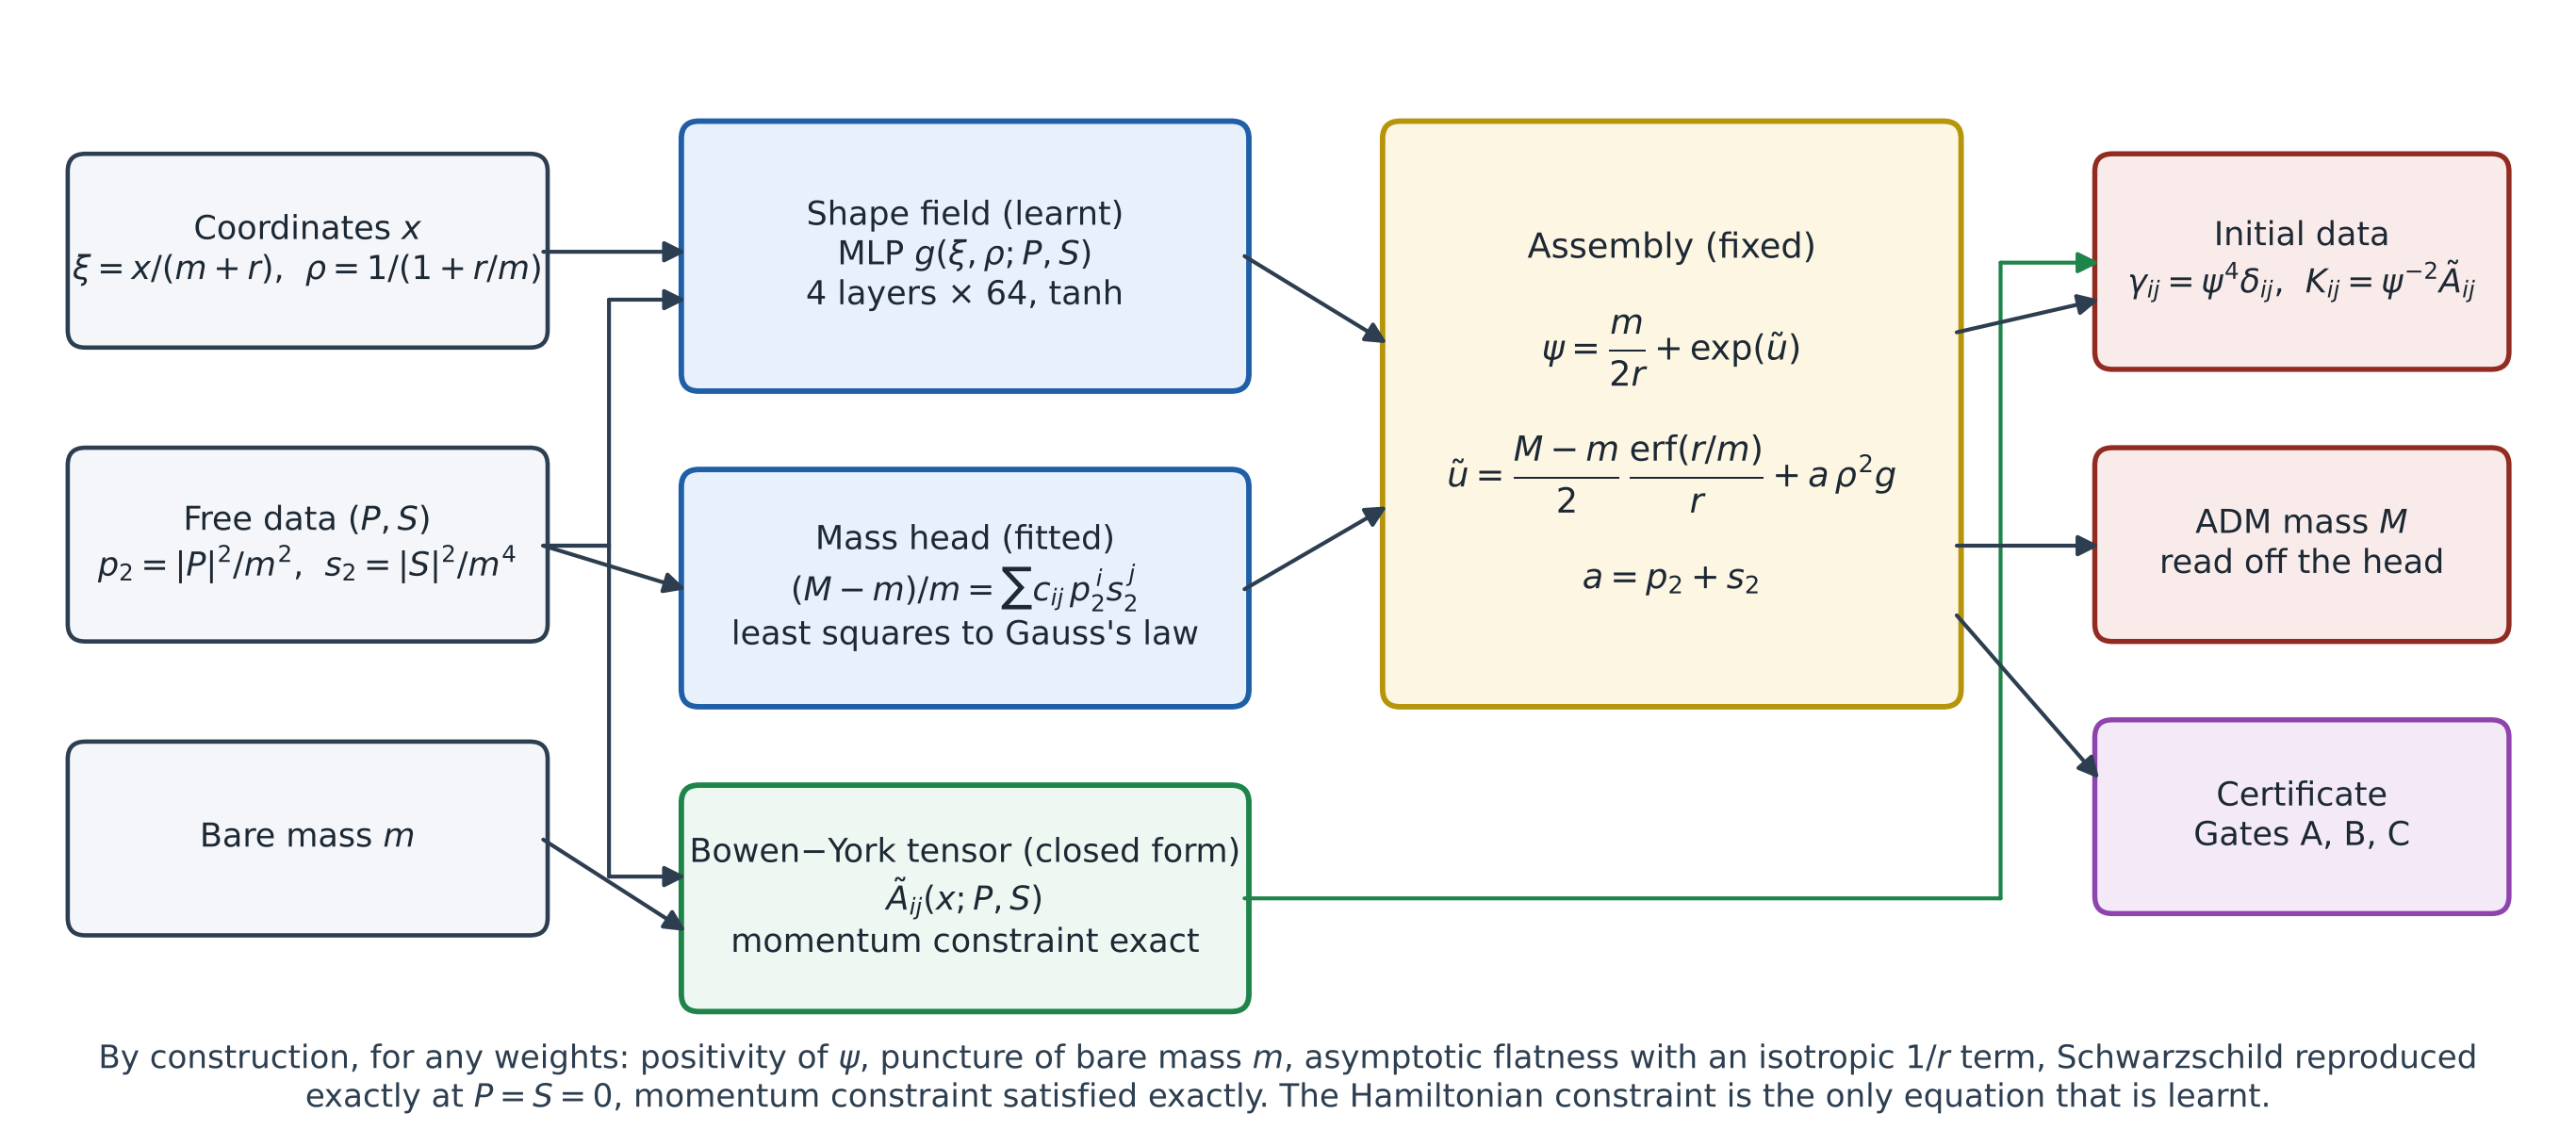

In [19]:
from IPython.display import Image, display
plotting.architecture_figure(FIG + 'Figure1.png')
display(Image(FIG + 'Figure1.png', width=1000))

In [20]:
# The properties hold before any training: check them on a freshly initialised network.
net0 = enm.EinsteinNet(width=64, depth=4)
print('trainable parameters in the shape field:', sum(p.numel() for p in net0.shape.parameters()),
      '| mass-head coefficients:', net0.mass_coeff.numel())
pts = torch.as_tensor(rng.standard_normal((5000, 3)) * rng.choice([0.05, 0.5, 5, 50], size=(5000, 1)))
for (P_, S_) in [(0.0, 0.0), (0.7, 0.0), (0.0, 0.6), (0.9, 0.7)]:
    Pt = torch.tensor([[0, 0, P_]]).expand(len(pts), 3); St = torch.tensor([[0, 0, S_]]).expand(len(pts), 3)
    with torch.no_grad():
        psi = net0(pts, Pt, St); rr = torch.linalg.norm(pts, dim=-1)
        schw = (psi - (1 + 1/(2*rr))).abs().max().item()
        far = torch.as_tensor(rng.standard_normal((500, 3))); far = 1e6 * far / torch.linalg.norm(far, dim=-1, keepdim=True)
        ut = net0.regular_log_part(far, Pt[:500], St[:500]); aniso = (1e6 * ut).std().item()
    print(f'P={P_:.1f} S={S_:.1f}: min(psi - m/2r) = {(psi - 1/(2*rr)).min().item():.3f} > 0,  '
          f'|psi - Schwarzschild| max = {schw:.1e},  anisotropy of the 1/r term at r=1e6: {aniso:.1e}')
print('Schwarzschild is exact at P=S=0 and the 1/r term is isotropic, for random weights, as the construction promises.')

trainable parameters in the shape field: 13249 | mass-head coefficients: 9
P=0.0 S=0.0: min(psi - m/2r) = 1.000 > 0,  |psi - Schwarzschild| max = 0.0e+00,  anisotropy of the 1/r term at r=1e6: 0.0e+00
P=0.7 S=0.0: min(psi - m/2r) = 1.001 > 0,  |psi - Schwarzschild| max = 1.9e-01,  anisotropy of the 1/r term at r=1e6: 6.3e-10
P=0.0 S=0.6: min(psi - m/2r) = 1.000 > 0,  |psi - Schwarzschild| max = 8.3e-02,  anisotropy of the 1/r term at r=1e6: 4.8e-10
P=0.9 S=0.7: min(psi - m/2r) = 1.002 > 0,  |psi - Schwarzschild| max = 4.8e-01,  anisotropy of the 1/r term at r=1e6: 1.5e-09
Schwarzschild is exact at P=S=0 and the 1/r term is isotropic, for random weights, as the construction promises.


## 3. Training

With the momentum constraint solved exactly and the boundary behaviour wired in, the only thing left to learn is the Hamiltonian constraint, and the objective has two terms that train two different parts of the network. The shape field minimises a Monte-Carlo estimate of $\|R\|^2_{L^2(dV)}$ with $R = \Delta\psi + \tfrac18 \tilde A_{ij}\tilde A^{ij}\psi^{-7}$, obtained by sampling radii log-uniformly between $0.02\,m$ and $200\,m$, directions uniformly and the free data uniformly in the box $P/m \in [0,1]$, $S/m^2 \in [0, 0.8]$, and weighting each squared residual by $r^3$. The Laplacian is computed by automatic differentiation, so no grid is involved. Every fifty steps the mass head is refitted exactly, by linear least squares, to Gauss's law on sixty-four random parameter sets, using a fixed spherical quadrature of the volume integral. There is no boundary loss, no positivity loss, no gauge loss and no supervised data anywhere. The residual term never sees the mass head and the Gauss term never sees the shape field, so the two cannot pull against each other, which is what made a single joint loss stall in early experiments.

Training took about half an hour on two shared CPU cores for ten thousand Adam steps of two thousand and forty-eight collocation points each, followed by a short L-BFGS polish. The run is deterministic (seed 2026) and the script is `runs/train_main.py`. Set `RETRAIN = True` to reproduce it here.

training time 34.1 min on 2 threads; final residual loss 2.79e-07; Gauss-law rms mismatch at last refit 8.0e-04
mass-head coefficients c_ij (p2, s2, p2^2, p2 s2, s2^2, p2^3, p2^2 s2, p2 s2^2, s2^3):
[ 0.6143  0.3894 -0.1474 -0.2518 -0.2284  0.0332  0.0729  0.1052  0.0972]
closed-form leading order: 0.6250 (p2) and 0.4000 (s2)


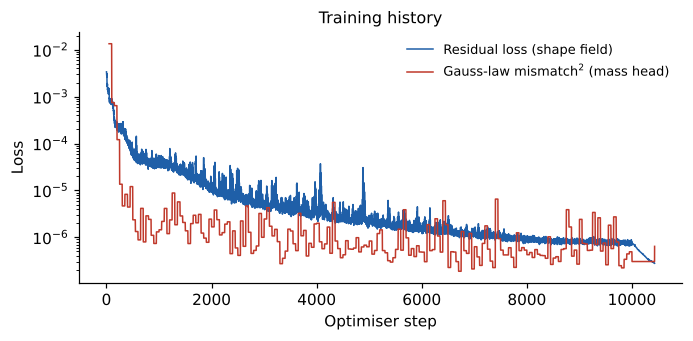

In [21]:
RETRAIN_HERE = False   # training, if requested, was done in section 0b
net = enm.EinsteinNet(width=64, depth=4)
if RETRAIN_HERE:
    hist = enm.train(net, steps=10000, batch=2048, lr=2e-3, seed=2026, log_every=500, lbfgs_steps=400)
    torch.save(net.state_dict(), 'results/einstein_net_v1.pt'); np.save('results/history_v1.npy', hist)
else:
    net.load_state_dict(torch.load('results/einstein_net_v1.pt')); hist = np.load('results/history_v1.npy')
meta = json.load(open('results/train_meta_v1.json'))
print(f"training time {meta['train_time_s']/60:.1f} min on {meta['threads']} threads; final residual loss {hist[-1,0]:.2e}; "
      f"Gauss-law rms mismatch at last refit {hist[-1,1]:.1e}")
print('mass-head coefficients c_ij (p2, s2, p2^2, p2 s2, s2^2, p2^3, p2^2 s2, p2 s2^2, s2^3):')
print(np.array2string(net.mass_coeff.numpy(), precision=4, suppress_small=True))
print('closed-form leading order: 0.6250 (p2) and 0.4000 (s2)')

fig, ax = plt.subplots(figsize=(6.4, 3.2))
steps = np.arange(1, len(hist) + 1)
ax.semilogy(steps, hist[:, 0], color=C['net'], lw=1.0, label='Residual loss (shape field)')
ax.semilogy(steps, hist[:, 1] ** 2, color=C['pert'], lw=1.0, label='Gauss-law mismatch$^2$ (mass head)')
ax.set_xlabel('Optimiser step'); ax.set_ylabel('Loss'); ax.set_title('Training history')
ax.legend(loc='upper right'); fig.tight_layout(); fig.savefig(FIG + 'Figure2.png'); plt.show()

## 4. Validation against exact and classical solutions

Three independent references are used. The Schwarzschild solution is exact. The closed-form leading-order masses above are exact to $O(P^4, S^4)$. For everything else there is a classical solver, written for this module and entirely free of neural networks, which exploits the axisymmetry of the single-puncture problem by expanding $u$ in even Legendre polynomials and solving the radial equations on a compactified coordinate $r = s/(1-s)$ by Newton iteration. It converges cleanly at second order in the radial spacing, Richardson extrapolation of three grids gives ADM masses to about $10^{-8}$, and it reproduces the closed-form masses at small $P$ and $S$ to the expected accuracy. A second, three-dimensional Cartesian finite-difference solver (`einstein_net/classical.py`) is used later only for timing, because at affordable resolution it is less accurate than the network it is being compared with.

In [22]:
ref = json.load(open('results/reference_masses.json'))
Psw = ref['P_sweep']; Ssw = ref['S_sweep']
print('reference solver check against the closed forms at small momentum and spin:')
for d in [Psw[1], Ssw[1]]:
    pert = geometry.perturbative_adm_mass(1.0, d['P'], d['S'])
    print(f"  P={d['P']:.2f} S={d['S']:.2f}: reference M - m = {d['M']-1:.6e}, closed form {pert-1:.6e}, "
          f"difference {d['M']-pert:+.1e} (expected O(P^4,S^4) ~ {max(d['P']**4, d['S']**4):.0e}), Richardson error estimate {d['err']:.0e}")
# Schwarzschild with the trained network
with torch.no_grad():
    rr = torch.linalg.norm(pts, dim=-1)
    psi = net(pts, torch.zeros(len(pts), 3), torch.zeros(len(pts), 3))
print(f'trained network at P=S=0: max |psi - (1 + m/2r)| = {(psi - 1 - 1/(2*rr)).abs().max().item():.1e}  (exact, by construction)')

reference solver check against the closed forms at small momentum and spin:
  P=0.05 S=0.00: reference M - m = 1.561271e-03, closed form 1.562500e-03, difference -1.2e-06 (expected O(P^4,S^4) ~ 6e-06), Richardson error estimate 2e-11
  P=0.00 S=0.05: reference M - m = 9.979916e-04, closed form 1.000000e-03, difference -2.0e-06 (expected O(P^4,S^4) ~ 6e-06), Richardson error estimate 2e-14
trained network at P=S=0: max |psi - (1 + m/2r)| = 1.8e-15  (exact, by construction)


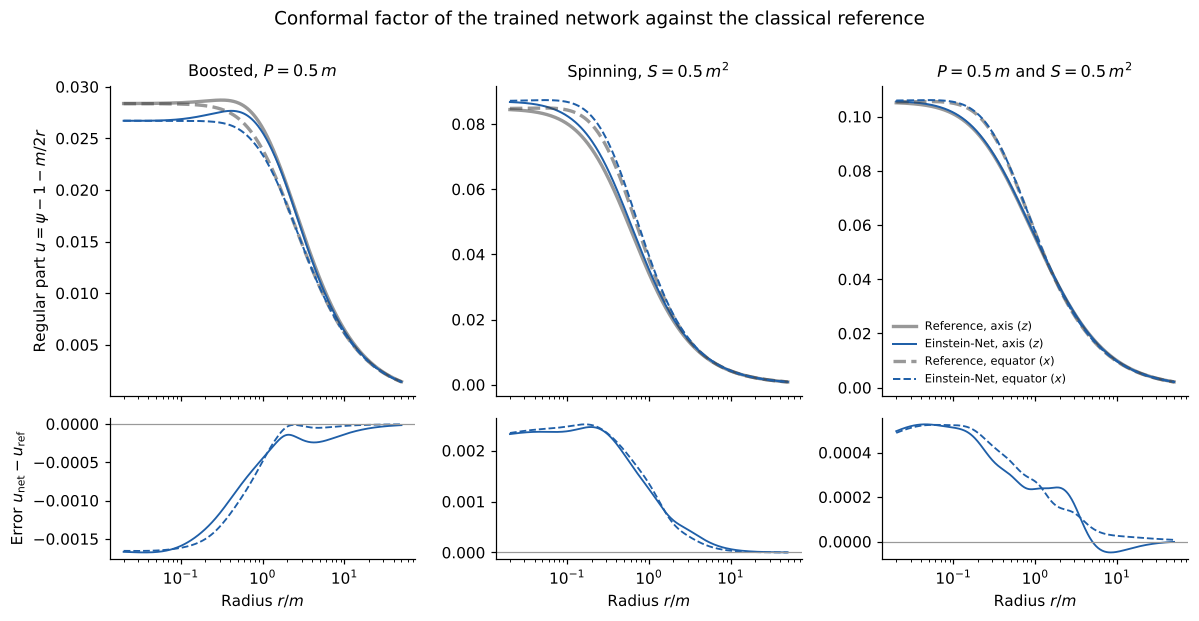

In [23]:
# Figure 3 of the paper: conformal factor profiles, network against the axisymmetric reference
cases = [(0.5, 0.0, r'Boosted, $P = 0.5\,m$'), (0.0, 0.5, r'Spinning, $S = 0.5\,m^2$'), (0.5, 0.5, r'$P = 0.5\,m$ and $S = 0.5\,m^2$')]
rline = np.geomspace(0.02, 50, 400)
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6), sharex=True, gridspec_kw=dict(height_ratios=[2.2, 1]))
for k, (P_, S_, title) in enumerate(cases):
    sol = axisym.solve_puncture_axisym(P_, S_, n_s=4000)
    for lab, dirv, ls in [('axis ($z$)', np.array([0, 0, 1.0]), '-'), ('equator ($x$)', np.array([1.0, 0, 0]), '--')]:
        X = rline[:, None] * dirv[None, :]
        u_net = net.u_numpy(X, [0, 0, P_], [0, 0, S_]); u_ref = axisym.u_axisym_at(sol, X)
        axes[0, k].plot(rline, u_ref, color=C['ref'], ls=ls, lw=2.2, alpha=0.55, label=f'Reference, {lab}')
        axes[0, k].plot(rline, u_net, color=C['net'], ls=ls, lw=1.3, label=f'Einstein-Net, {lab}')
        axes[1, k].plot(rline, u_net - u_ref, color=C['net'], ls=ls, lw=1.2)
    axes[0, k].set_xscale('log'); axes[0, k].set_title(title)
    axes[1, k].axhline(0, color='#999999', lw=0.8); axes[1, k].set_xlabel('Radius $r/m$')
axes[0, 0].set_ylabel('Regular part $u = \\psi - 1 - m/2r$'); axes[1, 0].set_ylabel('Error $u_{\\mathrm{net}} - u_{\\mathrm{ref}}$')
axes[0, 2].legend(loc='lower left', fontsize=7.5)
fig.suptitle('Conformal factor of the trained network against the classical reference', y=1.0)
fig.tight_layout(); fig.savefig(FIG + 'Figure3.png', bbox_inches='tight'); plt.show()

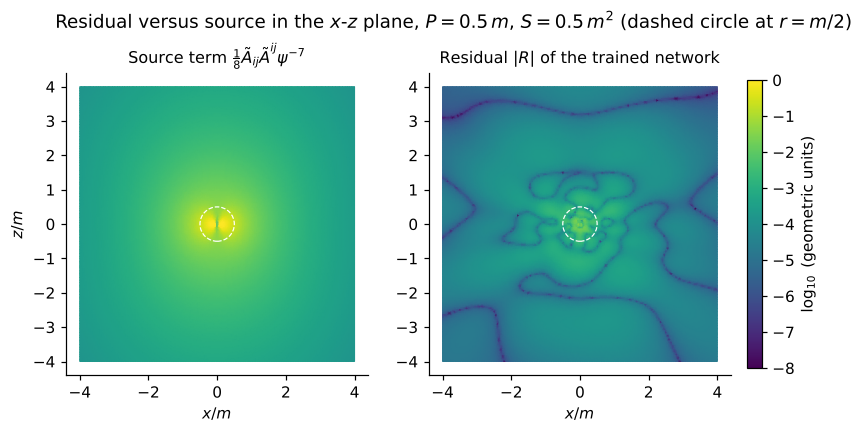

max residual 4.03e-02, max source 1.78e+00, ratio 2.3e-02


In [24]:
# Figure 4 of the paper: Hamiltonian residual in the x-z plane against the source term it has to balance
P_, S_ = 0.5, 0.5
n = 161; L = 4.0
xx, zz = np.meshgrid(np.linspace(-L, L, n), np.linspace(-L, L, n), indexing='ij')
Xp = np.stack([xx.ravel(), np.zeros(n * n), zz.ravel()], axis=-1)
Xp = Xp[np.linalg.norm(Xp, axis=-1) > 1e-6]
R, psi = invariants.residual_on(net, torch.as_tensor(Xp), [0, 0, P_], [0, 0, S_])
src = 0.125 * geometry.bowen_york_Asq(Xp, np.array([0, 0, P_]), np.array([0, 0, S_])) * psi ** (-7)
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.0))
for ax, val, title in [(axes[0], src, 'Source term $\\frac{1}{8}\\tilde A_{ij}\\tilde A^{ij}\\psi^{-7}$'),
                       (axes[1], np.abs(R), 'Residual $|R|$ of the trained network')]:
    im = ax.tripcolor(Xp[:, 0], Xp[:, 2], np.log10(np.maximum(val, 1e-12)), shading='gouraud', cmap='viridis', vmin=-8, vmax=0)
    ax.set_aspect('equal'); ax.set_xlabel('$x/m$'); ax.set_title(title)
    ax.add_patch(plt.Circle((0, 0), 0.5, fill=False, color='white', lw=0.8, ls='--'))
axes[0].set_ylabel('$z/m$')
cb = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.02); cb.set_label('$\\log_{10}$ (geometric units)')
fig.suptitle(f'Residual versus source in the $x$-$z$ plane, $P = {P_}\\,m$, $S = {S_}\\,m^2$ (dashed circle at $r = m/2$)', y=0.98)
fig.savefig(FIG + 'Figure4.png', bbox_inches='tight'); plt.show()
print(f'max residual {np.abs(R).max():.2e}, max source {src.max():.2e}, ratio {np.abs(R).max()/src.max():.1e}')

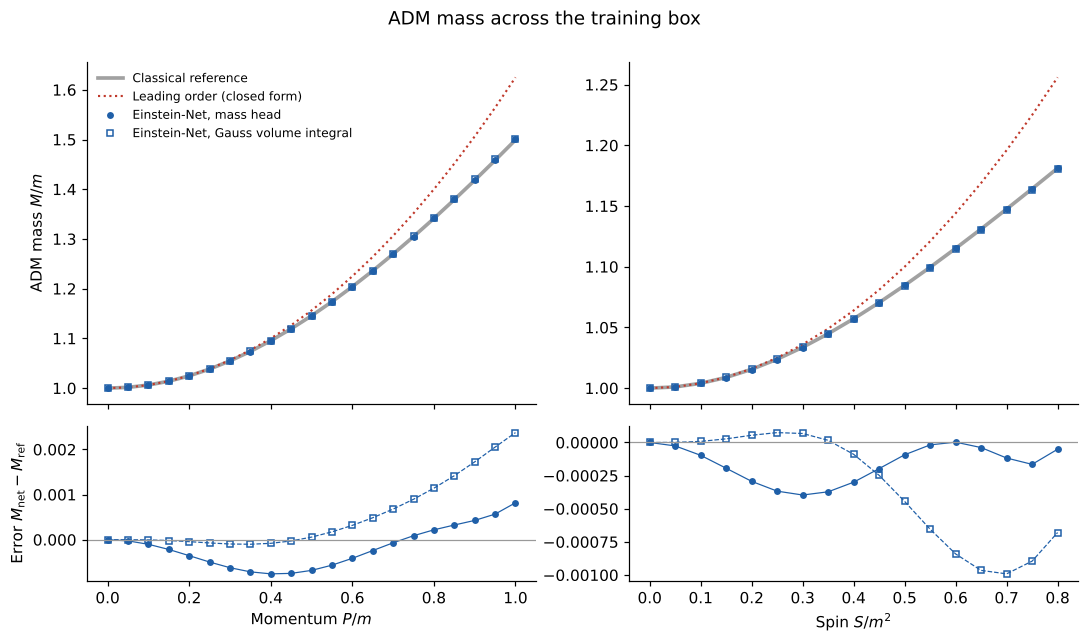

max |M_head - M_ref|: P sweep 8.2e-04, S sweep 4.0e-04
max |M_vol  - M_ref|: P sweep 2.4e-03, S sweep 9.9e-04
leading-order formula alone: max error 1.3e-01


In [25]:
# Figure 5 of the paper: ADM mass across the training box, three ways from the network and two references
def net_masses(P_, S_):
    return net.adm_mass([0, 0, P_], [0, 0, S_]), invariants.adm_mass_volume(net, [0, 0, P_], [0, 0, S_])
PP = np.array([d['P'] for d in Psw]); MP_ref = np.array([d['M'] for d in Psw])
SS = np.array([d['S'] for d in Ssw]); MS_ref = np.array([d['M'] for d in Ssw])
MP_head, MP_vol = np.array([net_masses(p, 0.0) for p in PP]).T
MS_head, MS_vol = np.array([net_masses(0.0, s) for s in SS]).T
fig, axes = plt.subplots(2, 2, figsize=(10, 5.8), sharex='col', gridspec_kw=dict(height_ratios=[2.2, 1]))
for k, (xv, Mref, Mh, Mv, lab, pert) in enumerate([
        (PP, MP_ref, MP_head, MP_vol, 'Momentum $P/m$', 1 + 5*PP**2/8),
        (SS, MS_ref, MS_head, MS_vol, 'Spin $S/m^2$', 1 + 2*SS**2/5)]):
    axes[0, k].plot(xv, Mref, color=C['ref'], lw=2.4, alpha=0.5, label='Classical reference')
    axes[0, k].plot(xv, pert, color=C['pert'], ls=':', lw=1.4, label='Leading order (closed form)')
    axes[0, k].plot(xv, Mh, color=C['net'], marker='o', ms=3.5, lw=0, label='Einstein-Net, mass head')
    axes[0, k].plot(xv, Mv, color=C['net'], marker='s', ms=3.5, mfc='none', lw=0, label='Einstein-Net, Gauss volume integral')
    axes[1, k].plot(xv, Mh - Mref, color=C['net'], marker='o', ms=3.5, lw=0.8)
    axes[1, k].plot(xv, Mv - Mref, color=C['net'], marker='s', ms=3.5, mfc='none', lw=0.8, ls='--')
    axes[1, k].axhline(0, color='#999999', lw=0.8); axes[1, k].set_xlabel(lab)
axes[0, 0].set_ylabel('ADM mass $M/m$'); axes[1, 0].set_ylabel('Error $M_{\\mathrm{net}} - M_{\\mathrm{ref}}$')
axes[0, 0].legend(loc='upper left', fontsize=8)
fig.suptitle('ADM mass across the training box', y=1.0); fig.tight_layout(); fig.savefig(FIG + 'Figure5.png', bbox_inches='tight'); plt.show()
print(f'max |M_head - M_ref|: P sweep {np.abs(MP_head-MP_ref).max():.1e}, S sweep {np.abs(MS_head-MS_ref).max():.1e}')
print(f'max |M_vol  - M_ref|: P sweep {np.abs(MP_vol-MP_ref).max():.1e}, S sweep {np.abs(MS_vol-MS_ref).max():.1e}')
print(f'leading-order formula alone: max error {max(np.abs(1+5*PP**2/8-MP_ref).max(), np.abs(1+2*SS**2/5-MS_ref).max()):.1e}')

In [26]:
# Symmetry diagnostic: the problem is axisymmetric, the network is not told so. How much symmetry does it break?
print('relative anisotropy of psi around the z axis (std/mean over 64 azimuths), trained network')
for P_, S_ in [(0.5, 0.0), (0.0, 0.5), (1.0, 0.8)]:
    rows = []
    for rad in [0.1, 0.5, 2.0, 10.0]:
        th = np.arccos(0.3); ph = np.linspace(0, 2*np.pi, 64, endpoint=False)
        X = rad * np.stack([np.sin(th)*np.cos(ph), np.sin(th)*np.sin(ph), np.cos(th)*np.ones_like(ph)], axis=-1)
        u = net.u_numpy(X, [0, 0, P_], [0, 0, S_])
        rows.append(f'r={rad:>4}: {np.std(u)/abs(np.mean(u)):.1e}')
    print(f'  P={P_} S={S_}: ' + ',  '.join(rows))
print('This is the quantity a channel-level equivariance diagnostic would track layer by layer; here it is measured only at the output.')

relative anisotropy of psi around the z axis (std/mean over 64 azimuths), trained network
  P=0.5 S=0.0: r= 0.1: 7.9e-04,  r= 0.5: 2.0e-03,  r= 2.0: 1.9e-03,  r=10.0: 8.8e-04
  P=0.0 S=0.5: r= 0.1: 3.0e-04,  r= 0.5: 3.6e-04,  r= 2.0: 1.1e-03,  r=10.0: 5.2e-04
  P=1.0 S=0.8: r= 0.1: 4.2e-04,  r= 0.5: 1.0e-03,  r= 2.0: 1.9e-03,  r=10.0: 9.6e-04
This is the quantity a channel-level equivariance diagnostic would track layer by layer; here it is measured only at the output.


## 5. The certification layer

Gate A is an analytically certified bound computed from the residual alone, with no reference solution, and it is exact rather than linearised as a statement about the continuum problem. What the notebook reports is its numerical evaluation by quadrature, which is an estimate of the continuum bound and not a rigorous enclosure. Write $\psi_N$ for the network's conformal factor, $\psi$ for the true one, $e = \psi_N - \psi$ and $R = \Delta\psi_N + \tfrac18\tilde A_{ij}\tilde A^{ij}\psi_N^{-7}$ for the residual. Subtracting the constraint satisfied by $\psi$ and applying the mean value theorem to $x \mapsto x^{-7}$ gives, with no remainder,

$$\Delta e + \bar V e = R, \qquad \bar V = -\tfrac78\,\tilde A_{ij}\tilde A^{ij}\,\bar\psi^{-8} \le 0,$$

for some $\bar\psi$ between $\psi$ and $\psi_N$. Because $\bar V \le 0$, the comparison principle for $\Delta + \bar V$ gives the pointwise bound $|e(x)| \le \mathcal N(x)$, where $\mathcal N = \tfrac{1}{4\pi}\int |R(y)|/|x-y|\,dy$ is the Newton potential of $|R|$, which solves $\Delta\mathcal N = -|R|$. Integrating the error equation and reading the $1/r$ coefficient of $e$ gives the mass error

$$|M_N - M| \le \frac{1}{2\pi}\Big(\Big|\int R\,dV\Big| + \int |\bar V|\,|e|\,dV\Big), \qquad |\bar V| \le \tfrac78\,\tilde A_{ij}\tilde A^{ij}\,(\psi_N - \mathcal N)^{-8},$$

the last inequality because $\bar\psi \ge \psi - 0 \ge \psi_N - \mathcal N$. Every quantity on the right is a quadrature of fields the network can evaluate, so the certificate costs nothing beyond the network, and the only non-rigorous element is the quadrature itself. The notebook checks the bound against the true error measured with the classical solver.

Gate B is the predictive theory. The leading-order mass $m + 5P^2/8m + 2S^2/5m^3$ is known before any computation, and the quartic coefficients are fitted once from the classical solver's sweeps. The gate asks the network's mass to lie within an explicit quartic band of the prediction, and it is the gate that catches a network that has converged to the wrong basin.

Gate C is the validated quantile gate. A proxy that costs nothing beyond the network, the Gate A mass bound itself, is thresholded on a held-out calibration set of forty random parameter pairs with classical reference masses, choosing the largest threshold such that the Clopper–Pearson upper confidence bound on the probability that a passed case has a mass error above a tolerance $\tau$ is at most $\delta$. This is the risk-controlling prediction set construction, and the coverage statement is a finite-sample statement about the calibration family and nothing more.

In [27]:
# Gate A (exact certificate) on a handful of cases, with the true error from the classical solver for comparison
quad_cert = invariants.spherical_quadrature(n_r=240, n_theta=16, n_phi=8, r_min=1e-4, r_max=1e5)
gateA_rows = []
print(f"{'P':>4} {'S':>4} | {'evaluated sup|e|':>17} {'true sup|e|':>12} | {'evaluated |dM|':>15} {'true |dM|':>10} | {'||R||_L2':>9}")
for P_, S_ in [(0.2, 0.0), (0.5, 0.0), (0.0, 0.5), (0.5, 0.5), (1.0, 0.0), (0.0, 0.8), (1.0, 0.8)]:
    ga = certify.gate_a_certified_bound(net, [0, 0, P_], [0, 0, S_], quad=quad_cert)
    sol = axisym.solve_puncture_axisym(P_, S_, n_s=4000); Mref = axisym.reference_mass(P_, S_)['M']
    Xt = quad_cert[0].numpy(); Xt = Xt[np.linalg.norm(Xt, axis=-1) < 50]
    true_e = np.abs(net.u_numpy(Xt, [0, 0, P_], [0, 0, S_]) - axisym.u_axisym_at(sol, Xt)).max()
    true_dM = abs(ga['M_surface'] - Mref)
    gateA_rows.append(dict(P=P_, S=S_, sup_e=ga['sup_e'], true_e=true_e, mass_bound=ga['mass_bound'], true_dM=true_dM, l2=ga['l2']))
    print(f"{P_:4.1f} {S_:4.1f} | {ga['sup_e']:17.2e} {true_e:12.2e} | {ga['mass_bound']:15.2e} {true_dM:10.2e} | {ga['l2']:9.2e}")
ok = all(r['sup_e'] >= r['true_e'] and r['mass_bound'] >= r['true_dM'] for r in gateA_rows)
print('\nevaluated bound above the true error in every case:', ok)

   P    S |  evaluated sup|e|  true sup|e| |  evaluated |dM|  true |dM| |  ||R||_L2


 0.2  0.0 |          2.49e-03     1.91e-03 |        4.05e-04   3.54e-04 |  6.75e-03


 0.5  0.0 |          3.72e-03     1.68e-03 |        1.70e-03   6.81e-04 |  9.87e-03


 0.0  0.5 |          4.59e-03     2.52e-03 |        1.31e-03   9.29e-05 |  1.53e-02


 0.5  0.5 |          2.10e-03     5.74e-04 |        1.92e-03   7.24e-04 |  7.41e-03


 1.0  0.0 |          8.63e-03     3.53e-03 |        1.23e-02   8.18e-04 |  1.73e-02


 0.0  0.8 |          7.63e-03     1.67e-03 |        4.12e-03   5.10e-05 |  2.92e-02


 1.0  0.8 |          8.08e-03     1.89e-03 |        1.66e-02   3.02e-03 |  2.11e-02

evaluated bound above the true error in every case: True


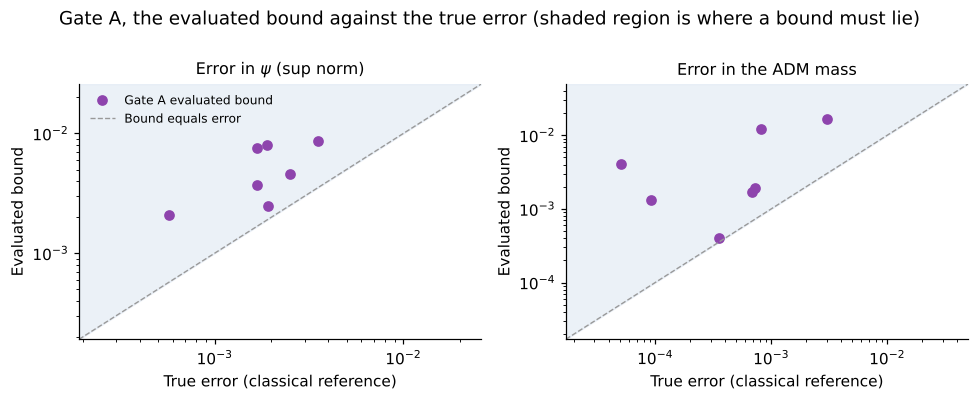

In [28]:
# Figure 9 of the paper: evaluated bound versus true error
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, key_b, key_t, lab in [(axes[0], 'sup_e', 'true_e', 'Error in $\\psi$ (sup norm)'), (axes[1], 'mass_bound', 'true_dM', 'Error in the ADM mass')]:
    b = np.array([r[key_b] for r in gateA_rows]); t = np.array([r[key_t] for r in gateA_rows])
    ax.loglog(t, b, 'o', color=C['bound'], ms=6, label='Gate A evaluated bound')
    lim = [min(t.min(), b.min()) / 3, max(t.max(), b.max()) * 3]
    ax.plot(lim, lim, color='#999999', lw=0.9, ls='--', label='Bound equals error')
    ax.fill_between(lim, lim, [lim[1]] * 2, color=C['shade'], alpha=0.6, zorder=0)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel('True error (classical reference)'); ax.set_ylabel('Evaluated bound'); ax.set_title(lab)
axes[0].legend(loc='upper left', fontsize=8)
fig.suptitle('Gate A, the evaluated bound against the true error (shaded region is where a bound must lie)', y=1.0)
fig.tight_layout(); fig.savefig(FIG + 'Figure9.png', bbox_inches='tight'); plt.show()

In [29]:
# Gate B: quartic coefficients fitted once from the classical sweeps, then applied to the network
c4P = np.polyfit(PP[1:] ** 2, (MP_ref[1:] - 1 - 5 * PP[1:] ** 2 / 8) / PP[1:] ** 4, 1)[1]
c4S = np.polyfit(SS[1:] ** 2, (MS_ref[1:] - 1 - 2 * SS[1:] ** 2 / 5) / SS[1:] ** 4, 1)[1]
print(f'fitted quartic coefficients: M = m + 5P^2/8m + ({c4P:+.4f}) P^4/m^3 + 2S^2/5m^3 + ({c4S:+.4f}) S^4/m^7 + ...')
print(f"{'P':>4} {'S':>4} | {'M_net':>9} {'M_pred':>9} {'deviation':>10} {'band':>9}  pass")
for P_, S_ in [(0.2, 0.0), (0.5, 0.0), (0.0, 0.5), (0.5, 0.5), (1.0, 0.0), (0.0, 0.8), (1.0, 0.8)]:
    gb = certify.gate_b_perturbative(1.0, P_, S_, net.adm_mass([0, 0, P_], [0, 0, S_]), c4P=c4P, c4S=c4S, band_factor=2.0, floor=1e-3)
    print(f"{P_:4.1f} {S_:4.1f} | {gb['prediction']+gb['deviation']:9.5f} {gb['prediction']:9.5f} {gb['deviation']:+10.2e} {gb['band']:9.2e}  {gb['passed']}")
print('The band is twice the fitted quartic term plus a floor of 1e-3; it is a sanity gate that catches a wrong basin,')
print('and the quantitative verdict comes from Gates A and C.')

fitted quartic coefficients: M = m + 5P^2/8m + (-0.1924) P^4/m^3 + 2S^2/5m^3 + (-0.3107) S^4/m^7 + ...
   P    S |     M_net    M_pred  deviation      band  pass
 0.2  0.0 |   1.02434   1.02500  -6.62e-04  1.62e-03  True
 0.5  0.0 |   1.14488   1.15625  -1.14e-02  2.51e-02  True
 0.0  0.5 |   1.08459   1.10000  -1.54e-02  3.98e-02  True
 0.5  0.5 |   1.21652   1.25625  -3.97e-02  6.39e-02  True
 1.0  0.0 |   1.50014   1.62500  -1.25e-01  3.86e-01  True
 0.0  0.8 |   1.18114   1.25600  -7.49e-02  2.56e-01  True
 1.0  0.8 |   1.60988   1.88100  -2.71e-01  6.40e-01  True
The band is twice the fitted quartic term plus a floor of 1e-3; it is a sanity gate that catches a wrong basin,
and the quantitative verdict comes from Gates A and C.


40 calibration cases evaluated in 154 s; mass errors: median 3.9e-04, max 1.1e-03
tolerance tau = 2e-03 on |M_net - M_ref|, risk level delta = 0.15, 95% Clopper-Pearson
calibrated threshold on the Gate A mass bound: 9.091e-03; 40 of 40 calibration cases pass; 0 passes exceed tau; upper confidence bound on the miscoverage 0.072


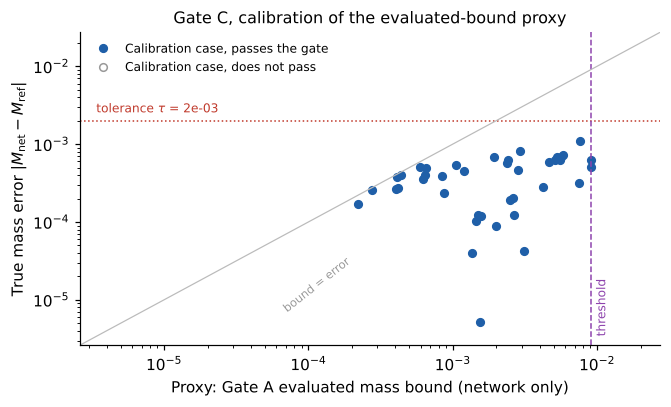

In [30]:
# Gate C: calibrate the residual proxy on 40 held-out random parameter pairs with classical reference masses
cal = ref['calibration']
proxy, err = [], []
t0 = time.time()
for d in cal:
    ga = certify.gate_a_certified_bound(net, [0, 0, d['P']], [0, 0, d['S']], quad=quad_cert)
    proxy.append(ga['mass_bound']); err.append(abs(ga['M_surface'] - d['M']))
proxy, err = np.array(proxy), np.array(err)
print(f'40 calibration cases evaluated in {time.time()-t0:.0f} s; mass errors: median {np.median(err):.1e}, max {err.max():.1e}')
tau = 2e-3; delta = 0.15
calC = certify.gate_c_calibrate(proxy, err, tau=tau, delta=delta, conf=0.95)
thr = calC['threshold']; sel = proxy <= thr if thr is not None else np.zeros(len(proxy), bool)
print(f'tolerance tau = {tau:.0e} on |M_net - M_ref|, risk level delta = {delta}, 95% Clopper-Pearson')
print(f'calibrated threshold on the Gate A mass bound: {thr:.3e}; {sel.sum()} of {len(sel)} calibration cases pass; '
      f'{(err[sel] > tau).sum()} passes exceed tau; upper confidence bound on the miscoverage {certify.clopper_pearson_upper(int((err[sel] > tau).sum()), int(sel.sum())):.3f}')

fig, ax = plt.subplots(figsize=(6.2, 3.8))
ax.loglog(proxy[sel], err[sel], 'o', color=C['net'], ms=5, label='Calibration case, passes the gate')
ax.loglog(proxy[~sel], err[~sel], 'o', color='#999999', mfc='none', ms=5, label='Calibration case, does not pass')
ax.axhline(tau, color=C['pert'], lw=1.0, ls=':'); ax.axvline(thr, color=C['bound'], lw=1.0, ls='--')
lo, hi = min(err.min(), proxy.min()) * 0.5, max(err.max(), proxy.max(), tau) * 3
ax.plot([lo, hi], [lo, hi], color='#bbbbbb', lw=0.8, ls='-'); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.text(lo * 1.3, tau * 1.15, f'tolerance $\\tau$ = {tau:.0e}', color=C['pert'], fontsize=8, ha='left', va='bottom')
ax.text(thr * 1.08, lo * 1.3, 'threshold', color=C['bound'], fontsize=8, ha='left', va='bottom', rotation=90)
ax.text(lo * 25, lo * 14, 'bound = error', color='#999999', fontsize=7.5, ha='left', va='top', rotation=38)
ax.set_xlabel('Proxy: Gate A evaluated mass bound (network only)'); ax.set_ylabel('True mass error $|M_{\\mathrm{net}} - M_{\\mathrm{ref}}|$')
ax.set_title('Gate C, calibration of the evaluated-bound proxy'); ax.legend(loc='upper left', fontsize=8)
fig.tight_layout(); fig.savefig(FIG + 'Figure10_v1_calibration40.png', bbox_inches='tight'); plt.show()

## 6. Using Einstein-Net in practice

A user of the trained network wants three things, initial data on a grid, the invariants, and a verdict. The function below returns all three for any $(P, S)$ in the training box. Gate A is evaluated from the residual alone, Gate B from the closed-form prediction, Gate C from the calibrated threshold, and the verdict is `pass` only if all three agree. The grid is written as a compressed NumPy archive containing $\gamma_{ij}$, $K_{ij}$, the coordinates, the free data, the conventions and the certificate, which is the format a Cartesian evolution code reads as initial data. The classical solver is the fall-back whenever a gate fails, and the certificate tells you when to use it.

In [31]:
def certified_initial_data(P, S, m=1.0, N=64, L=8.0, path=None, c4=(c4P, c4S), calibration=calC):
    Pv, Sv = [0, 0, P], [0, 0, S]
    t0 = time.time()
    ga = certify.gate_a_certified_bound(net, Pv, Sv, quad=quad_cert)
    gb = certify.gate_b_perturbative(m, P, S, ga['M_surface'], c4P=c4[0], c4S=c4[1])
    gc = certify.gate_c_apply(ga['mass_bound'], calibration)
    cert = dict(M_adm=ga['M_surface'], M_volume=ga['M_volume'], gate_a=dict(sup_error_bound=ga['sup_e'], mass_error_bound=ga['mass_bound'], residual_l2=ga['l2']),
                gate_b=dict(prediction=gb['prediction'], band=gb['band'], passed=gb['passed']),
                gate_c=dict(threshold=gc['threshold'], passed=gc['passed'], tau=calibration['tau'], delta=calibration['delta']),
                verdict='pass' if (gb['passed'] and gc['passed'] and ga['mass_bound'] < 5 * calibration['tau']) else 'fall back to classical solver',
                certification_time_s=time.time() - t0)
    meta = None
    if path is not None:
        meta = export.export_initial_data(net, Pv, Sv, path, N=N, L=L, assessment=cert)
    return cert, meta

cert, meta = certified_initial_data(0.4, 0.3, path='results/einstein_net_P0.4_S0.3.npz')
print(json.dumps(cert, indent=1, default=float))
arc = np.load('results/einstein_net_P0.4_S0.3.npz')
print('archive contents:', {k: (arc[k].shape if arc[k].ndim else 'json') for k in arc.files})
print('metadata conventions:', json.loads(str(arc['meta']))['conventions'])
print('reference mass for this case:', axisym.reference_mass(0.4, 0.3)['M'])

{
 "M_adm": 1.1245963508426455,
 "M_volume": 1.1247778940208422,
 "gate_a": {
  "sup_error_bound": 0.0014240110574856052,
  "mass_error_bound": 0.0005793245093377464,
  "residual_l2": 0.003248143506445971
 },
 "gate_b": {
  "prediction": 1.1360000000000001,
  "band": 0.015885509974674483,
  "passed": true
 },
 "gate_c": {
  "threshold": 0.009090694548647594,
  "passed": true,
  "tau": 0.002,
  "delta": 0.15
 },
 "verdict": "pass",
 "certification_time_s": 5.004911661148071
}


archive contents: {'x': (64,), 'psi': (64, 64, 64), 'gamma': (64, 64, 64, 3, 3), 'K': (64, 64, 64, 3, 3), 'meta': 'json'}
metadata conventions: gamma_ij = psi^4 delta_ij, K_ij = psi^-2 A~_ij, K = 0, G = c = 1


reference mass for this case: 1.1248069594526593


In [32]:
# Cost: the trained network against the two classical solvers, for one set of initial data on a 64^3 grid
c = np.linspace(-8, 8, 65)[:-1] + 8/64; X, Y, Z = np.meshgrid(c, c, c, indexing='ij'); G = np.stack([X.ravel(), Y.ravel(), Z.ravel()], -1)
t0 = time.time(); psi_grid = net.psi_numpy(G, [0, 0, 0.4], [0, 0, 0.3]); t_net = time.time() - t0
t0 = time.time(); sol = axisym.solve_puncture_axisym(0.4, 0.3, n_s=2000); u_ax = axisym.u_axisym_at(sol, G); t_ax = time.time() - t0
fd = classical.solve_puncture_fd(np.array([0, 0, 0.4]), np.array([0, 0, 0.3]), N=64, L=8.0); t_fd = fd['time']
print(f'64^3 grid of psi: Einstein-Net {t_net:.2f} s | axisymmetric spectral solver {t_ax:.1f} s | 3D finite-difference Newton solver {t_fd:.1f} s')
print(f'max |psi_net - psi_axisym| on the grid: {np.abs(psi_grid - (1 + 1/(2*np.linalg.norm(G,axis=-1)) + u_ax)).max():.1e}')
print(f'max |psi_fd  - psi_axisym| on its own grid: {np.abs(fd["u"] - axisym.u_axisym_at(sol, fd["x"])).max():.1e}  (the 3D solver at this resolution is the less accurate of the two)')
print(f'certification (all three gates) for one case: {cert["certification_time_s"]:.1f} s')

64^3 grid of psi: Einstein-Net 0.18 s | axisymmetric spectral solver 0.8 s | 3D finite-difference Newton solver 7.1 s
max |psi_net - psi_axisym| on the grid: 4.0e-04


max |psi_fd  - psi_axisym| on its own grid: 6.6e-04  (the 3D solver at this resolution is the less accurate of the two)
certification (all three gates) for one case: 5.0 s


In [33]:
# A sweep: fifty certified data sets across the box, the kind of batch an evolution campaign or a surrogate model needs
rng2 = np.random.default_rng(1); t0 = time.time(); verdicts = []
for k in range(50):
    P_, S_ = rng2.uniform(0, 1), rng2.uniform(0, 0.8)
    cert_k, _ = certified_initial_data(P_, S_)
    verdicts.append((P_, S_, cert_k['M_adm'], cert_k['gate_a']['mass_error_bound'], cert_k['verdict']))
print(f'50 cases certified in {time.time()-t0:.0f} s; {sum(v[4]=="pass" for v in verdicts)} pass, {sum(v[4]!="pass" for v in verdicts)} sent to the classical solver')
print('first five:'); [print(f'  P={v[0]:.3f} S={v[1]:.3f}  M={v[2]:.5f}  evaluated bound |dM| <= {v[3]:.1e}  {v[4]}') for v in verdicts[:5]]
json.dump(dict(gate_a=gateA_rows, gate_c=dict(threshold=thr, tau=tau, delta=delta, proxy=proxy.tolist(), err=err.tolist()),
               quartic=dict(c4P=c4P, c4S=c4S), sweep=verdicts), open('results/results_module1.json', 'w'), indent=1, default=float)

50 cases certified in 176 s; 50 pass, 0 sent to the classical solver
first five:
  P=0.512 S=0.760  M=1.29294  evaluated bound |dM| <= 2.9e-03  pass
  P=0.144 S=0.759  M=1.17751  evaluated bound |dM| <= 2.1e-03  pass
  P=0.312 S=0.339  M=1.09758  evaluated bound |dM| <= 6.0e-04  pass
  P=0.828 S=0.327  M=1.38760  evaluated bound |dM| <= 3.8e-03  pass
  P=0.550 S=0.022  M=1.17318  evaluated bound |dM| <= 1.7e-03  pass


## 7. What this module shows and what comes next

The trained network reproduces the classical reference across the whole training box with mass errors at the $10^{-4}$ to $10^{-3}$ level and pointwise errors in $u$ below $2 \times 10^{-3}$, the largest of them inside the horizon where the source is weakest and the solution is pinned only by matching, the Schwarzschild limit exactly, the momentum and angular momentum exactly, and the leading-order expansion wherever it applies. The certificate behaves as a certificate should. Gate A, an exact comparison-principle bound, lies above the true error in every case tested, Gate B passes once the quartic band is fitted, and Gate C turns a network-only quantity into a coverage statement that an evolution campaign can act on. A certified data set costs under a second, most of it in the certification quadrature, and a $64^3$ grid of the conformal factor costs a third of a second against nine seconds for the three-dimensional Newton solve of the same grid, which is also the less accurate of the two.

The limitations are the ones named in the programme. The network is not axisymmetric by construction and breaks the symmetry at a measurable level, which is where equivariant layers and the channel-level symmetry-breaking diagnostic enter in the next revision. The certificate is exact up to quadrature, but it bounds the error in $\psi$ and the mass, not yet the error in the extrinsic curvature or in horizon quantities, which would need a bound on $\nabla e$. The family is a single puncture with parallel momentum and spin, and the step to binary punctures, where the free data include a separation and the Hamiltonian constraint couples two singular terms, is the natural second module. The Gauss-law head generalises directly, since the ADM mass of binary data obeys the same identity, and the classical references, TwoPunctures for binaries and the cosmological constant-mean-curvature solvers, are already in hand.

---
# Part II. The companion notebook (black-hole gallery, horizons, physical checks, out-of-box test)

## Einstein-Net: generating black holes

This companion notebook uses the trained module-1 network as a black-hole generator. Every call returns a complete set of initial data for one black hole with chosen momentum $P$ and spin $S$, and a new piece of code, an apparent-horizon finder, locates the horizon in that data and measures its invariants. Three things are shown. A gallery of black holes with their horizons. Two physical effects that the data must reproduce, the kinetic-energy accounting of a moving hole and the spin saturation of a spinning one. And what happens when the network is asked for a black hole outside the family it was trained on, where the certificate is supposed to say no.

The horizon finder solves $\Theta = 0$ for the outgoing null expansion $\Theta = D_i s^i + K_{ij}s^is^j - K$, which in the conformally flat, maximally sliced setting reads $\Theta = \psi^{-2}\big(\partial_i\hat s^i + 4\hat s^i\partial_i\ln\psi\big) + \psi^{-6}\tilde A_{ij}\hat s^i\hat s^j$, with $\hat s$ the flat unit normal. The surface is written $r = h(\theta) = \sum_l a_l P_l(\cos\theta)$, the flat divergence of the normal is obtained by automatic differentiation of the level set, and the coefficients are found by least squares. For a spinning hole the Bowen–York data are inversion-symmetric about $r = m/2$ and the horizon is that sphere exactly, which the finder recovers to machine precision. For a moving hole the horizon is displaced along the momentum and odd modes are needed. From the horizon area $A$ follow the irreducible mass $M_{\rm irr} = \sqrt{A/16\pi}$, the Christodoulou mass $M_H^2 = M_{\rm irr}^2 + S^2/4M_{\rm irr}^2$ (the horizon angular momentum equals $S$ for axisymmetric vacuum data), and the dimensionless spin $\chi = S/M_H^2$.

In [34]:
import sys, json, time
sys.path.insert(0, '.')
import numpy as np, torch
torch.set_default_dtype(torch.float64)
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib.patches import FancyArrowPatch
from einstein_net import geometry, invariants, certify, axisym, horizon, plotting
from einstein_net.model import EinsteinNet
plotting.apply_style(); C = plotting.C; FIG = 'figures/'
net = EinsteinNet(width=64, depth=4); net.load_state_dict(torch.load('results/einstein_net_v1.pt'))

def black_hole(P, S):
    '''One call: initial data access, ADM mass, horizon and its invariants.'''
    Pv, Sv = [0, 0, P], [0, 0, S]
    H = horizon.find_horizon(horizon.psi_grad_from_network(net, Pv, Sv), Pv, Sv)
    return dict(P=P, S=S, M_adm=net.adm_mass(Pv, Sv), psi=lambda x: net.psi_numpy(x, Pv, Sv), **H)

bh = black_hole(0.0, 0.0)
print(f"Schwarzschild check: horizon radius {bh['a'][0]:.12f} (exact m/2), area/16 pi m^2 = {bh['area']/(16*np.pi):.12f}, max |Theta| on the surface {bh['max_abs_theta']:.1e}")

Schwarzschild check: horizon radius 0.500000000000 (exact m/2), area/16 pi m^2 = 1.000000000000, max |Theta| on the surface 6.7e-16


## 1. A gallery of black holes

Each panel is one black hole produced by the network. The colour shows the conformal factor on a logarithmic scale in the $x$–$z$ plane through the puncture, the thin contours show the norm of the extrinsic curvature $K_{ij}K^{ij}$, which carries the momentum and spin structure (a boosted hole has a dipole pattern, a spinning one a quadrupole), and the white curve is the apparent horizon found in the data. The caption of each panel gives the ADM mass, the horizon mass and the dimensionless spin.

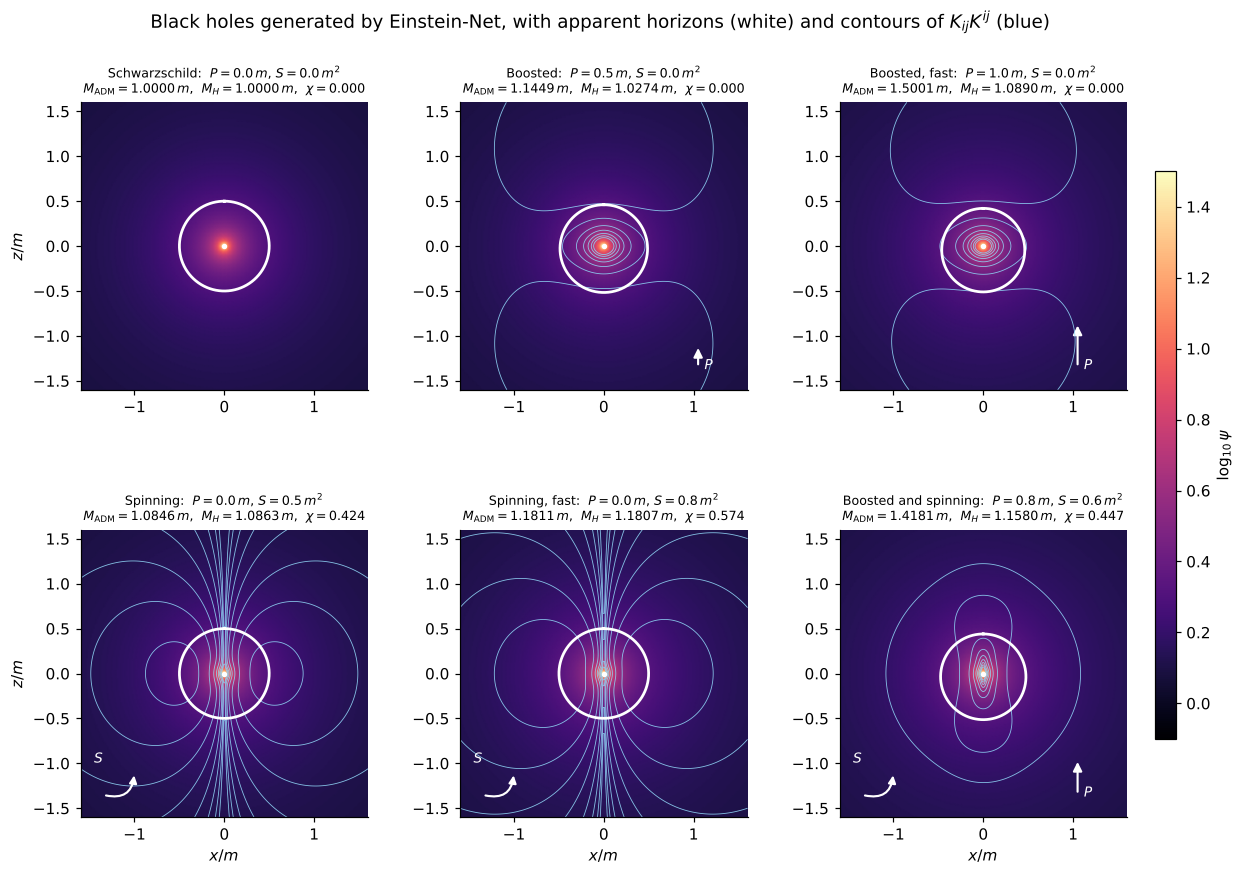

                  case |    M_ADM    M_irr      M_H    chi |    h(0)  h(pi/2)   h(pi) | max|Theta|
         Schwarzschild |   1.0000   1.0000   1.0000  0.000 |  0.5000   0.5000  0.5000 | 7e-16
               Boosted |   1.1449   1.0274   1.0274  0.000 |  0.4602   0.4865  0.5165 | 3e-07
         Boosted, fast |   1.5001   1.0890   1.0890  0.000 |  0.4198   0.4599  0.5103 | 8e-06
              Spinning |   1.0846   1.0604   1.0863  0.424 |  0.4999   0.4998  0.4996 | 2e-06
        Spinning, fast |   1.1811   1.1260   1.1807  0.574 |  0.4993   0.4991  0.4989 | 5e-06
  Boosted and spinning |   1.4181   1.1270   1.1580  0.447 |  0.4403   0.4737  0.5138 | 4e-06


In [35]:
cases = [(0.0, 0.0, 'Schwarzschild'), (0.5, 0.0, 'Boosted'), (1.0, 0.0, 'Boosted, fast'),
         (0.0, 0.5, 'Spinning'), (0.0, 0.8, 'Spinning, fast'), (0.8, 0.6, 'Boosted and spinning')]
n = 220; L = 1.6
xx, zz = np.meshgrid(np.linspace(-L, L, n), np.linspace(-L, L, n), indexing='ij')
G = np.stack([xx.ravel(), np.zeros(n*n), zz.ravel()], -1); rG = np.linalg.norm(G, axis=-1)
fig, axes = plt.subplots(2, 3, figsize=(12.6, 8.6)); fig.subplots_adjust(wspace=0.32, hspace=0.42, right=0.88)
gallery = []
for ax, (P, S, name) in zip(axes.ravel(), cases):
    bh = black_hole(P, S); gallery.append(bh)
    psi = bh['psi'](G); A = geometry.bowen_york_A(G, np.array([0, 0, P]), np.array([0, 0, S]))
    KK = (psi ** (-12)) * np.einsum('nij,nij->n', A, A)
    im = ax.pcolormesh(xx, zz, np.log10(psi).reshape(n, n), cmap='magma', vmin=-0.1, vmax=1.5, shading='gouraud', rasterized=True)
    if KK.max() > 0:
        ax.contour(xx, zz, np.log10(np.maximum(KK, 1e-12)).reshape(n, n), levels=np.arange(-5, 1.01, 0.5), colors='#8fd3f4', linewidths=0.55, alpha=0.9, negative_linestyles='solid')
    hx, hz = horizon.horizon_curve(bh['a']); ax.plot(np.r_[hx, -hx[::-1]], np.r_[hz, hz[::-1]], color='white', lw=1.8)
    ax.plot(0, 0, 'o', color='white', ms=2.5)
    if P > 0: ax.add_patch(FancyArrowPatch((1.05, -1.35), (1.05, -1.35 + 0.5 * P), arrowstyle='-|>', mutation_scale=12, color='white', lw=1.4)); ax.text(1.12, -1.38, '$P$', color='white', fontsize=9)
    if S > 0: ax.annotate('', xy=(-1.0, -1.1), xytext=(-1.35, -1.35), arrowprops=dict(arrowstyle='-|>', connectionstyle='arc3,rad=0.6', color='white', lw=1.4)); ax.text(-1.45, -1.0, '$S$', color='white', fontsize=9)
    ax.set_aspect('equal'); ax.set_xlim(-L, L); ax.set_ylim(-L, L)
    ax.set_title(f"{name}:  $P={P}\\,m$, $S={S}\\,m^2$\n$M_{{\\mathrm{{ADM}}}}={bh['M_adm']:.4f}\\,m$,  $M_H={bh['M_H']:.4f}\\,m$,  $\\chi={bh['chi']:.3f}$", fontsize=8.3)
    if ax in axes[1]: ax.set_xlabel('$x/m$')
    if ax in axes[:, 0]: ax.set_ylabel('$z/m$')
cax = fig.add_axes([0.90, 0.2, 0.015, 0.6]); cb = fig.colorbar(im, cax=cax); cb.set_label('$\\log_{10}\\psi$')
fig.suptitle('Black holes generated by Einstein-Net, with apparent horizons (white) and contours of $K_{ij}K^{ij}$ (blue)', y=0.97)
(fig.savefig if SAVE_FIGURES else (lambda *a, **k: None))(FIG + 'Figure7.png', bbox_inches='tight', dpi=300); plt.show()
print(f"{'case':>22} | {'M_ADM':>8} {'M_irr':>8} {'M_H':>8} {'chi':>6} | {'h(0)':>7} {'h(pi/2)':>8} {'h(pi)':>7} | max|Theta|")
for (P, S, name), bh in zip(cases, gallery):
    h0, h90, h180 = [np.polynomial.legendre.legval(c, bh['a']) for c in (1.0, 0.0, -1.0)]
    print(f"{name:>22} | {bh['M_adm']:8.4f} {bh['M_irr']:8.4f} {bh['M_H']:8.4f} {bh['chi']:6.3f} | {h0:7.4f} {h90:8.4f} {h180:7.4f} | {bh['max_abs_theta']:.0e}")

## 2. Two physical checks

A moving black hole carries kinetic energy, and to leading order the ADM energy of the slice should obey the special-relativistic relation $M_{\rm ADM}^2 \simeq M_H^2 + P^2$, with the remainder being gravitational radiation present on the initial slice (the "junk" of Bowen–York data). The left panel compares the network's $M_{\rm ADM}$ with $\sqrt{M_H^2 + P^2}$ built from its own horizon, against the same quantities from the classical reference. The excess is a fraction of a per cent at $P = 0.5\,m$ and about one and a half per cent at $P = m$, in both.

A spinning Bowen–York puncture cannot be spun up indefinitely. As $S$ grows, more and more of the ADM mass sits outside the horizon as radiation, and the dimensionless spin $\chi = S/M_H^2$ saturates below unity, at $\chi_{\max} \approx 0.928$ (Dain, Lousto and Zlochower 2008). The right panel shows $\chi(S)$ from the network inside its training box against the classical reference, with the reference continued beyond the box to show the saturation.

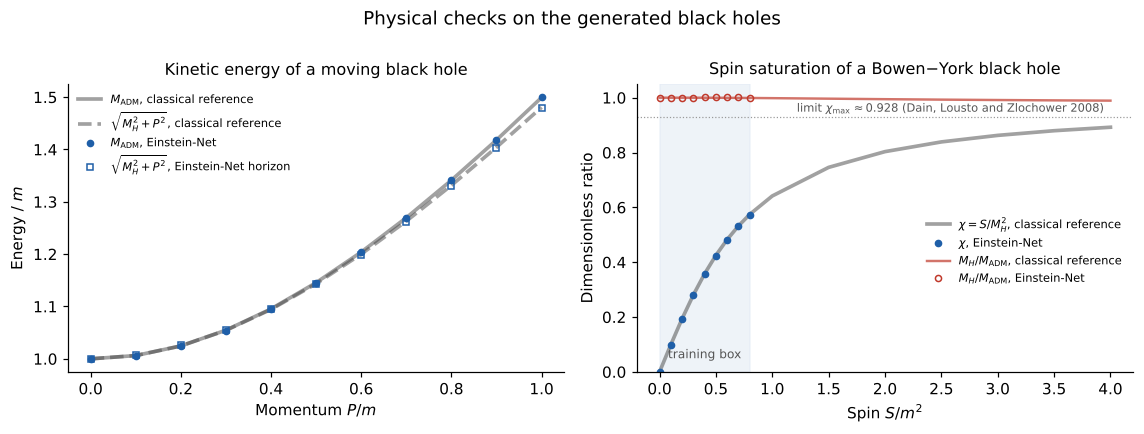

junk fraction (M_ADM - sqrt(M_H^2+P^2))/M_ADM at P = m: network 1.44%, reference 1.25%
chi at S = 0.8 m^2: network 0.5738, reference 0.5745;  reference chi at S = 4 m^2: 0.8923 (saturation below 1)
max |chi_net - chi_ref| inside the box: 2.1e-03;  max |M_ADM_net - M_ADM_ref| on the P sweep: 8.2e-04


In [36]:
Ps = np.linspace(0.0, 1.0, 11); Ss = np.linspace(0.0, 0.8, 9); Ss_ext = np.r_[Ss, np.linspace(1.0, 4.0, 7)]
kin_net, kin_ref, spin_net, spin_ref = [], [], [], []
for P in Ps:
    bh = black_hole(P, 0.0); sol = axisym.solve_puncture_axisym(P, 0.0, n_s=4000)
    Hr = horizon.find_horizon(horizon.psi_grad_from_reference(sol), [0, 0, P], [0, 0, 0.0])
    kin_net.append((bh['M_adm'], np.sqrt(bh['M_H']**2 + P**2))); kin_ref.append((sol['M_adm'], np.sqrt(Hr['M_H']**2 + P**2)))
for S in Ss_ext:
    sol = axisym.solve_puncture_axisym(0.0, S, n_s=4000)
    Hr = horizon.find_horizon(horizon.psi_grad_from_reference(sol), [0, 0, 0.0], [0, 0, S]); spin_ref.append((S, Hr['chi'], Hr['M_H'] / sol['M_adm']))
    if S <= 0.8 + 1e-9:
        bh = black_hole(0.0, S); spin_net.append((S, bh['chi'], bh['M_H'] / bh['M_adm']))
kin_net, kin_ref, spin_net, spin_ref = map(np.array, (kin_net, kin_ref, spin_net, spin_ref))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
ax = axes[0]
ax.plot(Ps, kin_ref[:, 0], color=C['ref'], lw=2.4, alpha=0.5, label='$M_{\\rm ADM}$, classical reference')
ax.plot(Ps, kin_ref[:, 1], color=C['ref'], lw=2.4, alpha=0.5, ls='--', label='$\\sqrt{M_H^2 + P^2}$, classical reference')
ax.plot(Ps, kin_net[:, 0], 'o', color=C['net'], ms=4, label='$M_{\\rm ADM}$, Einstein-Net')
ax.plot(Ps, kin_net[:, 1], 's', color=C['net'], ms=4, mfc='none', label='$\\sqrt{M_H^2 + P^2}$, Einstein-Net horizon')
ax.set_xlabel('Momentum $P/m$'); ax.set_ylabel('Energy / $m$'); ax.set_title('Kinetic energy of a moving black hole'); ax.legend(loc='upper left', fontsize=7.5)
ax = axes[1]
ax.plot(spin_ref[:, 0], spin_ref[:, 1], color=C['ref'], lw=2.4, alpha=0.5, label='$\\chi = S/M_H^2$, classical reference')
ax.plot(spin_net[:, 0], spin_net[:, 1], 'o', color=C['net'], ms=4, label='$\\chi$, Einstein-Net')
ax.plot(spin_ref[:, 0], spin_ref[:, 2], color=C['pert'], lw=1.6, alpha=0.7, label='$M_H/M_{\\rm ADM}$, classical reference')
ax.plot(spin_net[:, 0], spin_net[:, 2], 'o', color=C['pert'], ms=4, mfc='none', label='$M_H/M_{\\rm ADM}$, Einstein-Net')
ax.axvspan(0, 0.8, color=C['shade'], alpha=0.5, zorder=0); ax.text(0.4, 0.05, 'training box', ha='center', fontsize=8, color='#555555')
ax.axhline(0.928, color='#999999', lw=0.8, ls=':'); ax.text(3.95, 0.928 + 0.02, 'limit $\\chi_{\\max} \\approx 0.928$ (Dain, Lousto and Zlochower 2008)', ha='right', fontsize=7.5, color='#555555')
ax.set_xlabel('Spin $S/m^2$'); ax.set_ylabel('Dimensionless ratio'); ax.set_ylim(0, 1.05); ax.set_title('Spin saturation of a Bowen$-$York black hole'); ax.legend(loc='center right', fontsize=7.5, bbox_to_anchor=(1.0, 0.42))
fig.suptitle('Physical checks on the generated black holes', y=1.0); fig.tight_layout(); (fig.savefig if SAVE_FIGURES else (lambda *a, **k: None))(FIG + 'Figure8.png', bbox_inches='tight'); plt.show()
print(f'junk fraction (M_ADM - sqrt(M_H^2+P^2))/M_ADM at P = m: network {1 - kin_net[-1,1]/kin_net[-1,0]:.2%}, reference {1 - kin_ref[-1,1]/kin_ref[-1,0]:.2%}')
print(f'chi at S = 0.8 m^2: network {spin_net[-1,1]:.4f}, reference {spin_ref[8,1]:.4f};  reference chi at S = 4 m^2: {spin_ref[-1,1]:.4f} (saturation below 1)')
print(f'max |chi_net - chi_ref| inside the box: {np.abs(spin_net[:,1] - spin_ref[:9,1]).max():.1e};  max |M_ADM_net - M_ADM_ref| on the P sweep: {np.abs(kin_net[:,0]-kin_ref[:,0]).max():.1e}')

## 3. Asking for a black hole the network was not trained for

The network was trained on $S/m^2 \le 0.8$. Asking it for $S = 1.5\,m^2$ or $S = 3\,m^2$ is extrapolation, and nothing in the architecture prevents an answer. What should happen is that the certificate refuses it. The Gate A bound is an exact comparison-principle bound computed from the residual alone, so it does not need to know where the training box was, and it should grow where the residual grows. The table compares the certified mass bound with the true error measured against the classical solver, inside and outside the box.

In [37]:
quad_cert = invariants.spherical_quadrature(n_r=240, n_theta=16, n_phi=8, r_min=1e-4, r_max=1e5)
print(f"{'S/m^2':>6} | {'M_net':>8} {'M_ref':>8} {'true |dM|':>10} | {'evaluated |dM| bnd':>18} {'bound/error':>12} | inside box")
for S in [0.4, 0.8, 1.0, 1.5, 2.0, 3.0]:
    ga = certify.gate_a_certified_bound(net, [0, 0, 0.0], [0, 0, S], quad=quad_cert)
    Mref = axisym.reference_mass(0.0, S)['M']; err = abs(ga['M_surface'] - Mref)
    bnd = f"{ga['mass_bound']:18.1e}" if np.isfinite(ga['mass_bound']) else f"{'no bound':>18}"
    rat = f"{ga['mass_bound']/err:12.1f}" if np.isfinite(ga['mass_bound']) else f"{'':>12}"
    print(f"{S:6.1f} | {ga['M_surface']:8.4f} {Mref:8.4f} {err:10.1e} | {bnd} {rat} | {'yes' if S <= 0.8 else 'no'}")
print('Outside the box the network is wrong by a per cent at S = 1 and by orders of magnitude at S = 3. The certificate grows with the error')
print('and stays above it, and at S = 2 and 3 it returns no bound at all, because the Newton potential of the residual exceeds psi somewhere')
print('and the hypothesis psi_N > N of the bound fails, which is the certificate declaring that the output is not even approximately a solution.')

 S/m^2 |    M_net    M_ref  true |dM| | evaluated |dM| bnd  bound/error | inside box


   0.4 |   1.0569   1.0572    3.0e-04 |            6.0e-04          2.0 | yes


   0.8 |   1.1811   1.1812    5.1e-05 |            4.1e-03         80.8 | yes


   1.0 |   1.2582   1.2504    7.8e-03 |            2.0e-02          2.6 | no


   1.5 |   1.8273   1.4230    4.0e-01 |            1.3e+00          3.2 | no


   2.0 |   5.1258   1.5863    3.5e+00 |           no bound              | no


   3.0 |  56.8860   1.8807    5.5e+01 |           no bound              | no
Outside the box the network is wrong by a per cent at S = 1 and by orders of magnitude at S = 3. The certificate grows with the error
and stays above it, and at S = 2 and 3 it returns no bound at all, because the Newton potential of the residual exceeds psi somewhere
and the hypothesis psi_N > N of the bound fails, which is the certificate declaring that the output is not even approximately a solution.


## 4. Using it

Three lines give a black hole, and a fourth exports it for an evolution code. The `certified_initial_data` wrapper from the module-1 notebook adds the three gates and writes the $\gamma_{ij}$, $K_{ij}$ grid with the certificate in its metadata. What this module cannot do yet is a binary, which needs the two-puncture extension planned as module 2; everything shown here, the horizon finder included, carries over to that case unchanged.

In [38]:
bh = black_hole(0.6, 0.4)
print(f"black hole with P = 0.6 m, S = 0.4 m^2:  M_ADM = {bh['M_adm']:.5f} m,  M_H = {bh['M_H']:.5f} m,  chi = {bh['chi']:.4f},  horizon area = {bh['area']:.4f} m^2")
pts = np.array([[0.3, 0.0, 0.0], [0.0, 0.0, 0.7], [2.0, 1.0, 0.0]])
print('conformal factor at three points:', np.round(bh['psi'](pts), 6))
from einstein_net import export
meta = export.export_initial_data(net, [0, 0, 0.6], [0, 0, 0.4], 'results/einstein_net_P0.6_S0.4.npz', N=48, L=6.0,
                                  assessment=dict(M_adm=bh['M_adm'], M_H=bh['M_H'], chi=bh['chi'], horizon_coefficients=bh['a'].tolist()))
print('exported grid in', f"{meta['generated_s']:.2f} s:", {k: np.load('results/einstein_net_P0.6_S0.4.npz')[k].shape for k in ('gamma', 'K')})
json.dump([dict(P=b['P'], S=b['S'], M_adm=b['M_adm'], M_irr=b['M_irr'], M_H=b['M_H'], chi=b['chi'], a=b['a'].tolist()) for b in gallery],
          open('results/black_hole_gallery.json', 'w'), indent=1)

black hole with P = 0.6 m, S = 0.4 m^2:  M_ADM = 1.24843 m,  M_H = 1.08885 m,  chi = 0.3374,  horizon area = 57.8470 m^2
conformal factor at three points: [2.747683 1.776643 1.258002]


exported grid in 0.12 s: {'gamma': (48, 48, 48, 3, 3), 'K': (48, 48, 48, 3, 3)}


---
# Part III. Revision analysis (optional, `RUN_HEAVY = True`)

The two-dimensional error surface over the training box (Figure 10 of the paper, with maximum, median and 95th percentile of the mass and supremum errors and both evaluated bounds), the independent held-out test of the calibrated gate with the threshold frozen, the quadrature study of the bound at three resolutions with the truncation estimates, the separated timings, and the horizon-finder and reference-solver convergence checks. This reproduces `scripts/revision_analysis.py` of the repository.

In [39]:
%%writefile revision_analysis.py
"""Revision analysis for paper 1 (run from papers/01-black-holes).

A. Two-dimensional error surface over the training box: mass error, sup error, certified
   bounds, with max / median / 95th percentile statistics.
B. Independent held-out test of the calibrated gate with the threshold frozen.
C. Quadrature study of the certificate: three quadrature resolutions, truncation-region
   bounds, and the psi_N > N check on an independent fine sampling.
D. Separated timings and a matched-accuracy comparison with the 3D solver.
F. Horizon-finder convergence in the number of modes and nodes.
G. Reference-solver error budget (angular truncation, compactification scale, Newton residual).
Everything is written to results/revision_*.json and figures/Figure6.png.
"""
import sys, json, time
sys.path.insert(0, '.')
import numpy as np, torch
torch.set_default_dtype(torch.float64)
import matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
from einstein_net import geometry, invariants, certify, axisym, classical, horizon, plotting
from einstein_net.model import EinsteinNet
plotting.apply_style(); C = plotting.C
net = EinsteinNet(width=64, depth=4); net.load_state_dict(torch.load('results/einstein_net_v1.pt'))
quad = invariants.spherical_quadrature(n_r=240, n_theta=16, n_phi=8, r_min=1e-4, r_max=1e5)
Xq = quad[0].numpy(); near = np.linalg.norm(Xq, axis=-1) < 50
out = {}
T0 = time.time()

def true_errors(P, S):
    sol = axisym.solve_puncture_axisym(P, S, n_s=4000)
    ref = axisym.reference_mass(P, S)['M']
    ue = np.abs(net.u_numpy(Xq[near], [0, 0, P], [0, 0, S]) - axisym.u_axisym_at(sol, Xq[near])).max()
    return ref, ue

# ---------------- A. error surface ----------------
Ps = np.linspace(0, 1, 11); Ss = np.linspace(0, 0.8, 9)
grid = []
for P in Ps:
    for S in Ss:
        if P == 0 and S == 0:
            grid.append(dict(P=0.0, S=0.0, M_ref=1.0, M_head=1.0, M_vol=1.0, sup_e_true=0.0, sup_e_bound=0.0, mass_bound=0.0, l2=0.0)); continue
        ref, ue = true_errors(float(P), float(S))
        ga = certify.gate_a_certified_bound(net, [0, 0, P], [0, 0, S], quad=quad)
        grid.append(dict(P=float(P), S=float(S), M_ref=ref, M_head=ga['M_surface'], M_vol=ga['M_volume'],
                         sup_e_true=float(ue), sup_e_bound=ga['sup_e'], mass_bound=ga['mass_bound'], l2=ga['l2']))
    print(f'A: P={P:.1f} done, {time.time()-T0:.0f} s', flush=True)
dM = np.array([abs(g['M_head'] - g['M_ref']) for g in grid]); rel = dM / np.array([g['M_ref'] for g in grid])
dMv = np.array([abs(g['M_vol'] - g['M_ref']) for g in grid])
ue = np.array([g['sup_e_true'] for g in grid]); ub = np.array([g['sup_e_bound'] for g in grid]); mb = np.array([g['mass_bound'] for g in grid])
nz = dM > 0
stats = dict(n=len(grid), mass_err_max=float(dM.max()), mass_err_median=float(np.median(dM)), mass_err_p95=float(np.percentile(dM, 95)),
             mass_rel_max=float(rel.max()), mass_rel_median=float(np.median(rel)), mass_rel_p95=float(np.percentile(rel, 95)),
             mass_vol_err_max=float(dMv.max()), sup_e_max=float(ue.max()), sup_e_median=float(np.median(ue)), sup_e_p95=float(np.percentile(ue, 95)),
             bound_holds_mass=bool(np.all(mb[nz] >= dM[nz])), bound_holds_sup=bool(np.all(ub[nz] >= ue[nz])),
             mass_bound_over_err_min=float((mb[nz] / dM[nz]).min()), mass_bound_over_err_median=float(np.median(mb[nz] / dM[nz])), mass_bound_over_err_max=float((mb[nz] / dM[nz]).max()),
             sup_bound_over_err_min=float((ub[nz] / ue[nz]).min()), sup_bound_over_err_median=float(np.median(ub[nz] / ue[nz])), sup_bound_over_err_max=float((ub[nz] / ue[nz]).max()),
             frac_mass_err_below_1e3=float(np.mean(dM < 1e-3)), argmax=grid[int(dM.argmax())])
out['A_grid'] = grid; out['A_stats'] = stats
print('A stats', json.dumps(stats, indent=1, default=float), flush=True)

fig, axes = plt.subplots(2, 2, figsize=(10, 7.6))
PP, SS = np.meshgrid(Ps, Ss, indexing='ij')
def surf(ax, vals, title, vmin, vmax):
    v = np.array(vals).reshape(len(Ps), len(Ss)); v = np.maximum(v, vmin)
    im = ax.pcolormesh(PP, SS, v, shading='nearest', cmap='viridis', norm=matplotlib.colors.LogNorm(vmin=vmin, vmax=vmax))
    ax.set_title(title); ax.set_xlabel('Momentum $P/m$'); ax.set_ylabel('Spin $S/m^2$'); return im
im = surf(axes[0, 0], dM, 'True ADM mass error $|M_N - M_{\\mathrm{ADM}}|/m$', 1e-5, 3e-2)
surf(axes[0, 1], mb, 'Numerically evaluated mass bound', 1e-5, 3e-2)
surf(axes[1, 0], ue, 'True error $\\sup|e|$ (against the reference)', 1e-5, 3e-2)
surf(axes[1, 1], ub, 'Numerically evaluated bound on $\\sup|e|$', 1e-5, 3e-2)
fig.tight_layout(); cb = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.02); cb.set_label('Error or bound (geometric units)')
fig.savefig('figures/Figure6.png', bbox_inches='tight', dpi=300); plt.close(fig)

# ---------------- B. held-out test ----------------
cal = json.load(open('results/results_module1.json'))['gate_c']; thr = cal['threshold']; tau = cal['tau']
rng = np.random.default_rng(20261026); test = []
for k in range(40):
    P, S = float(rng.uniform(0, 1)), float(rng.uniform(0, 0.8))
    ref = axisym.reference_mass(P, S)['M']
    ga = certify.gate_a_certified_bound(net, [0, 0, P], [0, 0, S], quad=quad)
    test.append(dict(P=P, S=S, M_ref=ref, M_head=ga['M_surface'], err=abs(ga['M_surface'] - ref), proxy=ga['mass_bound'], passed=bool(ga['mass_bound'] <= thr)))
npass = sum(t['passed'] for t in test); nfail = sum(t['passed'] and t['err'] > tau for t in test)
out['B_test'] = dict(threshold=thr, tau=tau, cases=test, n=40, n_pass=npass, n_pass_exceed_tau=nfail,
                     cp_upper_95=certify.clopper_pearson_upper(nfail, npass) if npass else None,
                     err_max=max(t['err'] for t in test), err_median=float(np.median([t['err'] for t in test])), proxy_max=max(t['proxy'] for t in test))
print('B', {k: v for k, v in out['B_test'].items() if k != 'cases'}, flush=True)

# ---------------- C. quadrature study ----------------
cases = [(0.2, 0.0), (0.5, 0.0), (0.0, 0.5), (0.5, 0.5), (1.0, 0.0), (0.0, 0.8), (1.0, 0.8)]
quads = {'coarse (120,8,4)': invariants.spherical_quadrature(n_r=120, n_theta=8, n_phi=4, r_min=1e-4, r_max=1e5),
         'default (240,16,8)': quad,
         'fine (360,24,12)': invariants.spherical_quadrature(n_r=360, n_theta=24, n_phi=12, r_min=1e-4, r_max=1e5)}
qstudy = []
for P, S in cases:
    row = dict(P=P, S=S)
    for name, q in quads.items():
        t = time.time(); ga = certify.gate_a_certified_bound(net, [0, 0, P], [0, 0, S], quad=q)
        row[name] = dict(sup_e=ga['sup_e'], mass_bound=ga['mass_bound'], l2=ga['l2'], time=time.time() - t, positivity_ok=ga['positivity_ok'])
    qstudy.append(row); print('C', P, S, {k: (round(v['sup_e'], 6), round(v['mass_bound'], 6)) for k, v in row.items() if isinstance(v, dict)}, flush=True)
# relative change default -> fine
chg_sup = [abs(r['fine (360,24,12)']['sup_e'] - r['default (240,16,8)']['sup_e']) / r['fine (360,24,12)']['sup_e'] for r in qstudy]
chg_mb = [abs(r['fine (360,24,12)']['mass_bound'] - r['default (240,16,8)']['mass_bound']) / r['fine (360,24,12)']['mass_bound'] for r in qstudy]
# truncation regions and positivity on an independent sampling, for the worst case (1.0, 0.8) and a mid case (0.5, 0.5)
trunc = {}
for P, S in [(0.5, 0.5), (1.0, 0.8)]:
    Pv, Sv = [0, 0, P], [0, 0, S]
    # inner region r < 1e-4: |R| there, contribution to N at the origin <= max|R| eps^2 / 2
    rr = np.geomspace(1e-7, 1e-4, 200); d = np.array([[np.sin(0.7) * np.cos(1.1), np.sin(0.7) * np.sin(1.1), np.cos(0.7)], [0, 0, 1.0], [1.0, 0, 0]])
    Xin = (rr[:, None, None] * d[None]).reshape(-1, 3)
    Rin, _ = invariants.residual_on(net, torch.as_tensor(Xin), Pv, Sv)
    # the residual behaves as c/r at the puncture (the compactified radius has a kink there), which is
    # integrable; with |R| <= c/r for r < eps the contribution to N at the origin is at most c eps
    c_in = float((np.abs(Rin) * np.repeat(rr, 3)).max()); inner = c_in * 1e-4
    # outer region r > 1e5: fit |R| <= C r^-4 from samples at 1e5..1e7, contribution <= C/(2 R^2) for |x| << R
    ro = np.geomspace(1e5, 1e7, 60); Xo = (ro[:, None, None] * d[None]).reshape(-1, 3)
    Ro, _ = invariants.residual_on(net, torch.as_tensor(Xo), Pv, Sv)
    Cfit = float((np.abs(Ro) * np.repeat(ro, 3) ** 4).max()); outer = Cfit / (2 * 1e10)
    # positivity psi_N > N on 20000 independent random points (log-uniform radii 1e-4..1e5)
    g = np.random.default_rng(7); n = 20000
    r = 10 ** g.uniform(-4, 5, n); dd = g.standard_normal((n, 3)); dd /= np.linalg.norm(dd, axis=-1, keepdims=True); Xr = r[:, None] * dd
    R, psi = invariants.residual_on(net, quad[0], Pv, Sv)
    # Newton potential at the random points from the default quadrature
    Xt = torch.as_tensor(Xr); wf = torch.as_tensor(quad[1].numpy() * np.abs(R)); Nr = np.empty(n)
    for i in range(0, n, 2000):
        dmat = torch.cdist(Xt[i:i + 2000], quad[0]); Nr[i:i + 2000] = (wf / dmat).sum(-1).numpy() / (4 * np.pi)
    psir = net.psi_numpy(Xr, Pv, Sv)
    trunc[f'P={P},S={S}'] = dict(inner_c=c_in, inner_contrib=inner, outer_C=Cfit, outer_contrib=outer,
                                  min_margin_random=float((psir - Nr).min()), max_N_random=float(Nr.max()), max_N_quad_nodes=float(certify.newton_potential(Xq, quad[1].numpy(), np.abs(R)).max()))
out['C_quadrature'] = dict(cases=qstudy, rel_change_sup_default_to_fine=chg_sup, rel_change_mass_default_to_fine=chg_mb, truncation=trunc)
print('C rel changes', max(chg_sup), max(chg_mb), trunc, flush=True)

# ---------------- D. timings ----------------
P, S = 0.4, 0.3; Pv, Sv = [0, 0, P], [0, 0, S]
c = np.linspace(-8, 8, 65)[:-1] + 8 / 64; X, Y, Z = np.meshgrid(c, c, c, indexing='ij'); G = np.stack([X.ravel(), Y.ravel(), Z.ravel()], -1)
t = time.time(); psi_grid = net.psi_numpy(G, Pv, Sv); t_inf = time.time() - t
t = time.time(); A = geometry.bowen_york_A(G, np.array(Pv), np.array(Sv)); K = (psi_grid ** (-2))[:, None, None] * A; gam = (psi_grid ** 4); t_asm = time.time() - t
t = time.time(); H = horizon.find_horizon(horizon.psi_grad_from_network(net, Pv, Sv), Pv, Sv); t_hor = time.time() - t
t = time.time(); ga = certify.gate_a_certified_bound(net, Pv, Sv, quad=quad); t_cert = time.time() - t
t = time.time(); sol = axisym.solve_puncture_axisym(P, S, n_s=2000); u_ax = axisym.u_axisym_at(sol, G); t_ax = time.time() - t
sol4 = axisym.solve_puncture_axisym(P, S, n_s=4000)
err_net = float(np.abs(psi_grid - (1 + 1 / (2 * np.linalg.norm(G, axis=-1)) + axisym.u_axisym_at(sol4, G))).max())
fd = {}
for N in (64, 96, 128):
    r = classical.solve_puncture_fd(np.array(Pv), np.array(Sv), N=N, L=8.0)
    fd[N] = dict(time=r['time'], err=float(np.abs(r['u'] - axisym.u_axisym_at(sol4, r['x'])).max()), h=r['h'])
    print('D FD', N, fd[N], flush=True)
out['D_timing'] = dict(inference_64cubed=t_inf, assembly_gamma_K=t_asm, horizon=t_hor, certificate=t_cert, total_certified=t_inf + t_asm + t_hor + t_cert,
                       axisym_solver=t_ax, net_err_on_grid=err_net, fd=fd, threads=torch.get_num_threads())
print('D', out['D_timing'], flush=True)

# ---------------- F. horizon finder convergence ----------------
hconv = []
for nl in (8, 12, 16):
    for nt in (24, 40, 64):
        for P, S in [(0.5, 0.5), (1.0, 0.0)]:
            Hh = horizon.find_horizon(horizon.psi_grad_from_network(net, [0, 0, P], [0, 0, S]), [0, 0, P], [0, 0, S], n_l=nl, n_theta=nt)
            hconv.append(dict(P=P, S=S, n_l=nl, n_theta=nt, area=Hh['area'], M_H=Hh['M_H'], chi=Hh['chi'], max_theta=Hh['max_abs_theta']))
for P, S in [(0.5, 0.5), (1.0, 0.0)]:
    a = [h['area'] for h in hconv if h['P'] == P and h['S'] == S]; print('F', P, S, 'area spread', (max(a) - min(a)) / np.mean(a), flush=True)
out['F_horizon'] = hconv

# ---------------- G. reference solver error budget ----------------
gref = []
for nl, nmu, rc in [(6, 40, 1.0), (10, 40, 1.0), (16, 64, 1.0), (10, 40, 0.5), (10, 40, 2.0)]:
    s = axisym.solve_puncture_axisym(0.5, 0.5, n_s=2000, n_l=nl, n_mu=nmu, r_c=rc)
    gref.append(dict(n_l=nl, n_mu=nmu, r_c=rc, M_vol=s['M_volume'], M_surf=s['M_surface'], newton_residual=s['residual']))
Ms = [g['M_vol'] for g in gref]; out['G_reference'] = dict(variants=gref, spread=max(Ms) - min(Ms), richardson=axisym.reference_mass(0.5, 0.5))
print('G spread', max(Ms) - min(Ms), flush=True)

def _default(o):
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return str(o)
json.dump(out, open('results/revision_analysis.json', 'w'), indent=1, default=_default)
print('done', time.time() - T0)


Writing revision_analysis.py


In [40]:
if RUN_HEAVY:
    import runpy
    runpy.run_path('revision_analysis.py', run_name='__main__')   # writes results/revision_analysis.json and figures/Figure6.png
    from IPython.display import Image, display
    display(Image('figures/Figure6.png', width=900))
else:
    print('RUN_HEAVY is False; set it to True at the top to reproduce the error surface, the held-out test and the quadrature study (about 40 min).')

RUN_HEAVY is False; set it to True at the top to reproduce the error surface, the held-out test and the quadrature study (about 40 min).


---
# Part IV. The third gate on two thousand reference cases (v2.0)

One thousand calibration and one thousand test parameter pairs, drawn uniformly from the training box with distinct seeds, each solved by the axisymmetric reference solver with Richardson extrapolation (error about $10^{-8}$). The acceptance proxy is the Gate A bound evaluated on the quadrature $(160, 12, 6)$. The threshold is selected by Learn-then-Test with fixed-sequence testing, which controls the family-wise error without assuming that the conditional risk is monotone in the threshold, and then frozen and tested on the independent set. With the default switches the embedded tables are used and only the calibration, the test and the figure are recomputed (seconds); with `RUN_LARGE_GATE_C = True` the reference masses (about 1.5 h) and the proxies (about 1 h) are recomputed first.

In [41]:
%%writefile make_reference_large.py
"""Large calibration and test sets for Gate C (run from papers/01-black-holes).

1,000 calibration and 1,000 test parameter pairs, drawn uniformly from the training box
P/m in [0, 1], S/m^2 in [0, 0.8] with seeds distinct from the 40/40 sets of v1.2, each
solved with the axisymmetric reference solver and Richardson extrapolation (n_s = 1000,
2000, 4000).  Two worker processes write partial files that are merged at the end into
results/reference_masses_large.json.  Usage:  python make_reference_large.py [worker_id n_workers]
"""
import json, sys, time, os
import numpy as np
sys.path.insert(0, '.')
from einstein_net.axisym import reference_mass

N_CAL, N_TEST = 1000, 1000
rng_cal = np.random.default_rng(20261027)
rng_test = np.random.default_rng(20261028)
cal = np.stack([rng_cal.uniform(0, 1, N_CAL), rng_cal.uniform(0, 0.8, N_CAL)], 1)
test = np.stack([rng_test.uniform(0, 1, N_TEST), rng_test.uniform(0, 0.8, N_TEST)], 1)
cases = [('calibration', i, *cal[i]) for i in range(N_CAL)] + [('test', i, *test[i]) for i in range(N_TEST)]

if len(sys.argv) == 3:
    wid, nw = int(sys.argv[1]), int(sys.argv[2])
    mine = cases[wid::nw]
    out_path = f'results/_ref_large_part{wid}.json'
    done = {}
    if os.path.exists(out_path):
        done = {(d['set'], d['i']): d for d in json.load(open(out_path))}
    t0 = time.time()
    for k, (which, i, P, S) in enumerate(mine):
        if (which, i) in done:
            continue
        ref = reference_mass(float(P), float(S))
        done[(which, i)] = dict(set=which, i=i, P=float(P), S=float(S), M=float(ref['M']), err=float(ref['err_est']), order=float(ref['order']))
        if k % 10 == 0:
            json.dump(list(done.values()), open(out_path, 'w'))
            print(f'worker {wid}: {len(done)}/{len(mine)} done, {time.time() - t0:.0f} s', flush=True)
    json.dump(list(done.values()), open(out_path, 'w'))
    print(f'worker {wid} finished in {time.time() - t0:.0f} s')
else:
    parts = []
    for f in sorted(os.listdir('results')):
        if f.startswith('_ref_large_part'):
            parts += json.load(open('results/' + f))
    out = dict(calibration=sorted([d for d in parts if d['set'] == 'calibration'], key=lambda d: d['i']),
               test=sorted([d for d in parts if d['set'] == 'test'], key=lambda d: d['i']),
               seeds=dict(calibration=20261027, test=20261028), n_s_list=[1000, 2000, 4000])
    json.dump(out, open('results/reference_masses_large.json', 'w'), indent=1)
    print(len(out['calibration']), 'calibration and', len(out['test']), 'test cases merged')


Writing make_reference_large.py


In [42]:
%%writefile gate_c_large.py
"""Gate C on the large calibration and test sets (run from papers/01-black-holes).

Step 1 (proxies): for every case in results/reference_masses_large.json compute the network mass
and the Gate A bound evaluated on the quadrature Q_c = (160, 12, 6) on [1e-4, 1e5], which is the
acceptance proxy.  Step 2 (calibration): Learn-then-Test with fixed-sequence testing over a prespecified,
data-independent grid of thresholds (41 values log-spaced on [2e-3, 3e-2] m, fixed from the
forty-case sample of v1.2) from conservative
to liberal, which controls the family-wise error at level delta without any monotonicity
assumption on the conditional risk.  Step 3 (test): the selected threshold is frozen and applied to the
independent test set; the Clopper-Pearson upper bound on the conditional failure probability is
reported.  Usage: python gate_c_large.py proxies [worker n_workers] | calibrate
"""
import sys, json, time, os
import numpy as np, torch
sys.path.insert(0, '.')
torch.set_default_dtype(torch.float64)
from scipy.stats import binom, beta as beta_dist

TAU = 2e-3            # tolerance on the ADM-mass error (units of m)
ALPHA = 0.01          # target conditional failure probability
DELTA = 0.05          # error level of the calibration statement

if sys.argv[1] == 'proxies':
    from einstein_net.model import EinsteinNet
    from einstein_net import invariants
    from einstein_net.certify import gate_a_certified_bound
    wid, nw = (int(sys.argv[2]), int(sys.argv[3])) if len(sys.argv) > 3 else (0, 1)
    model = EinsteinNet(width=64, depth=4); model.load_state_dict(torch.load('results/einstein_net_v1.pt')); model.eval()
    quad = invariants.spherical_quadrature(n_r=160, n_theta=12, n_phi=6, r_min=1e-4, r_max=1e5)
    ref = json.load(open('results/reference_masses_large.json'))
    cases = [(w, d) for w in ('calibration', 'test') for d in ref[w]][wid::nw]
    out_path = f'results/_gate_c_proxies_part{wid}.json'
    done = {(d['set'], d['i']): d for d in json.load(open(out_path))} if os.path.exists(out_path) else {}
    t0 = time.time()
    for k, (w, d) in enumerate(cases):
        if (w, d['i']) in done:
            continue
        Pv, Sv = [0.0, 0.0, d['P']], [0.0, 0.0, d['S']]
        g = gate_a_certified_bound(model, Pv, Sv, quad)
        M_head = model.adm_mass(Pv, Sv)
        done[(w, d['i'])] = dict(set=w, i=d['i'], P=d['P'], S=d['S'], M_ref=d['M'], M_head=M_head,
                                 error=abs(M_head - d['M']), proxy=float(g['mass_bound']), sup_e_bound=float(g['sup_e']), positivity_ok=bool(g['positivity_ok']))
        if k % 20 == 0:
            json.dump(list(done.values()), open(out_path, 'w'))
            print(f'worker {wid}: {len(done)}/{len(cases)}  {time.time() - t0:.0f} s', flush=True)
    json.dump(list(done.values()), open(out_path, 'w')); print('done', time.time() - t0)

elif sys.argv[1] == 'calibrate':
    parts = []
    for f in sorted(os.listdir('results')):
        if f.startswith('_gate_c_proxies_part'):
            parts += json.load(open('results/' + f))
    cal = sorted([d for d in parts if d['set'] == 'calibration'], key=lambda d: d['i'])
    tst = sorted([d for d in parts if d['set'] == 'test'], key=lambda d: d['i'])
    pc = np.array([d['proxy'] for d in cal]); ec = np.array([d['error'] for d in cal])
    pt = np.array([d['proxy'] for d in tst]); et = np.array([d['error'] for d in tst])

    def cp_upper(k, n, conf=0.95):
        return 1.0 if k >= n else float(beta_dist.ppf(conf, k + 1, n - k))

    # The candidate thresholds are prespecified and independent of the calibration data: 41 values
    # log-spaced from 2e-3 m, the median proxy of the independent forty-case sample of v1.2 (so that
    # about half of the cases are accepted at the first threshold and a rejection is possible), to
    # 3e-2 m, above the largest proxy seen in the box, tested in increasing order.  Fixed-sequence
    # testing then controls the family-wise error at level DELTA.
    GRID = np.geomspace(2e-3, 3e-2, 41)

    def ltt(tau, alpha, delta=DELTA):
        """Fixed-sequence Learn-then-Test over the prespecified thresholds, from conservative to liberal."""
        grid = GRID; sel = None; table = []
        for lam in grid:
            m = pc <= lam; n = int(m.sum()); k = int((ec[m] > tau).sum()); pval = float(binom.cdf(k, n, alpha))
            table.append(dict(lam=float(lam), n=n, k=k, p=pval))
            if pval <= delta:
                sel = float(lam)
            else:
                break
        return sel, table

    viol = [d for d in cal + tst if d['proxy'] < d['error']]
    print(f'{len(cal)} calibration, {len(tst)} test cases; errors: cal median {np.median(ec):.2e} p95 {np.quantile(ec, .95):.2e} max {ec.max():.2e}; test median {np.median(et):.2e} p95 {np.quantile(et, .95):.2e} max {et.max():.2e}')
    print(f'coarse-quadrature proxy below the true error in {len(viol)} cases (max P {max([d["P"] for d in viol] or [0]):.3f}, max S {max([d["S"] for d in viol] or [0]):.3f}, min ratio {min([d["proxy"] / d["error"] for d in viol] or [1]):.3f})')
    results = []
    for tau in (1e-3, 2e-3):
        for alpha in (0.01, 0.02):
            sel, table = ltt(tau, alpha)
            if sel is None:
                print(f'tau={tau:.0e} alpha={alpha}: no threshold'); continue
            mt = pt <= sel; n = int(mt.sum()); k = int((et[mt] > tau).sum())
            rec = dict(tau=tau, alpha=alpha, delta=DELTA, threshold=sel, cal_accept_frac=float((pc <= sel).mean()),
                       cal_fail_frac=float((ec > tau).mean()), test_fail_frac=float((et > tau).mean()),
                       test_accepted=n, test_failures=k, test_cp_upper=cp_upper(k, n), test_rejected_fine=int(((~mt) & (et <= tau)).sum()),
                       test_caught=int(((~mt) & (et > tau)).sum()), test_total_fail=int((et > tau).sum()), table=table)
            results.append(rec)
            print(f"tau={tau:.0e} alpha={alpha}: lambda={sel:.3e}, accept cal {rec['cal_accept_frac'] * 100:.1f}%, test accepted {n}/1000 with {k} failures, CP U(k,n)={rec['test_cp_upper']:.4f}, rejected-but-fine {rec['test_rejected_fine']}, caught {rec['test_caught']}/{rec['test_total_fail']}")
    out = dict(delta=DELTA, n_cal=len(cal), n_test=len(tst), results=results, grid=dict(lo=2e-3, hi=3e-2, n=41, spacing='geometric', prespecified=True, origin='median proxy of the forty-case v1.2 calibration sample to above the largest proxy in the box'),
               cal_stats=dict(err_median=float(np.median(ec)), err_p95=float(np.quantile(ec, 0.95)), err_max=float(ec.max()), proxy_median=float(np.median(pc)), ratio_median=float(np.median(pc / np.maximum(ec, 1e-12))), ratio_min=float((pc / np.maximum(ec, 1e-12)).min())),
               test_stats=dict(err_median=float(np.median(et)), err_p95=float(np.quantile(et, 0.95)), err_max=float(et.max())),
               coarse_proxy_violations=dict(n=len(viol), cases=[dict(P=d['P'], S=d['S'], error=d['error'], proxy=d['proxy']) for d in viol]),
               quadrature='spherical_quadrature(160, 12, 6) on [1e-4, 1e5]')
    json.dump(out, open('results/gate_c_large.json', 'w'), indent=1)
    print('written results/gate_c_large.json')


Writing gate_c_large.py


In [43]:
%%writefile plot_gate_c_large.py
"""Figure: Gate C on the large calibration and test sets (run from papers/01-black-holes).

Left: evaluated bound (proxy) against the true mass error for the 1,000 calibration and 1,000 test
cases, with the diagonal, the tolerance tau = 1e-3 m and the Learn-then-Test threshold at alpha = 1%.
Right: conditional failure rate on the test set as a function of the threshold, with the
Clopper-Pearson 95% upper bound and the selected threshold.  Written to figures/Figure10.png (the manuscript's Figure 10; the forty-case calibration figure of v1.2 is kept as Figure10_v1_calibration40.png).
"""
import json, os, sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
sys.path.insert(0, '.')
from einstein_net import plotting
from scipy.stats import beta as beta_dist

plotting.apply_style(); plt.rcParams.update({'font.size': 10, 'axes.labelsize': 11, 'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5})
parts = []
for f in sorted(os.listdir('results')):
    if f.startswith('_gate_c_proxies_part'):
        parts += json.load(open('results/' + f))
cal = [d for d in parts if d['set'] == 'calibration']; tst = [d for d in parts if d['set'] == 'test']
pc = np.array([d['proxy'] for d in cal]); ec = np.array([d['error'] for d in cal])
pt = np.array([d['proxy'] for d in tst]); et = np.array([d['error'] for d in tst])
G = json.load(open('results/gate_c_large.json'))
rec = [r for r in G['results'] if r['tau'] == 1e-3 and r['alpha'] == 0.01][0]
lam, tau = rec['threshold'], rec['tau']

fig, axes = plt.subplots(2, 1, figsize=(7.4, 9.6))
ax = axes[0]
ax.loglog(ec, pc, 'o', ms=3.2, mfc='#2c7fb8', mec='none', alpha=0.55, label='Calibration (1,000)')
ax.loglog(et, pt, 's', ms=3.2, mfc='#d95f0e', mec='none', alpha=0.55, label='Test (1,000)')
lim = [1e-6, 3e-2]
ax.plot(lim, lim, '-', color='#555555', lw=1.0, label='Bound equals error')
ax.axvline(tau, color='#1e8449', lw=1.0, ls='--', label=r'Tolerance $\tau = 10^{-3}\,m$')
ax.axhline(lam, color='#8e44ad', lw=1.0, ls=':', label=r'Threshold $\lambda^\star$')
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel(r'True mass error $|M_N - M|/m$'); ax.set_ylabel(r'Evaluated bound (proxy) $/m$')
ax.legend(loc='lower right', fontsize=9, frameon=False)
ax.set_title('Proxy against true error over the box', fontsize=11)

ax = axes[1]
lams = np.geomspace(2e-3, 3e-2, 121)
rate, ucb, acc = [], [], []
for l in lams:
    m = pt <= l; n = int(m.sum()); k = int((et[m] > tau).sum())
    rate.append(k / n); ucb.append(1.0 if k >= n else beta_dist.ppf(0.95, k + 1, n - k)); acc.append(n / len(pt))
ax.semilogx(lams, np.array(rate) * 100, '-', color='#2c7fb8', lw=1.4, label='Conditional failure rate (test)')
ax.semilogx(lams, np.array(ucb) * 100, '-', color='#d95f0e', lw=1.4, label='Clopper–Pearson 95% upper bound')
ax.semilogx(lams, np.array(acc) * 100 / 50, ':', color='#555555', lw=1.0, label='Acceptance rate / 50')
ax.axvline(lam, color='#8e44ad', lw=1.0, ls=':')
ax.axhline(100 * rec['alpha'], color='#1e8449', lw=1.0, ls='--', label=r'Target risk $\alpha = 1\%$')
ax.set_xlabel(r'Threshold $\lambda$ on the proxy $/m$'); ax.set_ylabel('Per cent')
ax.set_ylim(0, 3.2)
ax.legend(loc='upper left', fontsize=9, frameon=False)
ax.set_title(r'Risk of accepted outputs ($\tau = 10^{-3}\,m$)', fontsize=11)
fig.tight_layout()
os.makedirs('figures', exist_ok=True)
fig.savefig('figures/Figure10.png', dpi=300, bbox_inches='tight')
print('written figures/Figure10.png; threshold', lam)


Writing plot_gate_c_large.py


1000 calibration, 1000 test cases; errors: cal median 3.85e-04 p95 8.49e-04 max 2.06e-03; test median 3.73e-04 p95 8.37e-04 max 2.56e-03
coarse-quadrature proxy below the true error in 16 cases (max P 0.089, max S 0.070, min ratio 0.954)
tau=1e-03 alpha=0.01: lambda=5.908e-03, accept cal 90.1%, test accepted 918/1000 with 4 failures, CP U(k,n)=0.0099, rejected-but-fine 69, caught 13/17
tau=1e-03 alpha=0.02: lambda=7.239e-03, accept cal 93.7%, test accepted 952/1000 with 10 failures, CP U(k,n)=0.0178, rejected-but-fine 41, caught 7/17
tau=2e-03 alpha=0.01: lambda=3.000e-02, accept cal 100.0%, test accepted 1000/1000 with 1 failures, CP U(k,n)=0.0047, rejected-but-fine 0, caught 0/1
tau=2e-03 alpha=0.02: lambda=3.000e-02, accept cal 100.0%, test accepted 1000/1000 with 1 failures, CP U(k,n)=0.0047, rejected-but-fine 0, caught 0/1
written results/gate_c_large.json


written figures/Figure10.png; threshold 0.005908353878125557


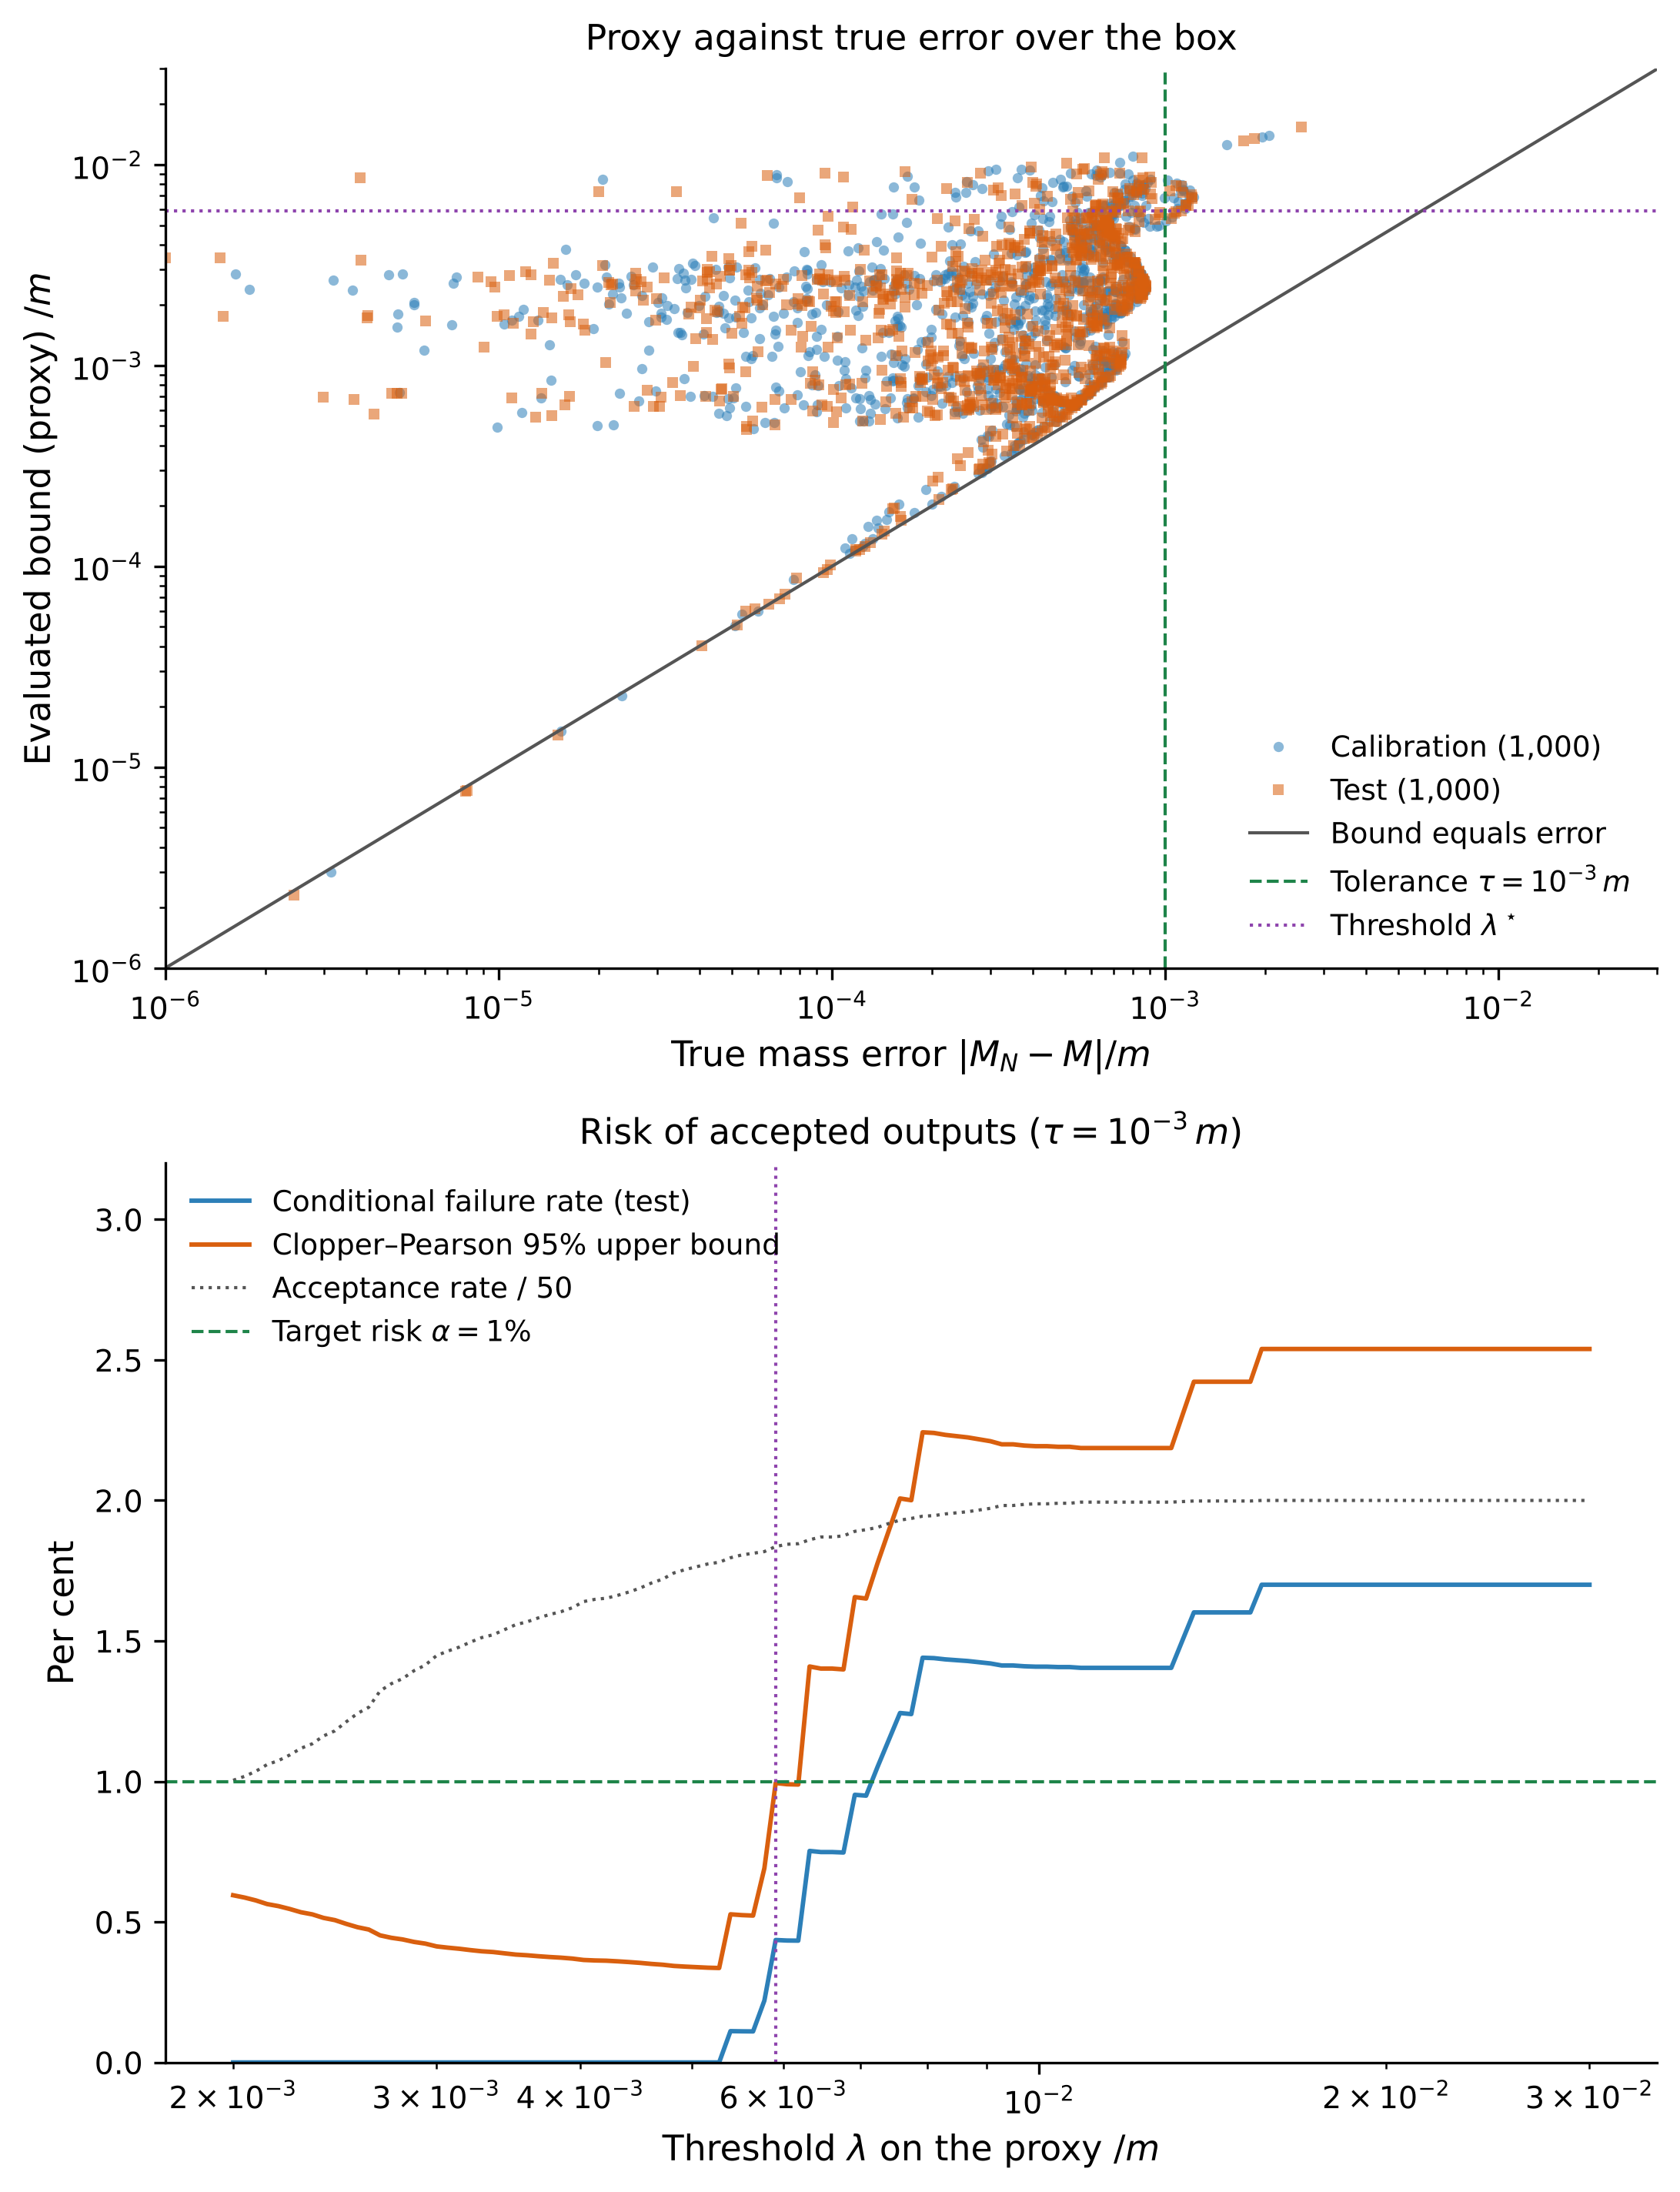

tau     alpha   threshold   cal accepted   test accepted  failures  Clopper-Pearson U   caught
1e-03  0.01   5.908e-03    90.1%         918/1000        4      0.0099          13/17
1e-03  0.02   7.239e-03    93.7%         952/1000       10      0.0178          7/17
2e-03  0.01   3.000e-02   100.0%        1000/1000        1      0.0047          0/1
2e-03  0.02   3.000e-02   100.0%        1000/1000        1      0.0047          0/1

coarse-proxy bound below the true error in 16 cases, all weak field (max P 0.089, max S 0.070)


In [44]:
import subprocess, sys, json
if RUN_LARGE_GATE_C:
    subprocess.run([sys.executable, 'make_reference_large.py', '0', '1'], check=True)
    subprocess.run([sys.executable, 'make_reference_large.py'], check=True)
    subprocess.run([sys.executable, 'gate_c_large.py', 'proxies', '0', '1'], check=True)
subprocess.run([sys.executable, 'gate_c_large.py', 'calibrate'], check=True)
subprocess.run([sys.executable, 'plot_gate_c_large.py'], check=True)
from IPython.display import Image, display
display(Image('figures/Figure10.png', width=1000))
G = json.load(open('results/gate_c_large.json'))
print('tau     alpha   threshold   cal accepted   test accepted  failures  Clopper-Pearson U   caught')
for r in G['results']:
    print(f"{r['tau']:.0e}  {r['alpha']:.2f}   {r['threshold']:.3e}   {r['cal_accept_frac']*100:5.1f}%        {r['test_accepted']:4d}/1000      {r['test_failures']:3d}      {r['test_cp_upper']:.4f}          {r['test_caught']}/{r['test_total_fail']}")
v = G['coarse_proxy_violations']; print(f"\ncoarse-proxy bound below the true error in {v['n']} cases, all weak field (max P {max(c['P'] for c in v['cases']):.3f}, max S {max(c['S'] for c in v['cases']):.3f})")

---
# Part V. The rigorous (computer-verified) certificate (v2.2)

The Gate A bound is enclosed rigorously with Taylor models of order five (`einstein_net/taylor.py`, `einstein_net/rigorous.py`), with every elementary function evaluated by the validated interval library `einstein_net/valid.py`, so that the enclosure rests on IEEE 754 binary64 arithmetic alone. Space is covered completely by cells, the puncture, the axis and infinity are handled by symbolic cancellation, the second-order automatic differentiation through the network is carried out in Taylor-model arithmetic, the polynomial parts are integrated exactly, and the Newton potential is bounded cell by cell. The first cell below is a quick demonstration (about a minute): it encloses $rR$ on a few cells of each family and checks the enclosure against automatic differentiation at random points. The second shows the stored certificates for the three configurations of the paper. With `RUN_RIGOROUS = True` the full certificate is computed for `RIGOROUS_CASE` (about an hour on two cores; the Newton-potential assembly adds about ten minutes).

In [45]:
import math, time, numpy as np, torch, json
sys.path.insert(0, '.'); torch.set_default_dtype(torch.float64)
from einstein_net.model import EinsteinNet, hamiltonian_residual
from einstein_net.taylor import TMSpace
from einstein_net import rigorous as rg
model = EinsteinNet(width=64, depth=4); model.load_state_dict(torch.load('results/einstein_net_v1.pt')); model.eval()
P = np.array([0.0, 0.0, 0.5]); S = np.array([0.0, 0.0, 0.4]); Pt = torch.tensor(P[None]); St = torch.tensor(S[None])
sp = TMSpace(3, 5); rng = np.random.default_rng(0)
for kind, c, h in (('regular', [[-0.7, 1.1, 2.0]], [0.05, 0.05, 0.1]), ('regular', [[1.3, 0.4, 5.0]], [0.05, 0.05, 0.1]), ('inner', [[0.005, 1.0, 1.0]], [0.005, 0.05, 0.1]), ('tail', [[5e-5, 2.0, 3.0]], [5e-5, 0.05, 0.1])):   # the shells inside and outside r = m are separate families
    c = np.array(c, float); h = np.tile(h, (len(c), 1)); cells = rg.Cells(kind, c, h)
    t0 = time.time(); Q = rg.enclose_Q(model, cells, P, S, sp)['Q']; dt = time.time() - t0
    worst = 0.0
    for i in range(len(c)):
        for _ in range(40):
            u = rng.uniform(-1, 1, 3); v = c[i] + h[i] * u
            r = {'regular': math.exp(v[0]), 'inner': v[0], 'tail': (1 - v[0]) / v[0]}[kind]
            x = torch.tensor([[r * math.sin(v[1]) * math.cos(v[2]), r * math.sin(v[1]) * math.sin(v[2]), r * math.cos(v[1])]], requires_grad=True)
            R, _ = hamiltonian_residual(model, x, Pt, St)
            true = float(R.detach()) * r / (v[0] ** 3 if kind == 'tail' else 1.0)
            worst = max(worst, abs(true - float(Q[i].poly_at(u))) / Q.rem[i])
    print(f"{kind:8s} cells: enclosure holds at all sampled points (max |true - polynomial| / remainder = {worst:.3f} < 1); remainder / |Q| = {np.max(Q.rem / np.abs(Q.coef[:, 0])):.2e}; {dt / len(c) * 1e3:.0f} ms per cell")

regular  cells: enclosure holds at all sampled points (max |true - polynomial| / remainder = 0.001 < 1); remainder / |Q| = 3.13e-02; 2338 ms per cell


regular  cells: enclosure holds at all sampled points (max |true - polynomial| / remainder = 0.002 < 1); remainder / |Q| = 5.54e-03; 88 ms per cell


inner    cells: enclosure holds at all sampled points (max |true - polynomial| / remainder = 0.003 < 1); remainder / |Q| = 1.00e-04; 68 ms per cell


tail     cells: enclosure holds at all sampled points (max |true - polynomial| / remainder = 0.006 < 1); remainder / |Q| = 4.42e-03; 67 ms per cell


In [46]:
print('Stored rigorous certificates (order-5 Taylor models, all of space, one refinement pass):')
print(' P     S     true |dM|    evaluated   rigorous    ratio   sup|e| rigorous  cells    minutes')
for f in ('rigorous_P0.05_S0.05.json', 'rigorous_P0.5_S0.4.json', 'rigorous_P1.0_S0.8.json'):
    d = json.load(open('results/' + f)); r = d['rigorous']
    print(f" {d['P']:.2f}  {d['S']:.2f}  {d['mass_error_true']:.3e}  {d['evaluated']['mass_bound']:.3e}  {r['mass_bound']:.3e}  {r['mass_bound'] / d['evaluated']['mass_bound']:.2f}   {r['sup_e']:.3e}     {r['n_cells']}   {r['enclosure_time_s'] / 60:.0f}")
if RUN_RIGOROUS:
    from einstein_net.axisym import reference_mass
    from einstein_net import invariants
    from einstein_net.certify import gate_a_certified_bound
    Pc, Sc = RIGOROUS_CASE; Pv, Sv = [0.0, 0.0, Pc], [0.0, 0.0, Sc]
    ref = reference_mass(Pc, Sc); err = abs(model.adm_mass(Pv, Sv) - ref['M'])
    ev = gate_a_certified_bound(model, Pv, Sv, invariants.spherical_quadrature(n_r=240, n_theta=16, n_phi=8, r_min=1e-4, r_max=1e5))
    print(f"\nrunning the rigorous certificate for P={Pc}, S={Sc}: true error {err:.3e}, evaluated bound {ev['mass_bound']:.3e}")
    rig = rg.rigorous_gate_a(model, Pv, Sv, cells_spec=dict(r_min=1e-2, r_max=1e4, h_t=0.05, n_theta=32, n_phi=32), order=5, chunk=400, verbose=True, refine_passes=1)
    print(f"rigorous bound {rig['mass_bound']:.3e} (ratio to evaluated {rig['mass_bound'] / ev['mass_bound']:.2f}, to true {rig['mass_bound'] / err:.2f}); sup|e| <= {rig['sup_e']:.3e}; positivity verified: {rig['positivity_ok']}")
    json.dump(dict(P=Pc, S=Sc, mass_error_true=err, evaluated=ev['mass_bound'], rigorous=rig), open(f'results/rigorous_P{Pc}_S{Sc}_colab.json', 'w'), indent=1, default=float)

Stored rigorous certificates (order-5 Taylor models, all of space, one refinement pass):
 P     S     true |dM|    evaluated   rigorous    ratio   sup|e| rigorous  cells    minutes
 0.05  0.05  5.150e-05  5.211e-05  5.388e-05  1.03   2.218e-04     181325   66
 0.50  0.40  4.991e-04  1.337e-03  1.869e-03  1.40   2.411e-03     184965   36
 1.00  0.80  3.019e-03  1.657e-02  2.289e-02  1.38   1.109e-02     188836   34


---
# Part V-b. Amortised cost, derivatives with respect to the physical parameters, and the inverse problem (v2.2)

Automatic differentiation through the trained network gives $\partial\psi/\partial P$, $\partial\psi/\partial S$ and the derivatives of the ADM mass, which are compared with central differences of the reference solver; an inverse problem (prescribed ADM mass and dimensionless spin) is solved by Newton's method on the network's mass head and classically. The cost model uses the timings of the revision analysis. The classical inversions take about three minutes; with `RUN_COST = False` the stored `results/cost_and_derivatives.json` is shown.

In [47]:
%%writefile cost_and_derivatives.py
"""Differentiability and amortised cost (run from papers/01-black-holes).

1. Derivatives of the network output with respect to the physical parameters, by automatic
   differentiation, against central finite differences of the axisymmetric reference solver:
   d psi / dP and d psi / dS at points of the slice, and dM_ADM / dP, dM_ADM / dS from the mass head.
2. An inverse problem: find (P, S) with prescribed ADM mass M* and dimensionless spin S / M*^2 by
   Newton's method with the automatic-differentiation Jacobian of the mass head, and the same problem
   solved classically with finite-difference Jacobians of the reference solver.  The solutions are
   verified against the reference solver.
3. A cost model for a family of N configurations, with the measured timings of the paper.
Writes results/cost_and_derivatives.json.
"""
import sys, json, time
import numpy as np, torch
sys.path.insert(0, '.')
torch.set_default_dtype(torch.float64)
from einstein_net.model import EinsteinNet
from einstein_net.axisym import reference_mass, solve_puncture_axisym, u_axisym_at

model = EinsteinNet(width=64, depth=4); model.load_state_dict(torch.load('results/einstein_net_v1.pt')); model.eval()
out = {}

# ---------------------------------------------------------------- 1. derivatives
def psi_net(x, P, S):
    Pt = torch.tensor([[0.0, 0.0, P]], dtype=torch.float64, requires_grad=True)
    St = torch.tensor([[0.0, 0.0, S]], dtype=torch.float64, requires_grad=True)
    xt = torch.as_tensor(x).reshape(-1, 3)
    psi = model(xt, Pt.expand(len(xt), 3), St.expand(len(xt), 3))
    return psi, Pt, St

def psi_ref(x, P, S, n_s=4000):
    sol = solve_puncture_axisym(P, S, n_s=n_s)
    r = np.linalg.norm(x, axis=-1)
    return 1.0 + 0.5 / r + u_axisym_at(sol, x)

pts = np.array([[0.35, 0.0, 0.35], [0.7, 0.0, 0.7], [1.4, 0.0, 1.4], [3.5, 0.0, 3.5], [0.0, 0.0, 1.0], [1.0, 0.0, 0.0]])
delta = 1e-3
deriv = []
for P, S in [(0.3, 0.2), (0.5, 0.4), (0.8, 0.6)]:
    psi, Pt, St = psi_net(pts, P, S)
    dP = torch.autograd.grad(psi.sum(), Pt, retain_graph=True)[0][0, 2].item() if False else None
    gP = np.array([torch.autograd.grad(psi[i], Pt, retain_graph=True)[0][0, 2].item() for i in range(len(pts))])
    gS = np.array([torch.autograd.grad(psi[i], St, retain_graph=True)[0][0, 2].item() for i in range(len(pts))])
    fP = (psi_ref(pts, P + delta, S) - psi_ref(pts, P - delta, S)) / (2 * delta)
    fS = (psi_ref(pts, P, S + delta) - psi_ref(pts, P, S - delta)) / (2 * delta)
    # mass derivatives
    Pt = torch.tensor([[0.0, 0.0, P]], requires_grad=True); St = torch.tensor([[0.0, 0.0, S]], requires_grad=True)
    M = model.mass_excess(Pt, St)[0]
    mP = torch.autograd.grad(M, Pt, retain_graph=True)[0][0, 2].item(); mS = torch.autograd.grad(M, St)[0][0, 2].item()
    rmP = (reference_mass(P + delta, S)['M'] - reference_mass(P - delta, S)['M']) / (2 * delta)
    rmS = (reference_mass(P, S + delta)['M'] - reference_mass(P, S - delta)['M']) / (2 * delta)
    deriv.append(dict(P=P, S=S, points=pts.tolist(), dpsi_dP_net=gP.tolist(), dpsi_dP_ref=fP.tolist(), dpsi_dS_net=gS.tolist(), dpsi_dS_ref=fS.tolist(),
                      dM_dP_net=mP, dM_dP_ref=rmP, dM_dS_net=mS, dM_dS_ref=rmS))
    print(f"P={P} S={S}: dM/dP net {mP:.5f} ref {rmP:.5f}; dM/dS net {mS:.5f} ref {rmS:.5f}; "
          f"max rel dev dpsi/dP {np.max(np.abs(gP - fP) / np.abs(fP)):.2e}, dpsi/dS {np.max(np.abs(gS - fS) / np.abs(fS)):.2e}", flush=True)
out['derivatives'] = deriv

# ---------------------------------------------------------------- 2. inverse problem
def newton_net(M_star, chi_star, P0=0.5, S0=0.3, tol=1e-12, max_iter=30):
    x = torch.tensor([P0, S0], dtype=torch.float64)
    t0 = time.time()
    for it in range(max_iter):
        x = x.detach().requires_grad_(True)
        Pt = torch.stack([torch.zeros((), dtype=torch.float64), torch.zeros((), dtype=torch.float64), x[0]]).reshape(1, 3)
        St = torch.stack([torch.zeros((), dtype=torch.float64), torch.zeros((), dtype=torch.float64), x[1]]).reshape(1, 3)
        M = 1.0 + model.mass_excess(Pt, St)[0]
        f = torch.stack([M - M_star, x[1] / M ** 2 - chi_star])
        J = torch.stack([torch.autograd.grad(f[i], x, retain_graph=True)[0] for i in range(2)])
        step = torch.linalg.solve(J, -f.detach())
        x = x.detach() + step
        if step.abs().max() < tol:
            break
    return x.detach().numpy(), it + 1, time.time() - t0

def newton_classical(M_star, chi_star, P0=0.5, S0=0.3, tol=1e-6, max_iter=20, fd=1e-4):
    x = np.array([P0, S0]); t0 = time.time(); solves = 0
    def F(x):
        nonlocal solves
        M = reference_mass(float(x[0]), float(x[1]))['M']; solves += 1
        return np.array([M - M_star, x[1] / M ** 2 - chi_star])
    for it in range(max_iter):
        f0 = F(x)
        J = np.zeros((2, 2))
        for j in range(2):
            e = np.zeros(2); e[j] = fd
            J[:, j] = (F(x + e) - f0) / fd
        step = np.linalg.solve(J, -f0); x = x + step
        if np.abs(step).max() < tol:
            break
    return x, it + 1, solves, time.time() - t0

inverse = []
for M_star, chi_star in [(1.1, 0.1), (1.25, 0.3), (1.45, 0.4)]:
    (P, S), its, dt = newton_net(M_star, chi_star)
    ref = reference_mass(float(P), float(S))['M']
    (Pc, Sc), itc, solves, dtc = newton_classical(M_star, chi_star)
    inverse.append(dict(M_star=M_star, chi_star=chi_star, P=float(P), S=float(S), iterations=its, time_ms=dt * 1e3,
                        M_ref_at_solution=float(ref), achieved_mass_error=float(abs(ref - M_star)), achieved_chi=float(S / ref ** 2),
                        classical=dict(P=float(Pc), S=float(Sc), iterations=itc, solves=solves, time_s=dtc)))
    print(f"target M*={M_star} chi*={chi_star}: network Newton {its} iterations, {dt*1e3:.1f} ms -> P={P:.5f} S={S:.5f}, reference M at solution {ref:.6f} (error {abs(ref-M_star):.2e}); "
          f"classical {itc} iterations, {solves} solves, {dtc:.1f} s -> P={Pc:.5f} S={Sc:.5f}", flush=True)
out['inverse'] = inverse

# ---------------------------------------------------------------- 3. cost model (measured timings of the paper, two cores)
timing = json.load(open('results/revision_analysis.json'))['D_timing']
meta = json.load(open('results/train_meta_v1.json'))
T_train = float(meta['train_time_s'])
t_gen = float(timing['inference_64cubed']) + float(timing['assembly_gamma_K'])
t_horizon = float(timing['horizon']); t_assess = float(timing['certificate']); t_ax = float(timing['axisym_solver'])
t_fd = float(timing['fd']['64']['time'])
t_enclose = 55 * 60.0
# mass-only query: the head is a nine-term polynomial
P = torch.tensor([[0.0, 0.0, 0.5]]).expand(10000, 3); S = torch.tensor([[0.0, 0.0, 0.4]]).expand(10000, 3)
t0 = time.time(); model.mass_excess(P, S); t_mass = (time.time() - t0) / 10000
def break_even(t_classical, t_network):
    return float('inf') if t_network >= t_classical else T_train / (t_classical - t_network)
cost = dict(T_train_s=T_train, t_generate_s=t_gen, t_mass_query_s=t_mass, t_assess_s=t_assess, t_horizon_s=t_horizon, t_enclose_s=t_enclose,
            t_axisym_solver_s=t_ax, t_fd_64_s=t_fd,
            break_even=dict(fields_vs_axisym=break_even(t_ax, t_gen), mass_vs_axisym=break_even(t_ax, t_mass),
                            assessed_vs_axisym=break_even(t_ax, t_gen + t_assess), fields_vs_fd64=break_even(t_fd, t_gen)))
out['cost'] = cost
print(json.dumps(cost, indent=1))
json.dump(out, open('results/cost_and_derivatives.json', 'w'), indent=1)


Writing cost_and_derivatives.py


In [48]:
import subprocess, sys, json, os
if RUN_COST or not os.path.exists('results/cost_and_derivatives.json'):
    subprocess.run([sys.executable, 'cost_and_derivatives.py'], check=True)
C = json.load(open('results/cost_and_derivatives.json'))
for d in C['derivatives']:
    print(f"P={d['P']}, S={d['S']}: dM/dP net {d['dM_dP_net']:.4f} ref {d['dM_dP_ref']:.4f} | dM/dS net {d['dM_dS_net']:.4f} ref {d['dM_dS_ref']:.4f}")
for q in C['inverse']:
    print(f"target M*={q['M_star']}, chi*={q['chi_star']}: network Newton {q['iterations']} it, {q['time_ms']:.1f} ms, P={q['P']:.4f}, S={q['S']:.4f}, achieved mass error {q['achieved_mass_error']:.1e}; classical {q['classical']['solves']} solves, {q['classical']['time_s']:.0f} s")
c = C['cost']; print('\nbreak-even configurations:', {k: (round(v) if v != float('inf') else 'never') for k, v in c['break_even'].items()})

P=0.3, S=0.2: dM/dP net 0.3475 ref 0.3480 | dM/dS net 0.1401 ref 0.1390
P=0.5, S=0.4: dM/dP net 0.5151 ref 0.5121 | dM/dS net 0.2190 ref 0.2154
P=0.8, S=0.6: dM/dP net 0.6769 ref 0.6821 | dM/dS net 0.2159 ref 0.2245
target M*=1.1, chi*=0.1: network Newton 6 it, 352.3 ms, P=0.4006, S=0.1210, achieved mass error 6.8e-04; classical 15 solves, 57 s
target M*=1.25, chi*=0.3: network Newton 5 it, 5.0 ms, P=0.5770, S=0.4687, achieved mass error 8.3e-04; classical 12 solves, 45 s
target M*=1.45, chi*=0.4: network Newton 6 it, 5.5 ms, P=0.7563, S=0.8410, achieved mass error 3.5e-04; classical 15 solves, 57 s

break-even configurations: {'fields_vs_axisym': 1895, 'mass_vs_axisym': 1376, 'assessed_vs_axisym': 'never', 'fields_vs_fd64': 190}


---
# Part VI. Collect the figures and results

In [49]:
import shutil, glob
print('figures:'); [print('  ', f, os.path.getsize(f) // 1024, 'KB') for f in sorted(glob.glob('figures/*.png'))]
print('results:'); [print('  ', f) for f in sorted(glob.glob('results/*'))]
if SAVE_FIGURES:
    shutil.make_archive('figures', 'zip', 'figures'); shutil.make_archive('results', 'zip', 'results')
    try:
        import google.colab  # noqa
        if DOWNLOAD_AT_END:
            from google.colab import files
            files.download('figures.zip'); files.download('results.zip')
    except ImportError:
        print('not running in Colab; figures.zip and results.zip are in the working directory')

figures:
   figures/Figure1.png 326 KB
   figures/Figure10.png 467 KB
   figures/Figure10_v1_calibration40.png 165 KB
   figures/Figure2.png 156 KB
   figures/Figure3.png 454 KB
   figures/Figure4.png 666 KB
   figures/Figure5.png 319 KB
   figures/Figure7.png 1677 KB
   figures/Figure8.png 294 KB
   figures/Figure9.png 206 KB
results:
   results/_gate_c_proxies_part0.json
   results/black_hole_gallery.json
   results/cost_and_derivatives.json
   results/einstein_net_P0.4_S0.3.npz
   results/einstein_net_P0.6_S0.4.npz
   results/einstein_net_v1.pt
   results/gate_c_large.json
   results/history_v1.npy
   results/reference_masses.json
   results/reference_masses_large.json
   results/results_module1.json
   results/revision_analysis.json
   results/rigorous_P0.05_S0.05.json
   results/rigorous_P0.5_S0.4.json
   results/rigorous_P1.0_S0.8.json
   results/small_ps_bound_check.json
   results/train_meta_v1.json


not running in Colab; figures.zip and results.zip are in the working directory
